# Unified Reproduction Notebook: All Experiments, Robustness Analyses, & Figures
**Manuscript**: *Evaluating Knowledge Graph Augmentation for Large Language Model–Generated Situational Judgment Tests of Resilience*  
**Authors**: Ivan Liu, Huiyu Li, Lufeng Lin, Zixin Yang  
**Fixed Random Seed**: `20240501`

This single Jupyter Notebook serves as the **unified one-click entry point** to reproduce **100% of all empirical experiments, psychometric validations, Monte Carlo & bootstrap simulations, summary tables, 156 benchmark checks, and all 19 publication-grade 300-DPI figures (`Figures 1–13`, `Figures C1–C2`, `Figures D1–D4`)** directly from the de-identified raw datasets in `data/raw/`.

### Notebook Execution Roadmap
1. **Setup & Stage 4 Data Preparation (`s00`)** — Reshapes expert ratings, verifies pilot consensus scoring keys, scores all 80 formal SJT indicators and criterion scales ($N = 150$), and renders **Figure 1**.
2. **Stage 1–2 Corpus, ReBEL–LLM Overlap, & Knowledge Graph Topology (`s01`)** — Reproduces corpus extraction counts, triple overlap, NetworkX graph statistics (`Tables C1–C3`), and Broad vs. Strict ontology audits; renders **Figure 3**, **Figure C1**, and **Figure C2**.
3. **Stage 2 Expert Triple Quality Validation (`H2`; `s02`)** — Reproduces `ICC(3, k)`, Gwet's `AC2`, paired $t$-tests, Cohen's $d_z$, and BH-FDR/Bonferroni tests across 100 matched source sentences; renders **Figure 2**.
4. **Stage 3–4 Expert Scenario Evaluation, Citation-Count OLS, & Ceiling Simulations (`H3`; `s03`, `s05`, `s10`, `s11`)** — Reproduces scenario `ICC(3, k)`, Gwet's `AC2`, Welch's $t$, Hedges' $g$, `TOST`, `Table D2a` (`MS_Error` ratios), controlled citation-count OLS, length comparisons, and both ICC ceiling simulations; renders **Figure 4** and **Figure 5**.
5. **Content Validity, 30-to-20 Item Screening, Option Quality ANOVA, & Mixed-Effects Model (`s04`, `s06`)** — Reproduces `S-CVI/Ave`, Mann–Whitney $U$, 70-rating screening + leave-one-rater-out jackknife (`92.0%`), `Table D2b` (3,000 option ratings), rationale clause citations, cross-classified `MixedLM` LRTs/REML shares, and G-study; renders **Figure 6**, **Figure 7**, and **Figure 8**.
6. **Pilot Key Calibration, Item Provenance, Choice Entropy, & Internal Consistency (`H1/H4`; `s07`, `s09`)** — Reproduces item provenance, Cronbach's $\alpha$, 1-factor ML McDonald's $\omega$, paired bootstrap $\Delta\alpha$, polarity projections, pilot-to-formal `TVD`, and coping choice entropy (`Tables D6d–D6f`); renders **Figure 9**, **Figure 10**, **Figure D1**, and **Figure D2**.
7. **Convergent, Criterion, & Incremental Validity (`H1/H4`; `s08`, `s12`)** — Reproduces Shapiro–Wilk normality (`Table D6c`), descriptives & correlations (`Table D1`), Steiger's $Z$ & dependent-correlation `TOST` (`Table D4a`), partial $r$ controlling `PA + NA`, commonality analysis, and standardized hierarchical OLS regressions (`Tables D2–D5`); renders **Figure 11** and **Figure 12**.
8. **Tier 2 Calibration Robustness & Tier 3 Moderation, Cross-Validated Hybrids, `DualHit`, & Cross-Stage Diagnostics (`s08`)** — Reproduces the 2,000-resample Pilot + Formal Double Bootstrap, 1,000-split 2-Fold Cross-Fitted Consensus Keys, `2 × 2` (`Polarity × Stressor Domain`) moderation + BH-FDR (`Table D4b`), 1,000-split Held-Out CV of Hybrid SJT routing + `DualHit` (`Table D4c`), and 80-indicator / 40-scenario cross-stage predictors + zero-trait multinomial null simulation (`Table D6g`); renders **Figure 13**, **Figure D3**, and **Figure D4**.
9. **Automated Verification of All 156 Reported Manuscript Values** — Verifies every recomputed statistic against `expected/reported_values.csv` and writes `outputs/verification_report.md`.

## 1. Environment Setup, Data Preparation (`s00`), & Pipeline Overview (`Figure 1`)

=== Stage 0 Data Preparation & Sample Verification ===
  n_scenario_ratings_long     : 1200
  n_pilot_a                   : 50
  n_pilot_b                   : 52
  pilot_a_median_min          : 15.758333333333333
  pilot_b_median_min          : 14.6
  n_formal                    : 150
  formal_female_n             : 91
  formal_male_n               : 59
  formal_mean_min             : 28.997666666666664
  formal_median_min           : 27.725
  max_scoring_key_diff        : 4.615384630035635e-09


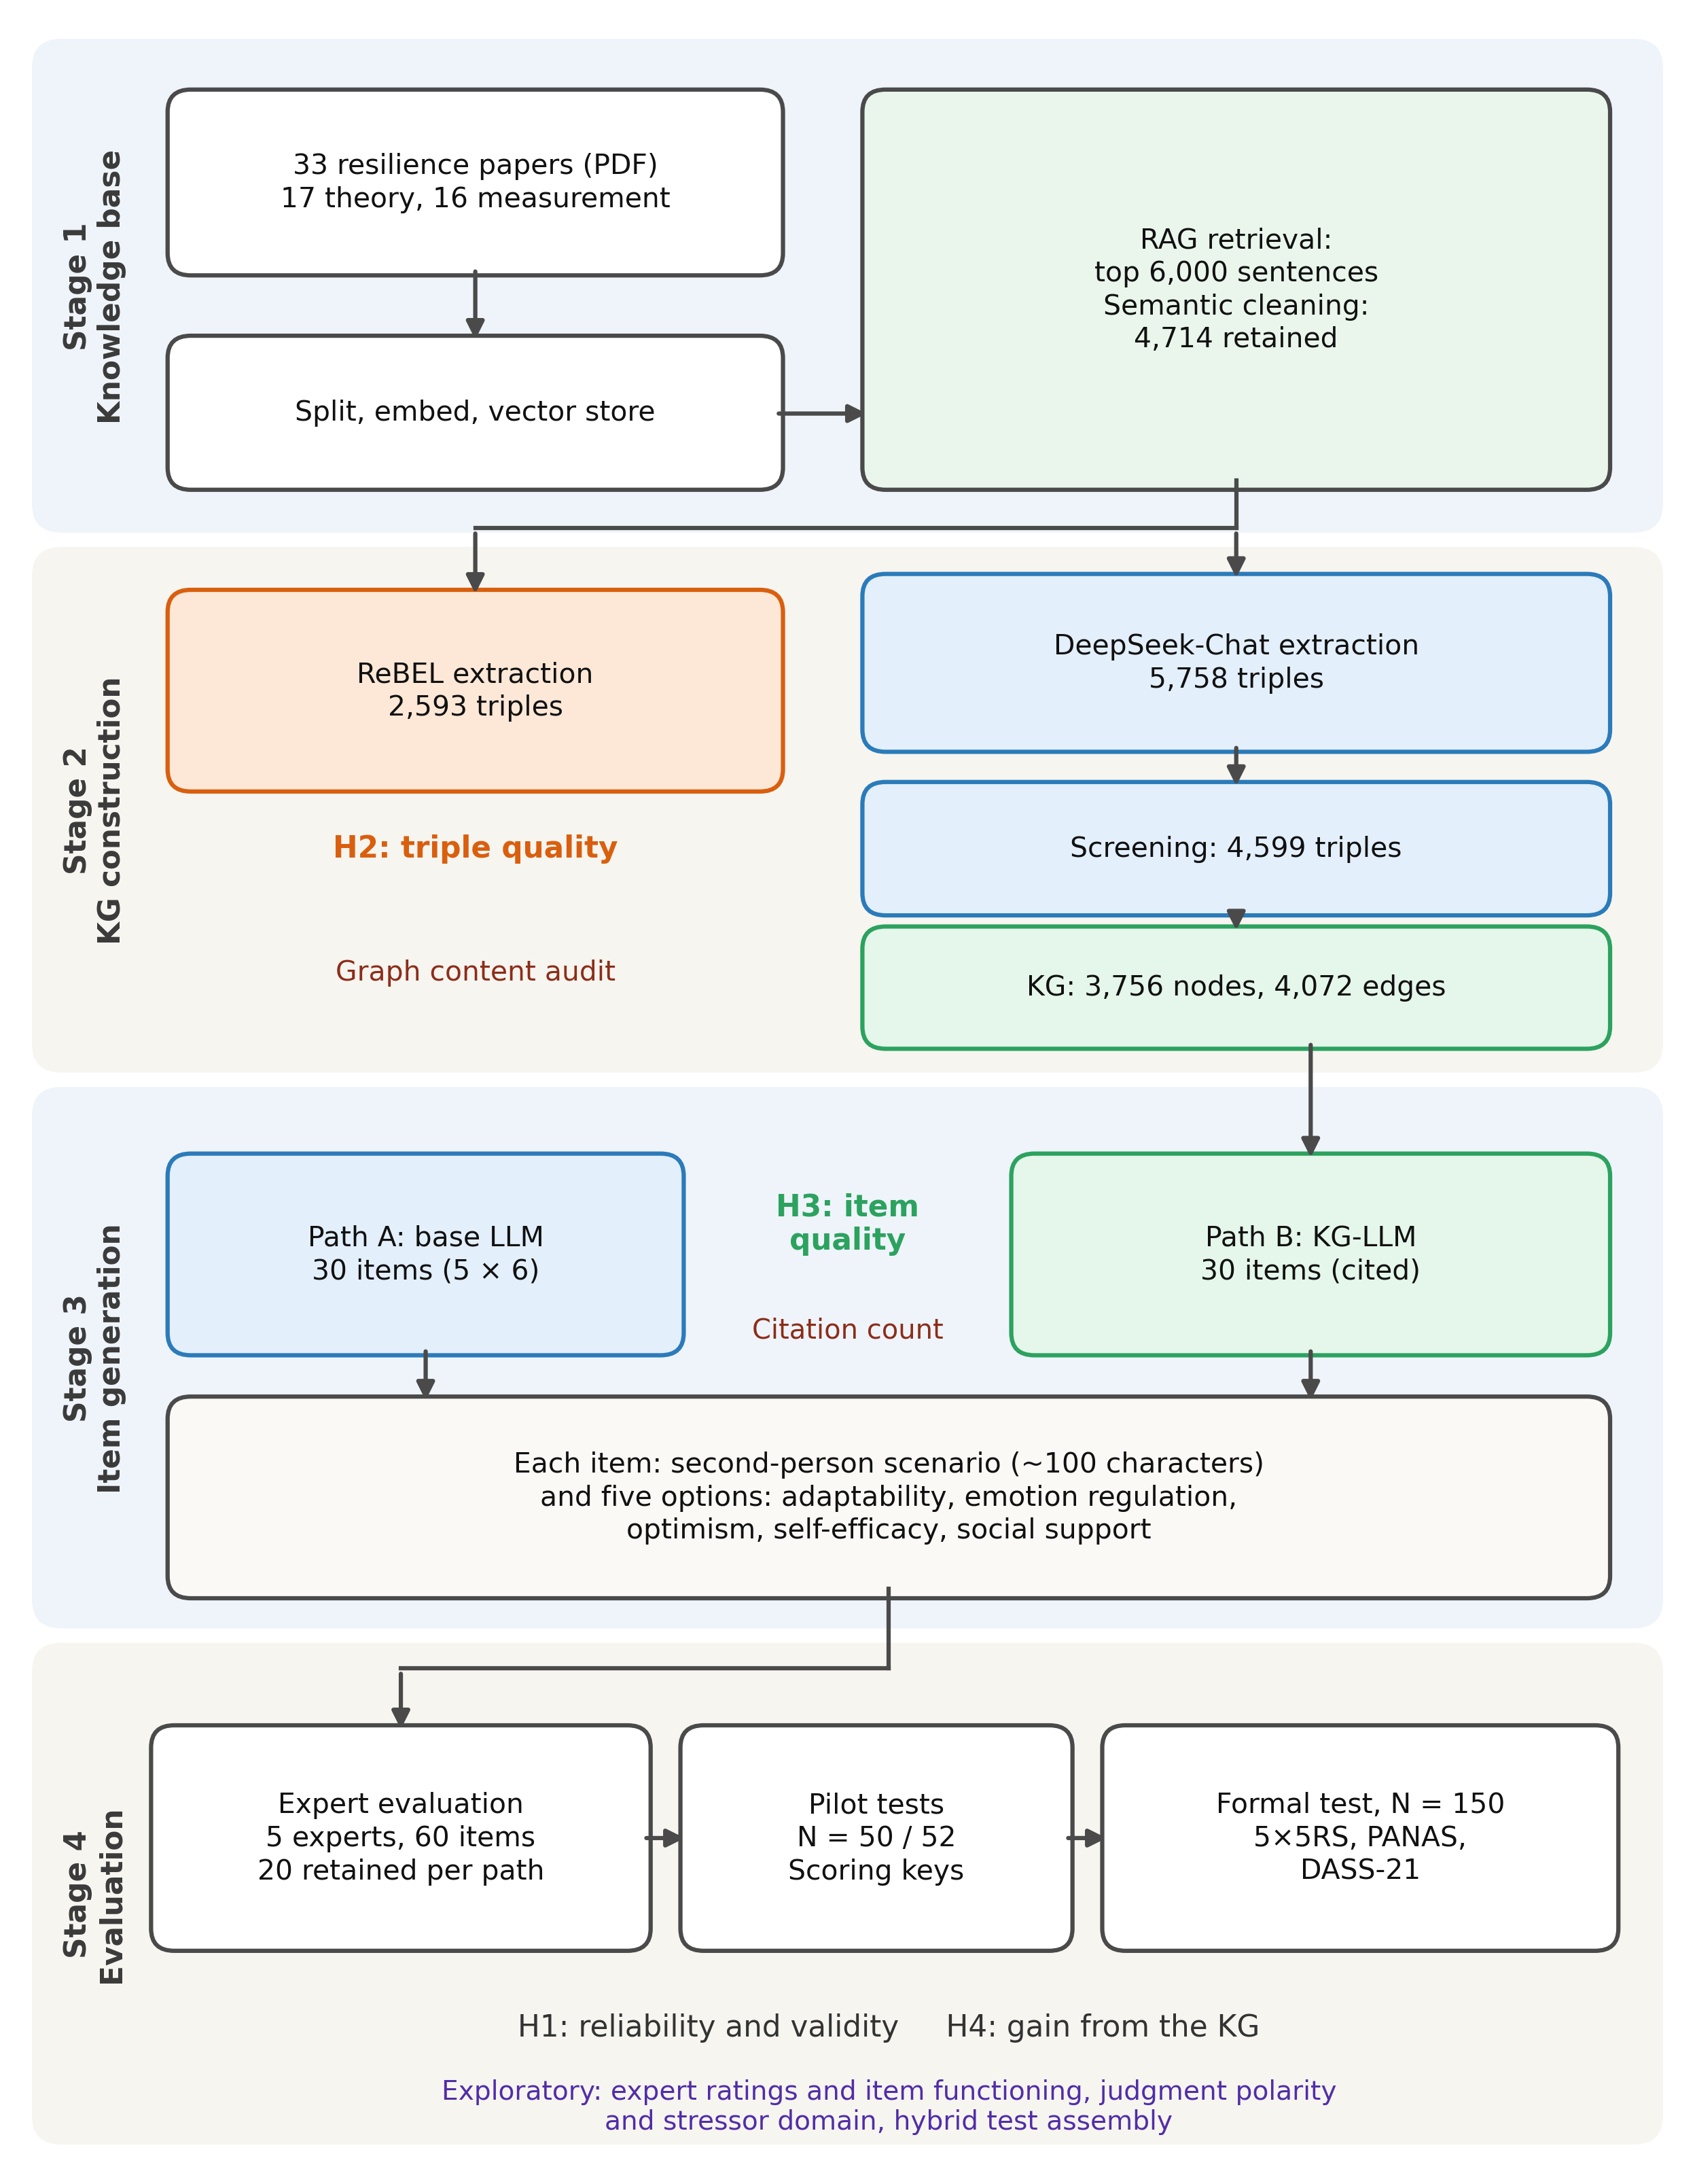

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "src").exists() and (REPO_ROOT.parent / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "src"))

import s00_prepare_data, s01_kg_network, s02_triple_quality, s03_scenario_quality
import s04_cvi_and_screening, s05_rater_error, s06_mixed_model, s07_reliability
import s08_validity, s09_pilot_and_entropy, s10_scenario_length
import s11_icc_ceiling_simulation, s12_hierarchical_regressions
import fig_part1, fig_part2, verify_reported_values
from utils_stats import RAW_DIR, FIG_DIR

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

results = {}
results["s00"] = s00_prepare_data.run()
results["s01"] = s01_kg_network.run()

print("=== Stage 0 Data Preparation & Sample Verification ===")
for k, v in results["s00"].items():
    print(f"  {k:28s}: {v}")

fig1_path = FIG_DIR / "fig01_pipeline_overview.png"
fig_part1.plot_fig01(results["s01"], fig1_path)
display(Image(filename=str(fig1_path), width=620))

## 2. Stage 1–2 Corpus, ReBEL–LLM Overlap, & Knowledge Graph Topology (`s01`; `Figures 3, C1, C2`)

=== ReBEL vs. DeepSeek-Chat Output Overlap (§3.1.1) ===
         level  rebel_unique  llm_unique  shared  jaccard     dice  szymkiewicz_simpson
      entities          3118        4145     636 0.095971 0.175134             0.203977
subject_object          2141        4633     139 0.020950 0.041039             0.064923
  exact_triple          2150        4910       9 0.001276 0.002550             0.004186

=== Ontology Granularity Audit (§3.1.3 & Appendix F.1) ===
  Nodes   (3,756): Strict = 693 (18.5%) | Broad = 926 (24.7%)
  Seeds      (30): Strict = 5 (16.7%) | Broad = 8 (26.7%)
  Triples (4,265): Strict = 1512 (35.5%) | Broad = 1920 (45.0%)

=== Table C1: Network-Level Statistics ===
                                          Indicator      Value
          Original triples (after manual screening) 4599.00000
         Unique triples after frequency aggregation 4265.00000
                                    Number of nodes 3756.00000
       Number of directed edges (unique node pairs) 

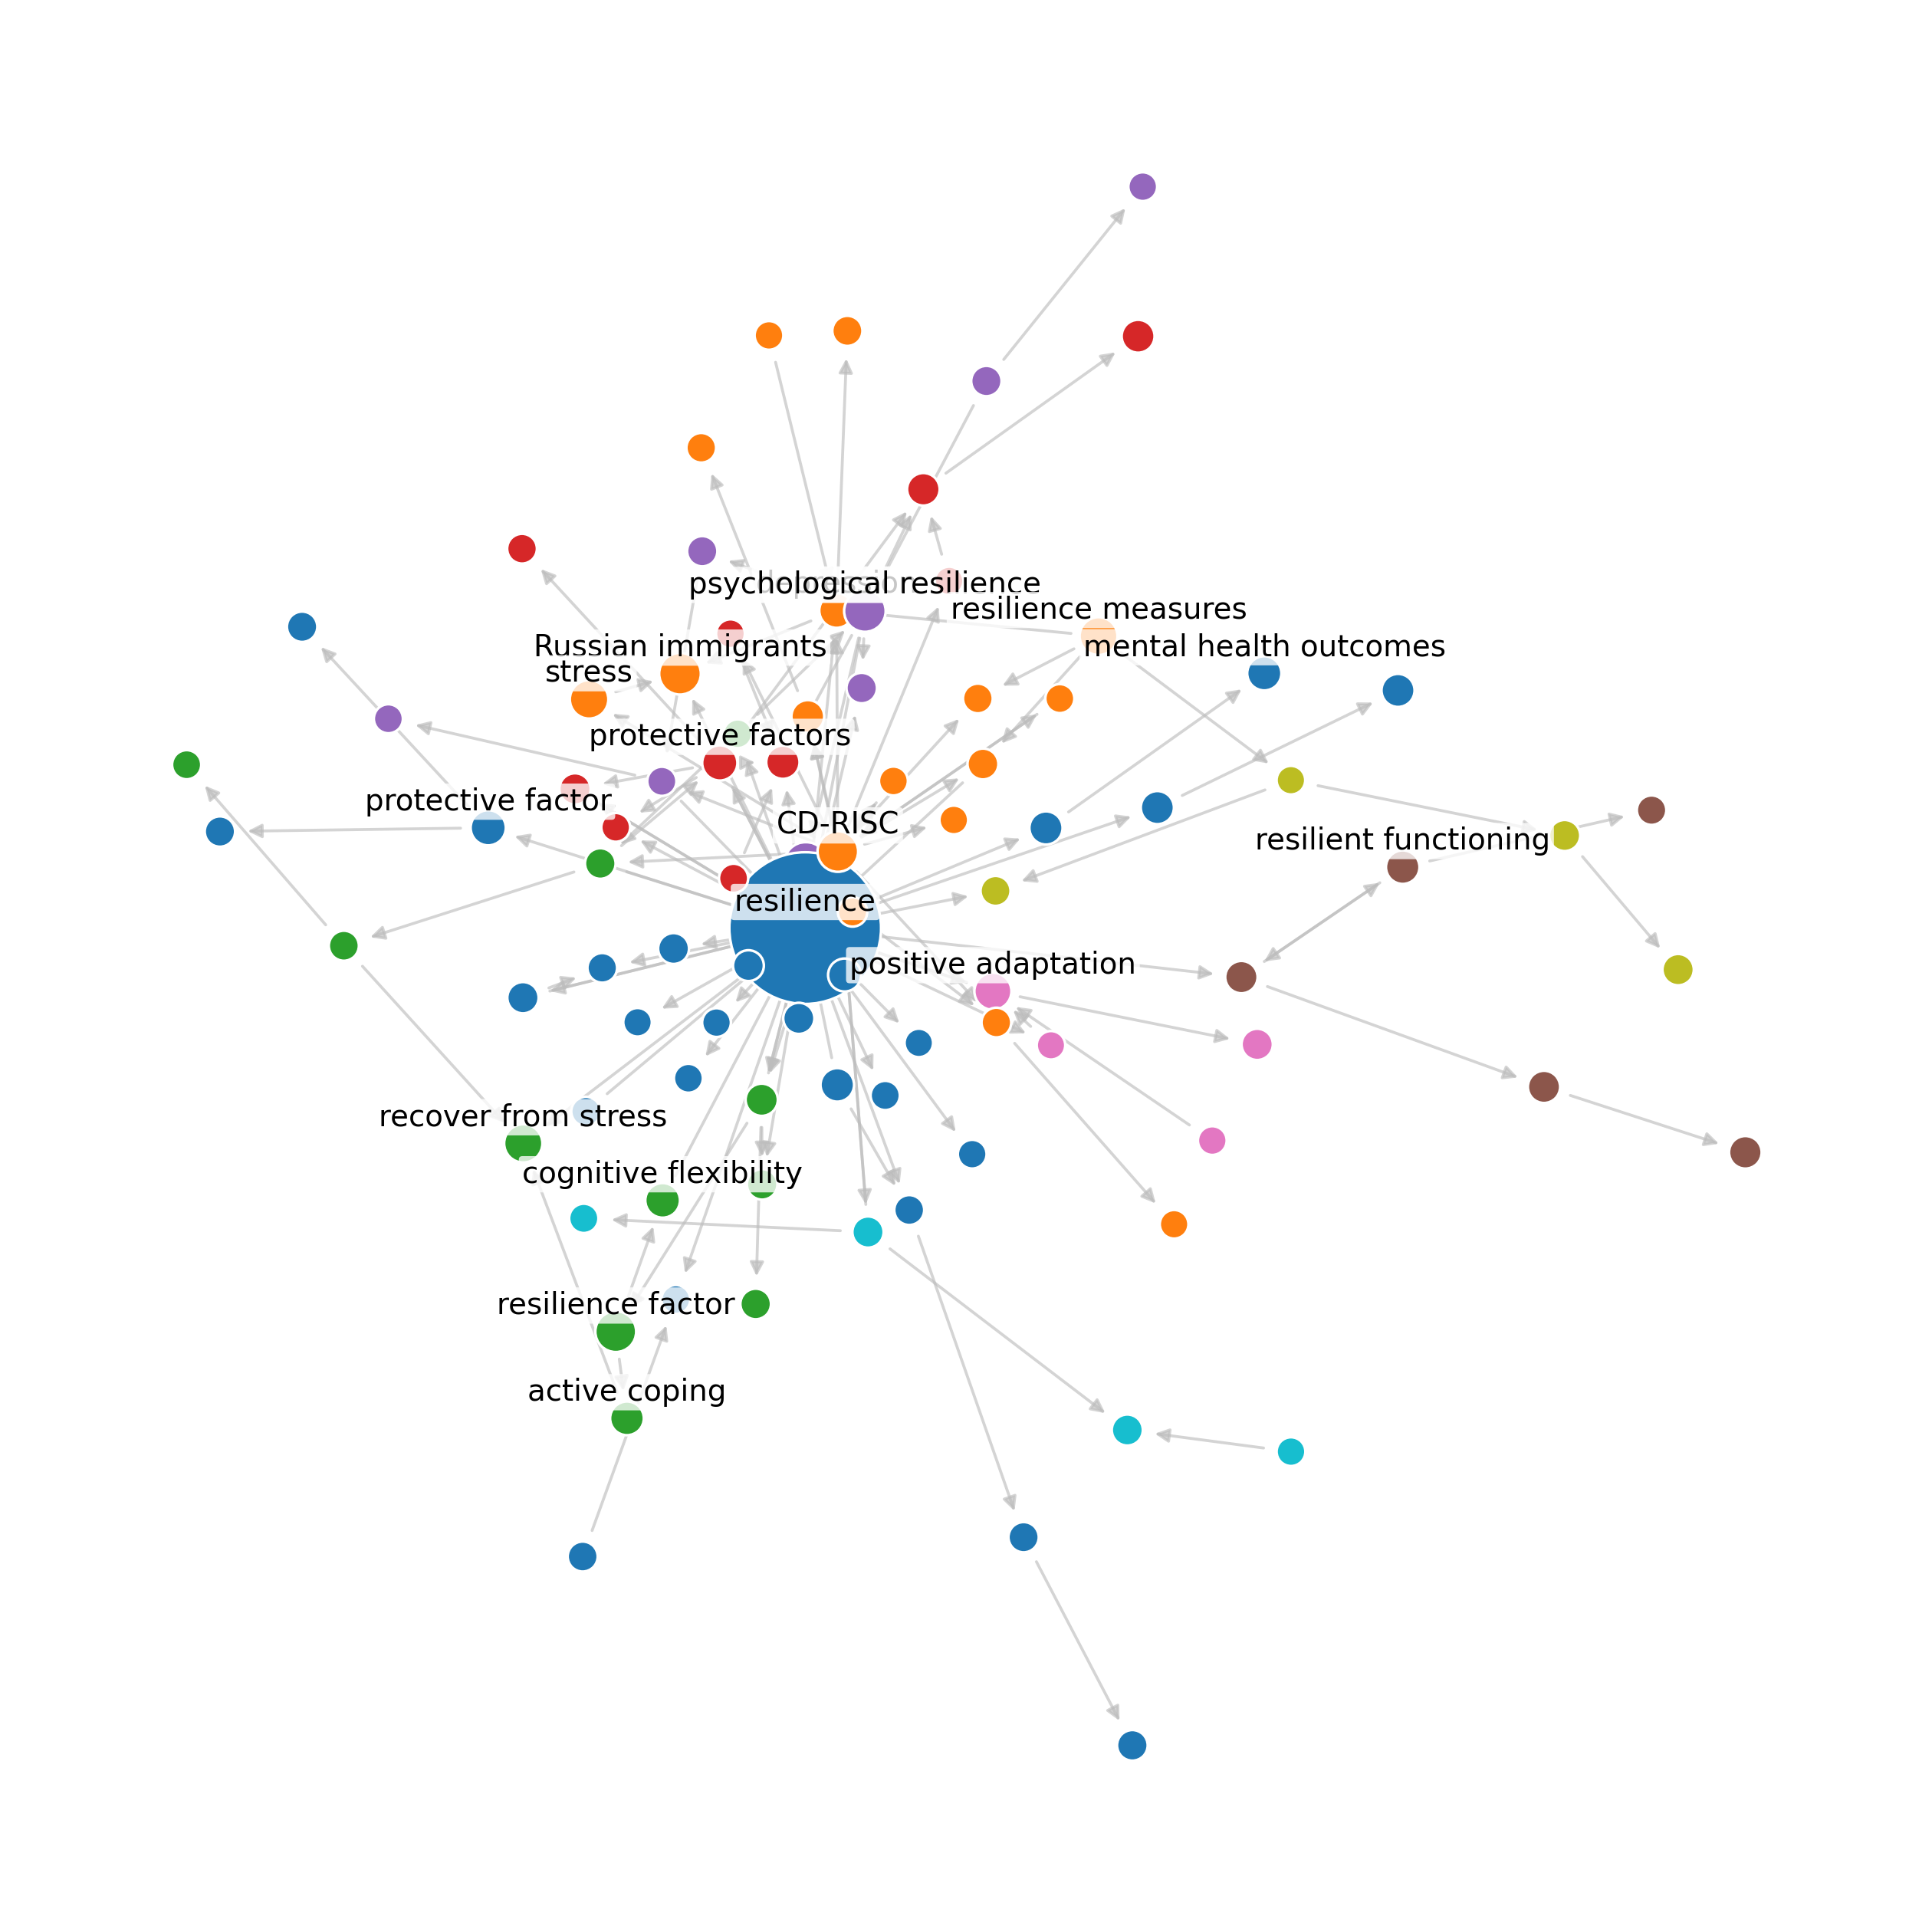

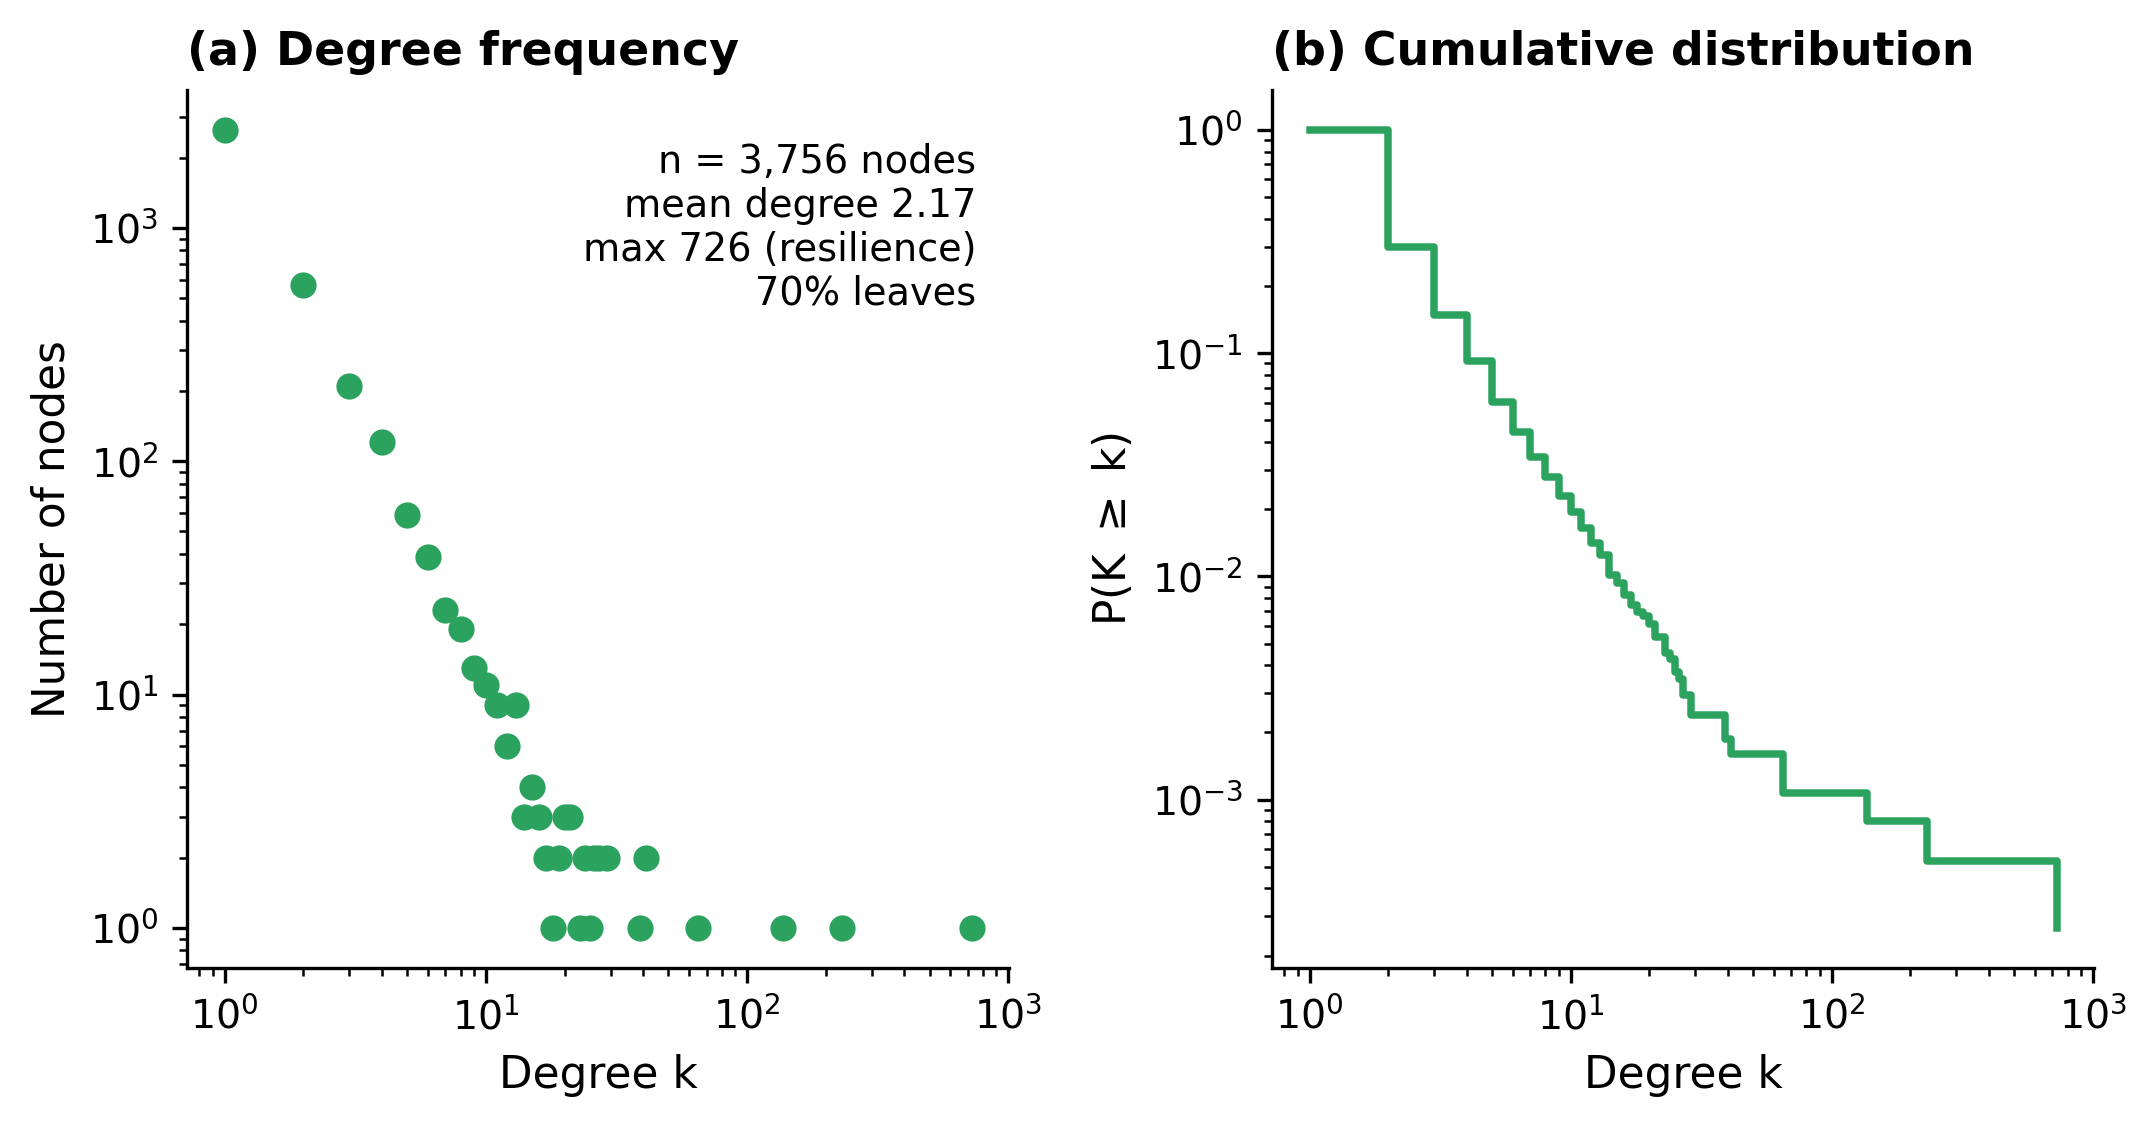

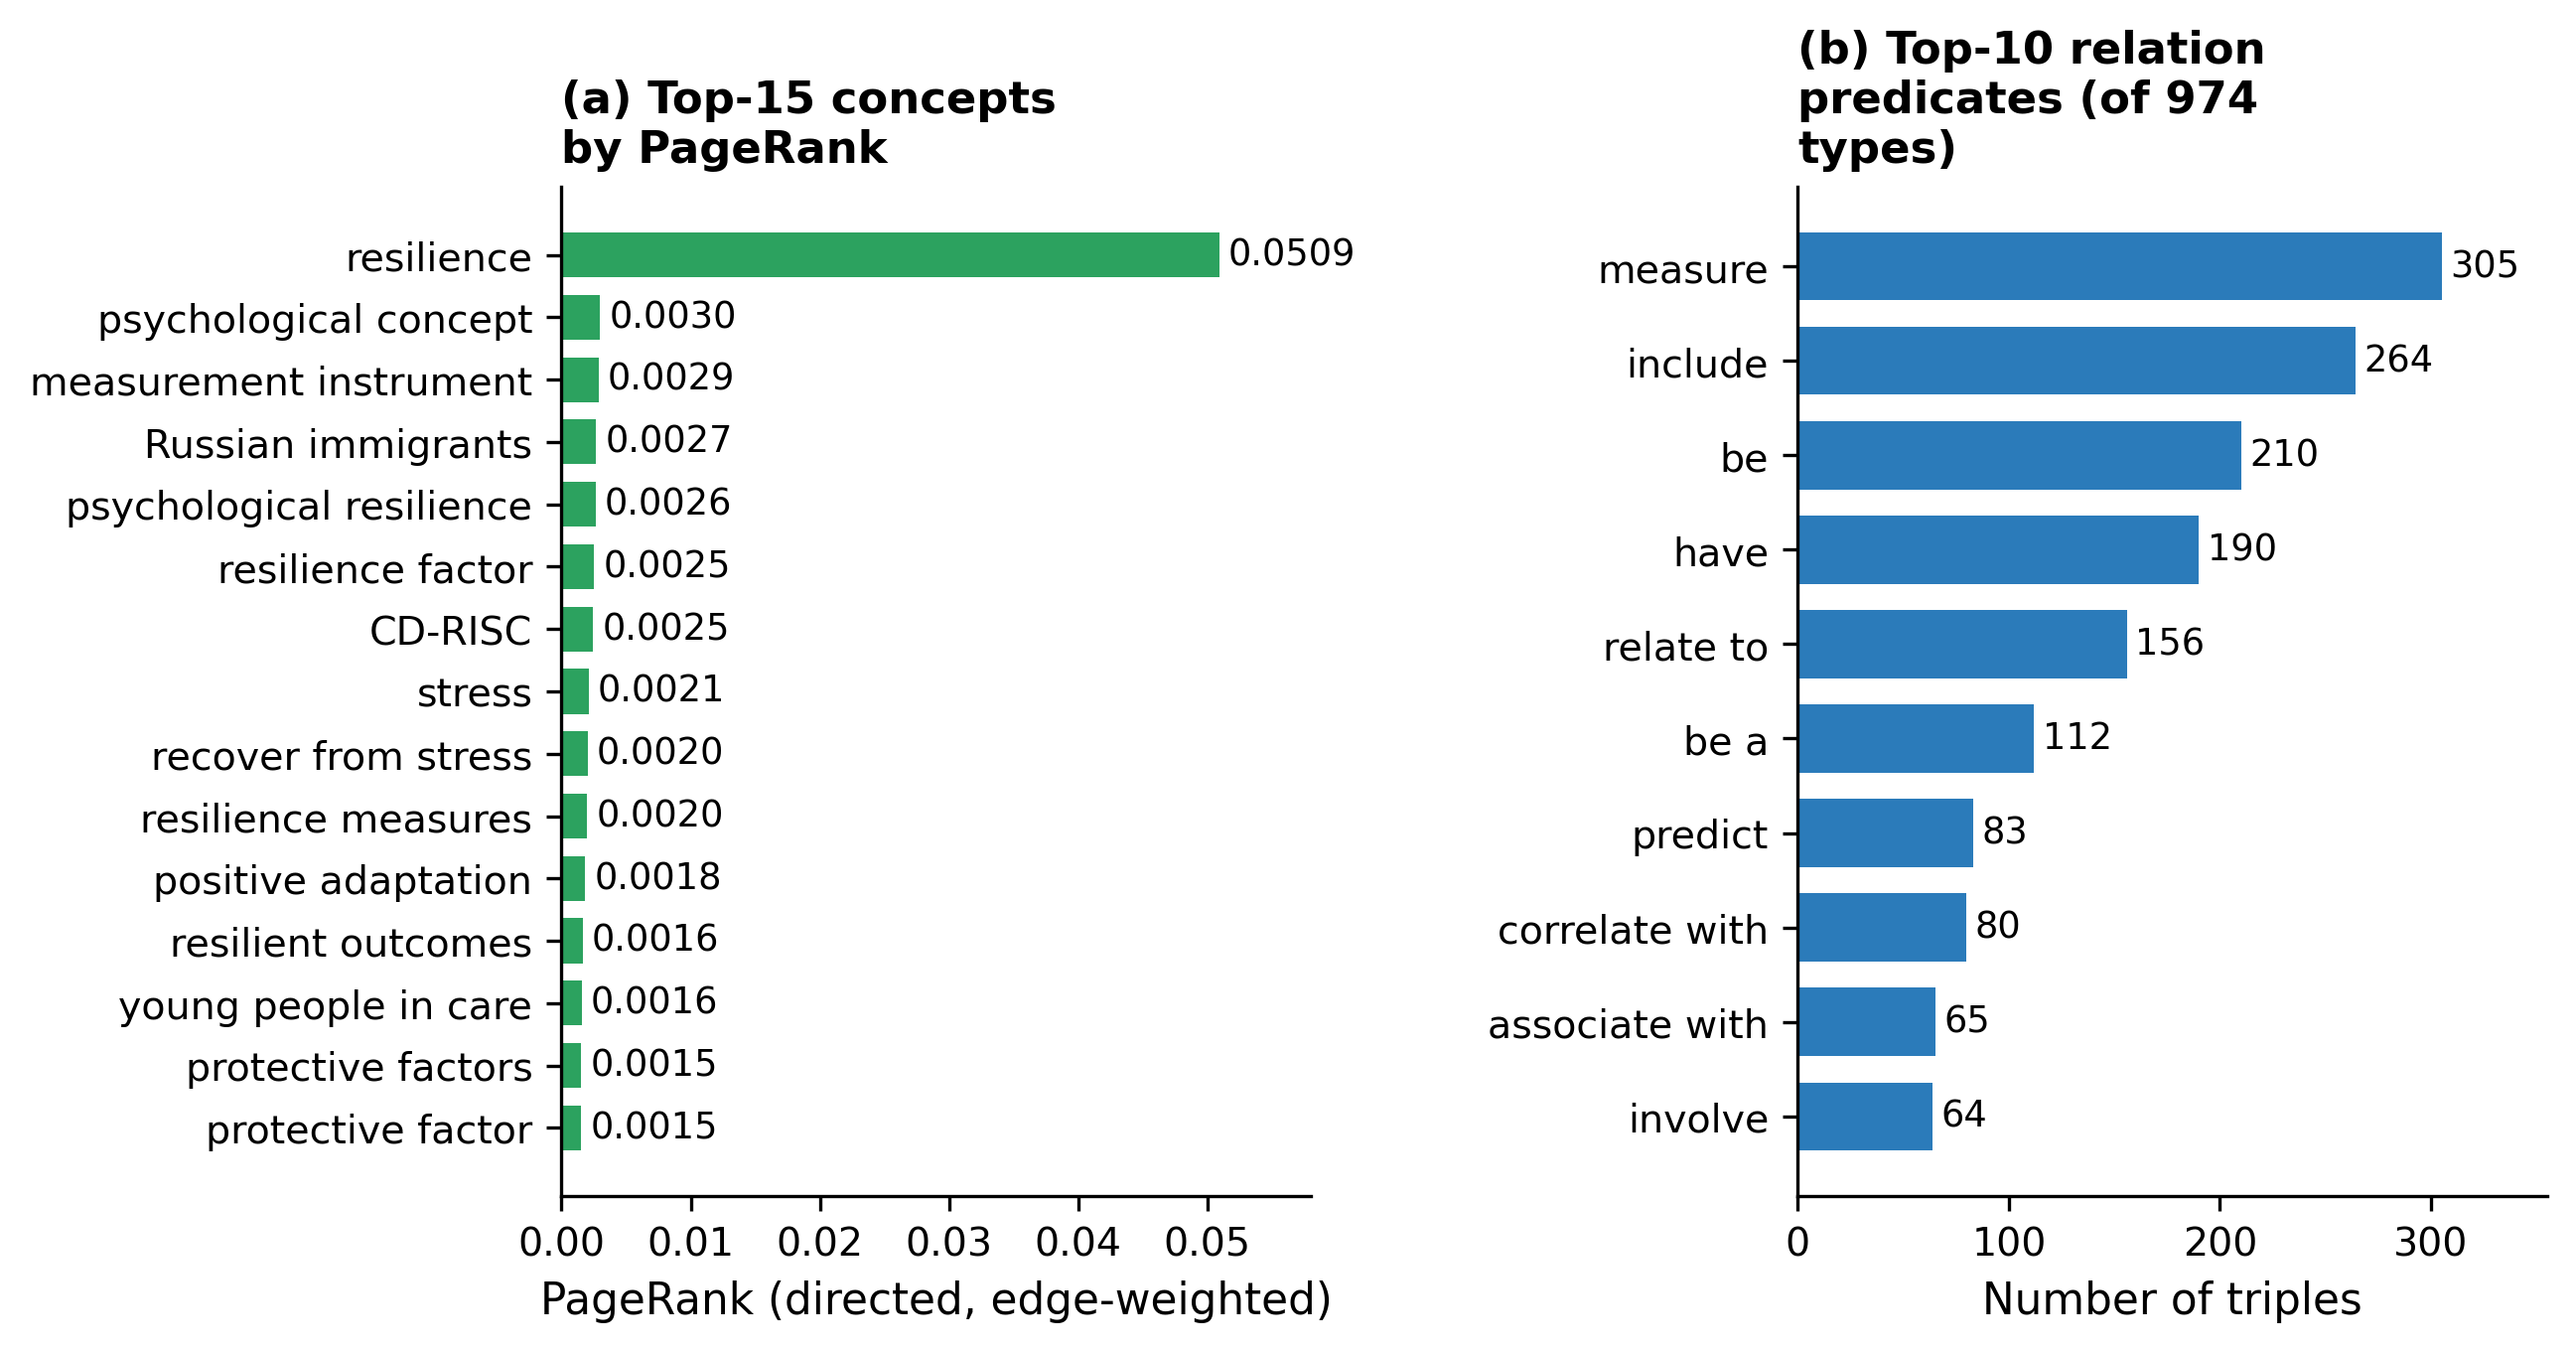

In [2]:
r1 = results["s01"]
print("=== ReBEL vs. DeepSeek-Chat Output Overlap (§3.1.1) ===")
print(r1["overlap"].to_string(index=False))

print("\n=== Ontology Granularity Audit (§3.1.3 & Appendix F.1) ===")
print(f"  Nodes   (3,756): Strict = {r1['strict_nodes_n']} ({r1['strict_nodes_pct']:.1f}%) | Broad = {r1['broad_nodes_n']} ({r1['broad_nodes_pct']:.1f}%)")
print(f"  Seeds      (30): Strict = {r1['strict_seeds_n']} ({r1['strict_seeds_pct']:.1f}%) | Broad = {r1['broad_seeds_n']} ({r1['broad_seeds_pct']:.1f}%)")
print(f"  Triples (4,265): Strict = {r1['strict_triples_n']} ({r1['strict_triples_pct']:.1f}%) | Broad = {r1['broad_triples_n']} ({r1['broad_triples_pct']:.1f}%)")

print("\n=== Table C1: Network-Level Statistics ===")
print(r1["table_c1"].to_string(index=False))

print("\n=== Table C2: Top-15 Core Nodes by PageRank ===")
print(r1["table_c2"][["rank", "node", "pagerank", "total_degree", "in_degree", "out_degree"]].round(4).to_string(index=False))

print("\n=== Table C3: Top-10 High-Frequency Relation Predicates ===")
print(r1["table_c3"].to_string(index=False))

fig3_path = FIG_DIR / "fig03_kg_core_subgraph.png"
figC1_path = FIG_DIR / "figC1_kg_degree_distribution.png"
figC2_path = FIG_DIR / "figC2_core_nodes_and_predicates.png"
fig_part1.plot_fig03(RAW_DIR, fig3_path)
fig_part2.plot_figC1(RAW_DIR, r1, figC1_path)
fig_part2.plot_figC2(r1, figC2_path)

for p in (fig3_path, figC1_path, figC2_path):
    display(Image(filename=str(p), width=680))

## 3. Stage 2 Triple Extraction Quality Validation (`H2`; `s02`, `Figure 2`)

=== Appendix D.1: Triple Interrater Agreement (ICC(3,k) & Gwet's AC2) ===
model           dimension  icc3k  icc_ci_low  icc_ci_high     F  df1  df2  p_icc   ac2  ac2_ci_low  ac2_ci_high
  LLM         correctness  0.511       0.333        0.651 2.044   99  297  0.000 0.448       0.321        0.575
ReBEL         correctness  0.812       0.744        0.866 5.321   99  297  0.000 0.895       0.852        0.931
  LLM           relevance  0.585       0.434        0.703 2.408   99  297  0.000 0.474       0.336        0.598
ReBEL           relevance  0.741       0.648        0.815 3.868   99  297  0.000 0.538       0.440        0.637
  LLM        completeness  0.531       0.360        0.665 2.130   99  297  0.000 0.266       0.132        0.395
ReBEL        completeness  0.782       0.703        0.844 4.591   99  297  0.000 0.884       0.837        0.921
  LLM clarity_conciseness  0.375       0.148        0.553 1.599   99  297  0.001 0.440       0.317        0.563
ReBEL clarity_conciseness  0.8

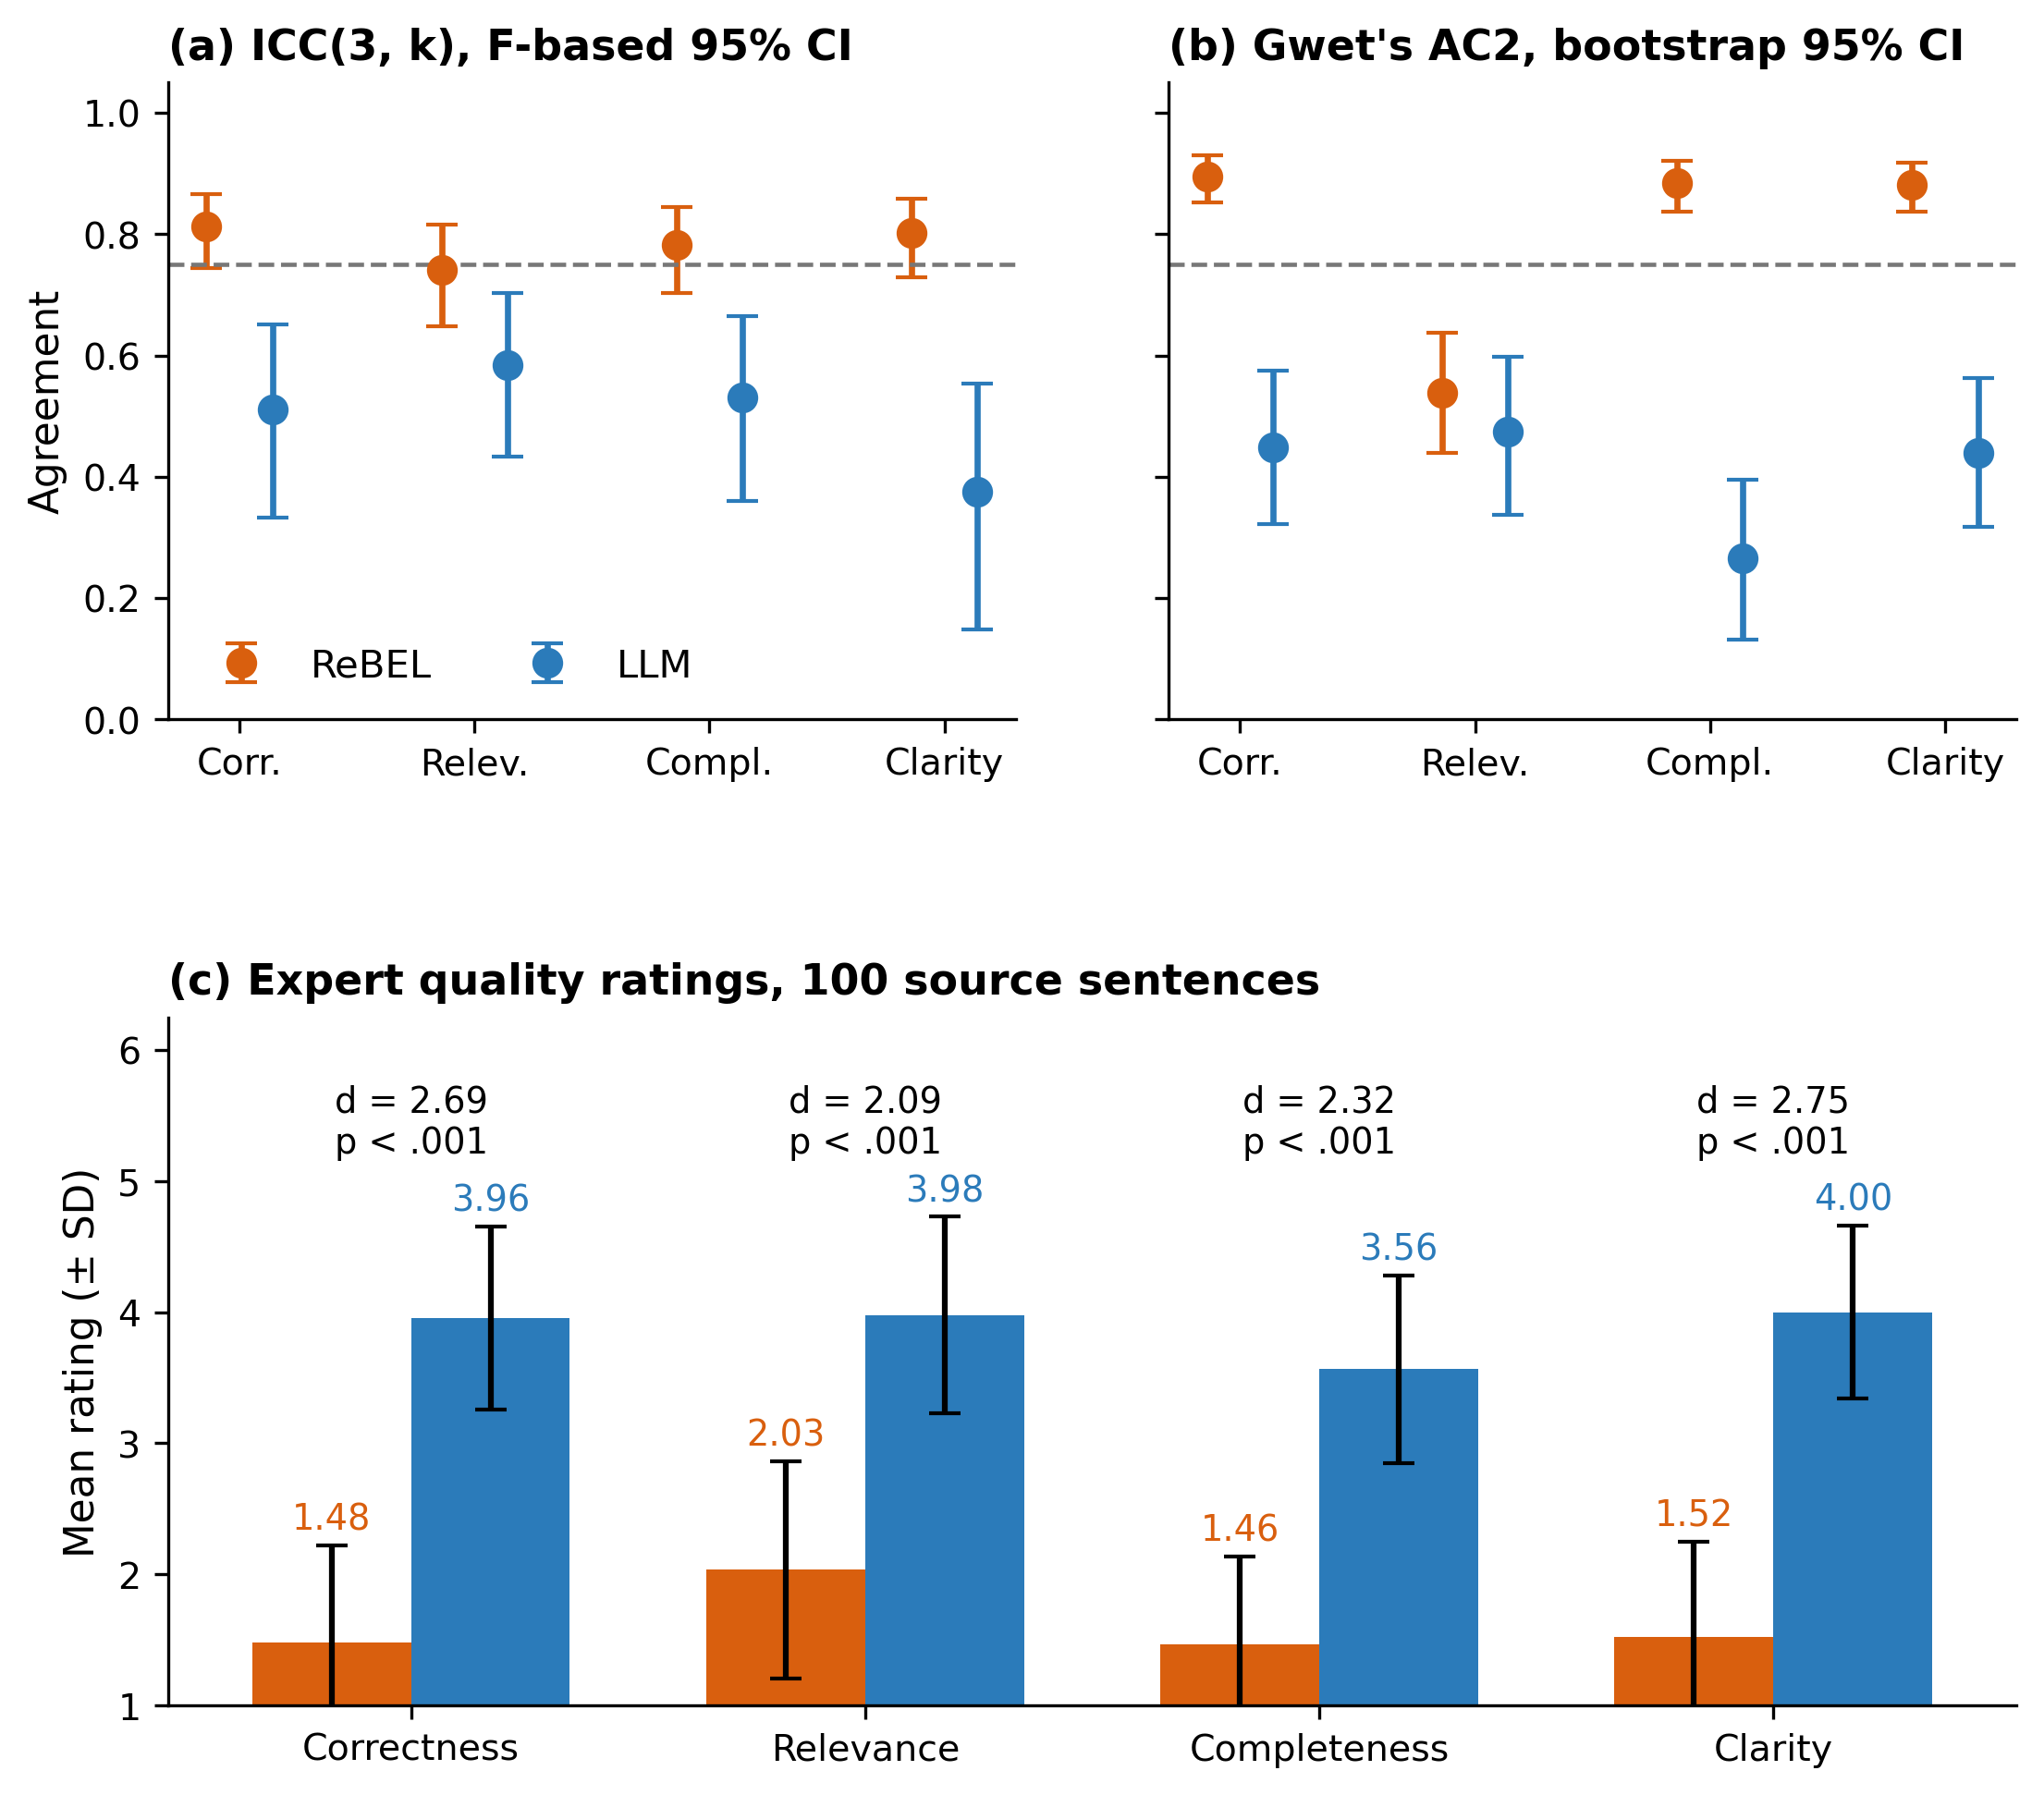

In [3]:
results["s02"] = s02_triple_quality.run()
r2 = results["s02"]

print("=== Appendix D.1: Triple Interrater Agreement (ICC(3,k) & Gwet's AC2) ===")
print(r2["agreement"].round(3).to_string(index=False))

print("\n=== Appendix D.2: Paired t-Tests & Cohen's d_z Across 100 Source Sentences (H2) ===")
print(r2["paired_tests"].round(4).to_string(index=False))

fig2_path = FIG_DIR / "fig02_triple_evaluation.png"
fig_part1.plot_fig02(r2, fig2_path)
display(Image(filename=str(fig2_path), width=680))

## 4. Stage 3–4 Scenario Evaluation, Citation-Count OLS, & Ceiling Simulations (`H3`; `s03, s05, s10, s11`, `Figures 4 & 5`)

=== H3 Scenario Quality, ICC(3,k), Gwet's AC2, & TOST (§3.2.1, Appendix D.3) ===
 dimension  kg_mean  base_mean  welch_t  welch_p  hedges_g  p_tost_05sd  icc_kg  icc_base  ac2_kg  ac2_base
   realism    4.207      4.393   -3.041    0.004    -0.775        0.863  -0.342    -0.336   0.754     0.867
 relevance    4.273      4.413   -1.649    0.105    -0.420        0.387   0.338     0.222   0.835     0.875
typicality    4.100      4.420   -3.180    0.003    -0.810        0.889   0.597    -0.369   0.747     0.894
   arousal    4.053      4.380   -3.454    0.001    -0.880        0.933   0.224     0.140   0.732     0.876

=== Table D2a: Two-Way ANOVA Rater-Error Mean Squares & Bootstrap Ratios ===
 dimension  ms_item_kg  ms_item_llm  ms_error_kg  ms_error_llm  mse_ratio  ratio_ci_low  ratio_ci_high  error_sd_kg  error_sd_llm
   realism       0.324        0.241        0.435         0.322      1.350         0.856          2.214        0.659         0.568
 relevance       0.696        0.385      

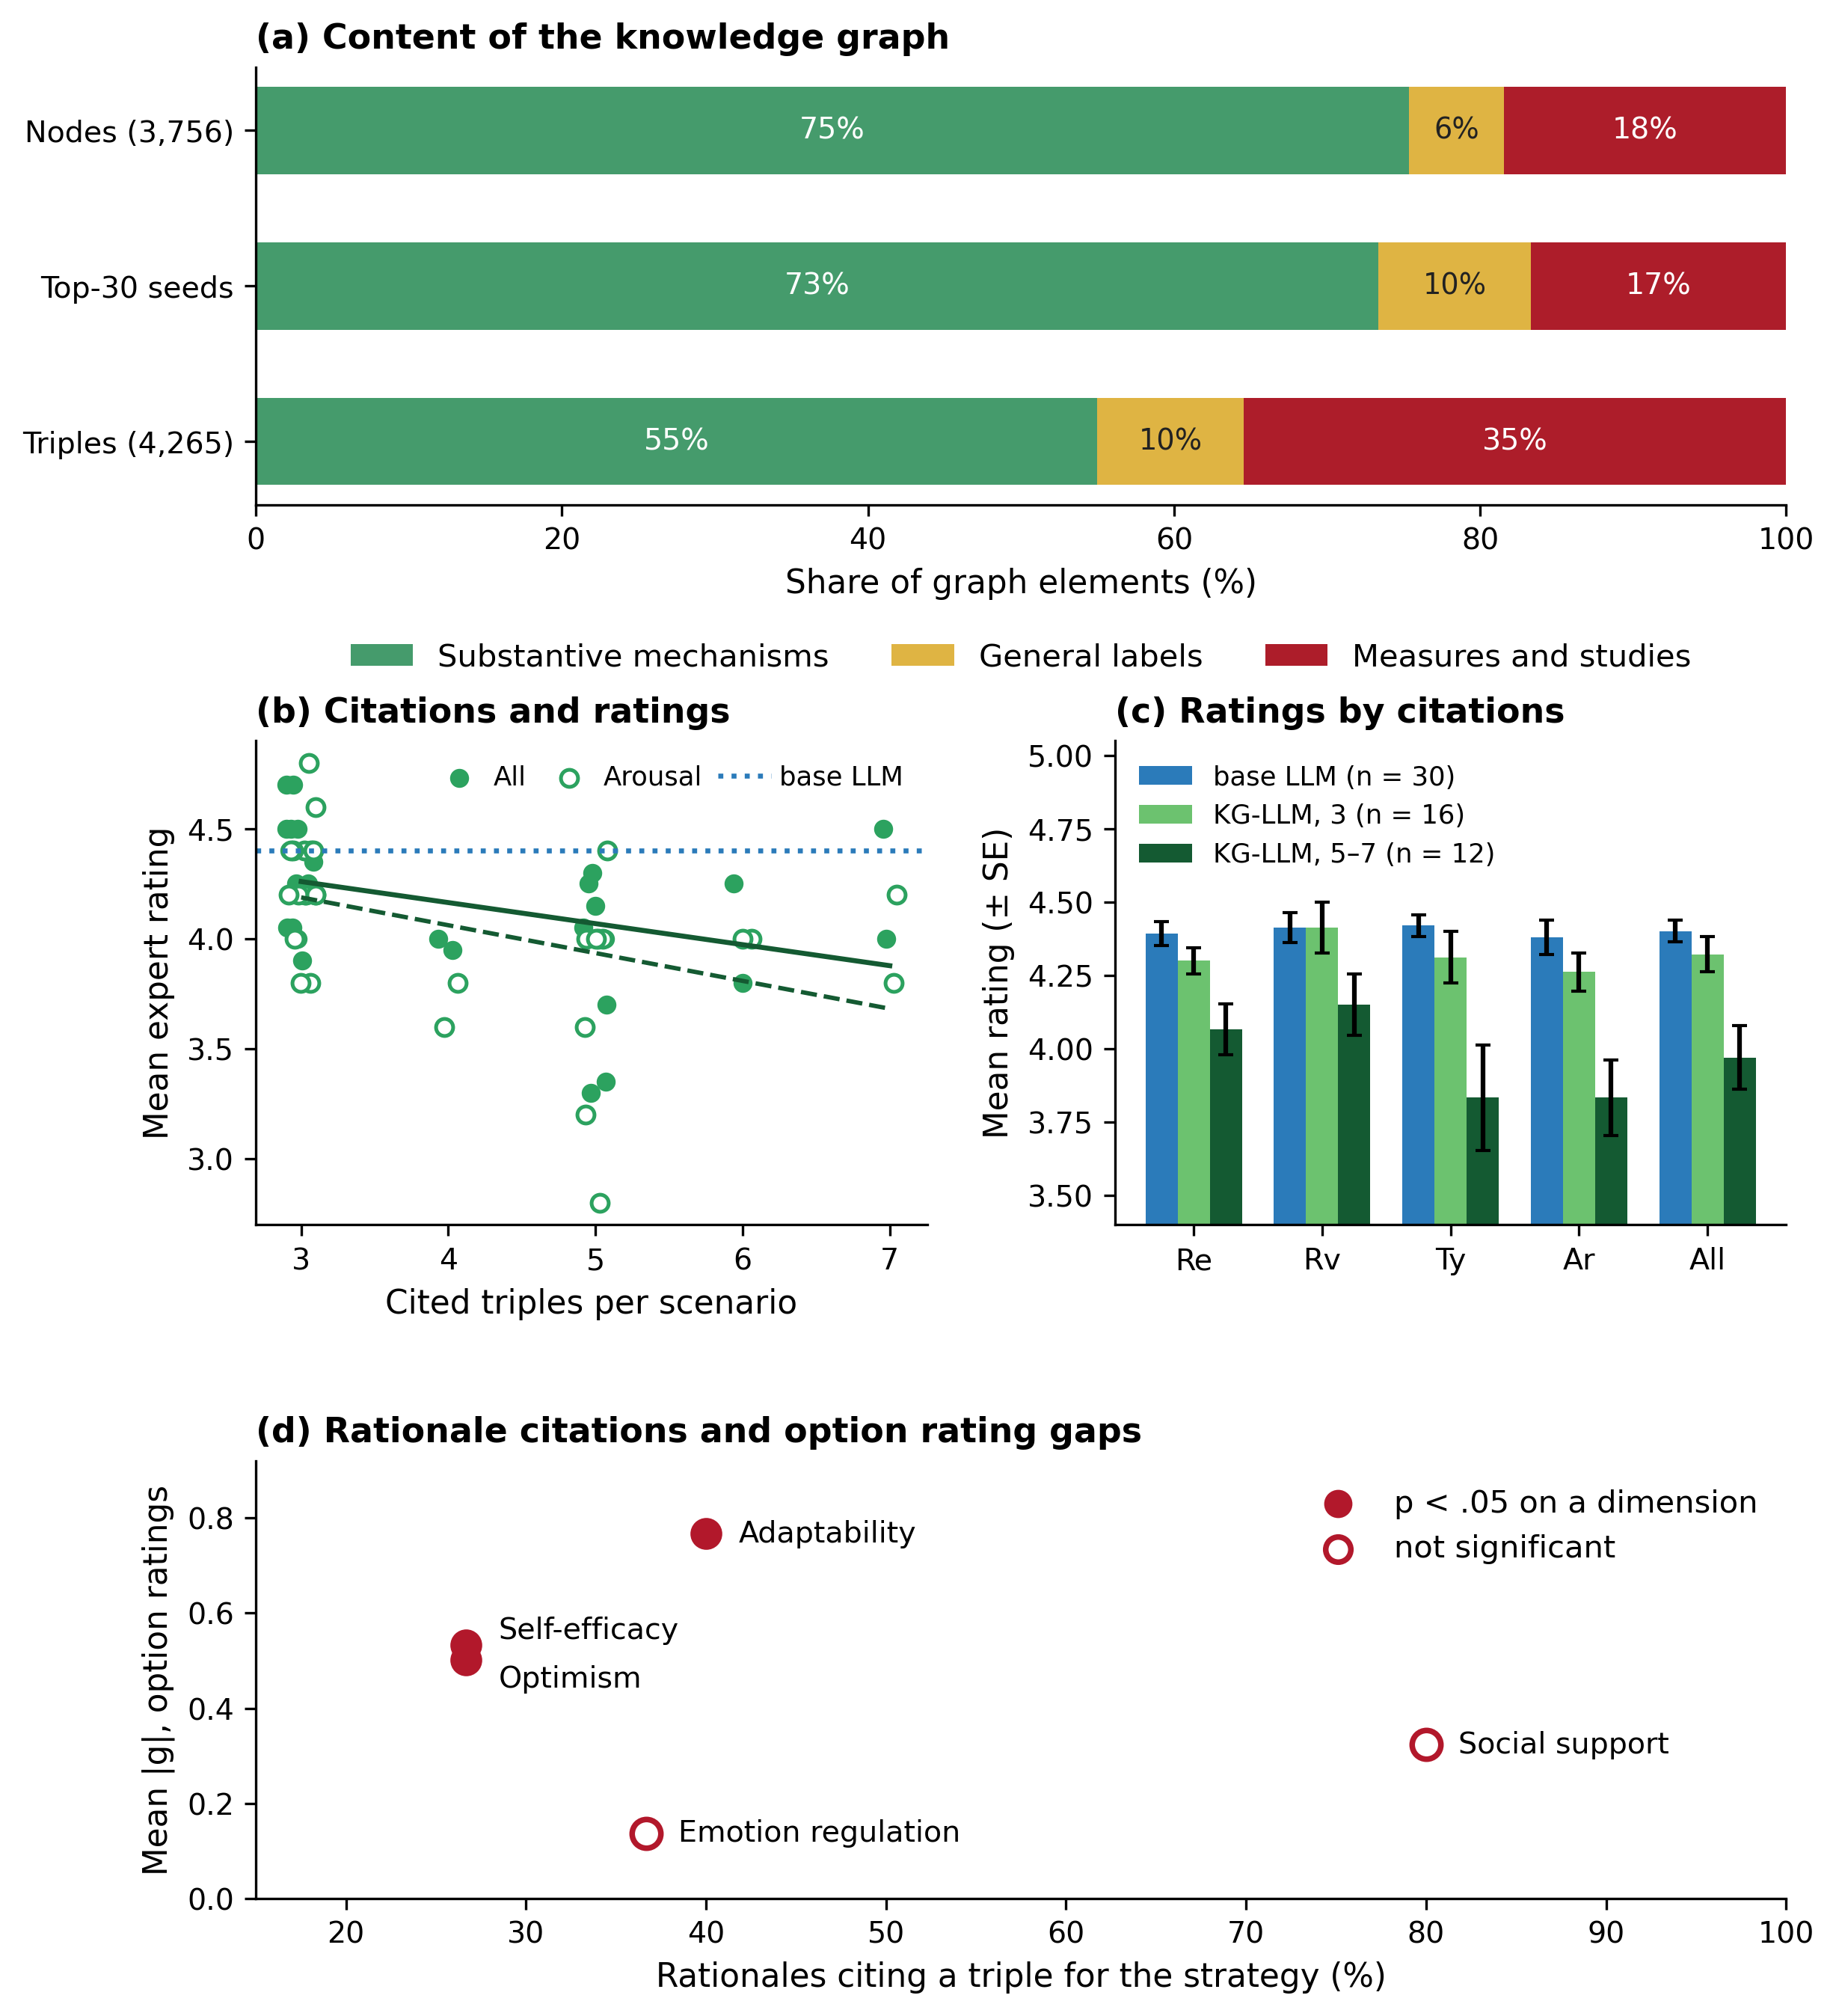

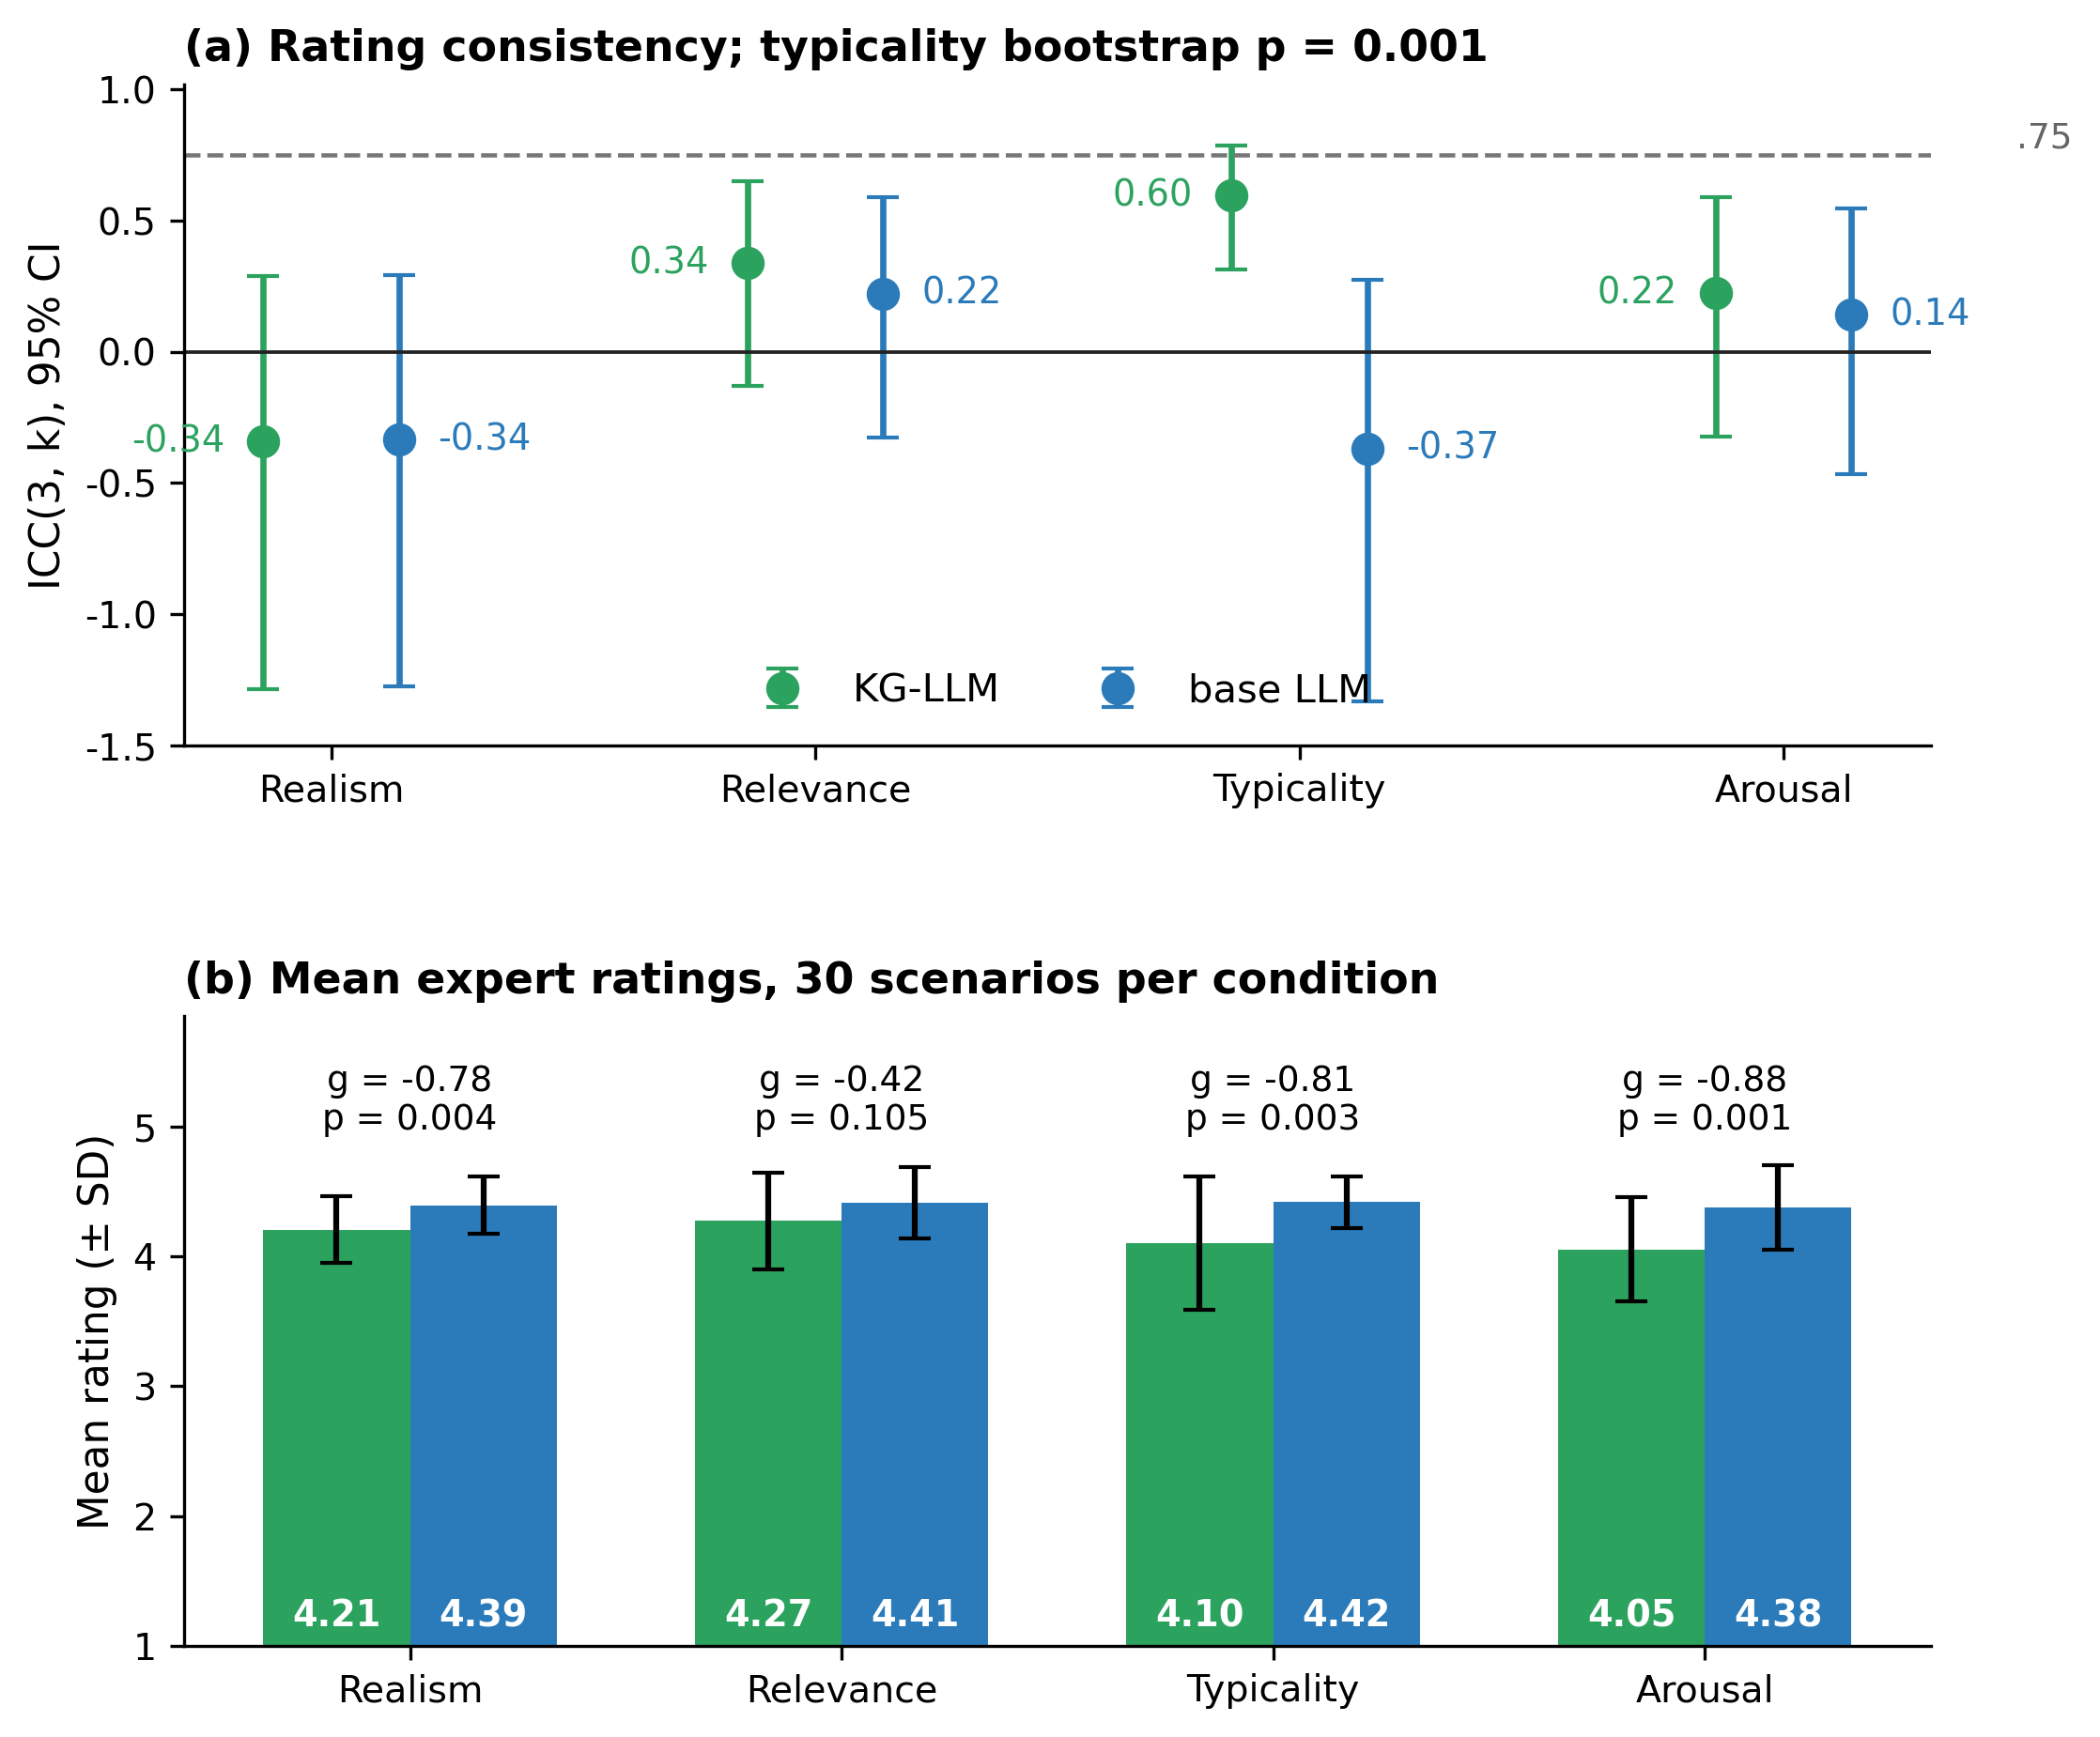

In [4]:
results["s03"] = s03_scenario_quality.run()
results["s04"] = s04_cvi_and_screening.run()
results["s05"] = s05_rater_error.run()
results["s10"] = s10_scenario_length.run()
results["s11"] = s11_icc_ceiling_simulation.run()

r3, r4, r5, r10, r11 = results["s03"], results["s04"], results["s05"], results["s10"], results["s11"]

print("=== H3 Scenario Quality, ICC(3,k), Gwet's AC2, & TOST (§3.2.1, Appendix D.3) ===")
cols_s3 = ["dimension", "kg_mean", "base_mean", "welch_t", "welch_p", "hedges_g", "p_tost_05sd", "icc_kg", "icc_base", "ac2_kg", "ac2_base"]
print(r3["scenario_table"][cols_s3].round(3).to_string(index=False))

print("\n=== Table D2a: Two-Way ANOVA Rater-Error Mean Squares & Bootstrap Ratios ===")
print(r5.round(3).to_string(index=False))

cit = r3["citation_analysis"]
print("\n=== Observational Citation-Count Analysis & Controlled OLS (§3.2.1.3) ===")
print(f"  Cited triples per KG item : M = {cit['n_triples_mean']:.2f}, SD = {cit['n_triples_sd']:.2f} (3: n={cit['count_3']}, 4: n={cit['count_4']}, 5-7: n={cit['count_5_7']})")
print(f"  Bivariate r(NTriples, Scen) = {cit['r_ntriples_scen']:.3f} (p = {cit['p_ntriples_scen']:.3f}) | r(NTriples, Arousal) = {cit['r_ntriples_arousal']:.3f} (p = {cit['p_ntriples_arousal']:.3f})")
print(f"  3-triple KG vs. base LLM  : g = {cit['wt_3_vs_base_scen']['hedges_g']:.2f} (p = {cit['wt_3_vs_base_scen']['p']:.3f}, TOST p = {cit['tost_3_vs_base_scen_p']:.3f})")
print(f"  Controlled OLS (df = {cit['ols_df_resid']}) : b = {cit['ols_b_ntriples_scen']:.3f}, SE = {cit['ols_se_ntriples_scen']:.3f}, t = {cit['ols_t_ntriples_scen']:.2f}, p = {cit['ols_p_ntriples_scen']:.3f}")

print("\n=== ICC Ceiling Simulations (§3.2.1.5, Appendix F.4) & Scenario Length (§4.2) ===")
print(f"  Normal-rounding simulation: Cond A mean ICC = {r11['param_condA_mean_icc']:.3f} vs. Cond B = {r11['param_condB_mean_icc']:.3f}")
print(f"  Empirical base-LLM ceiling null (10,000 reps): {r11['emp_neg_icc_pct']:.1f}% negative ICC (Mdn = {r11['emp_median_icc']:.3f})")
print(f"  Scenario length (chars)   : KG M = {r10['scen_len']['m1']:.1f} vs. base LLM M = {r10['scen_len']['m2']:.1f} (t = {r10['scen_len']['t']:.2f}, g = {r10['scen_len']['hedges_g']:.2f})")

fig4_path = FIG_DIR / "fig04_kg_content_and_citations.png"
fig5_path = FIG_DIR / "fig05_scenario_evaluation.png"
fig_part1.plot_fig04(results["s01"], r3, r4, RAW_DIR, fig4_path)
fig_part1.plot_fig05(r3, fig5_path)
display(Image(filename=str(fig4_path), width=680))
display(Image(filename=str(fig5_path), width=680))

## 5. Content Validity, 30-to-20 Screening, Option Quality ANOVA, & Mixed-Effects Model (`s04, s06`, `Figures 6, 7, 8`)

=== Scenario Content Validity Index (S-CVI/Ave) & Item-Level Mann-Whitney U ===
 dimension  scvi_ave_kg  scvi_ave_base
   realism        0.807          0.913
 relevance        0.840          0.900
typicality        0.760          0.940
   arousal        0.747          0.900
   overall        0.788          0.913
  Item-level I-CVI Mann-Whitney U = 230.0, p = 0.001059
  Leave-one-rater-out jackknife screening overlap = 93.0% (KG: 96.0%, base: 90.0%)

=== Table D2b: Per-Rater Option Quality Across 5 Coping Strategies (3,000 Ratings) ===
          strategy       dimension  ms_error_kg  ms_error_base  mse_ratio  kg_mean  base_mean  welch_t  welch_p  hedges_g  scvi_kg  scvi_base
      Adaptability      Typicality        0.258          0.080      3.217    4.347      4.520   -3.271    0.002    -0.834    0.867      0.980
      Adaptability Distinctiveness        0.288          0.198      1.455    4.280      4.440   -2.743    0.008    -0.699    0.833      0.927
Emotion_Regulation      Typicalit

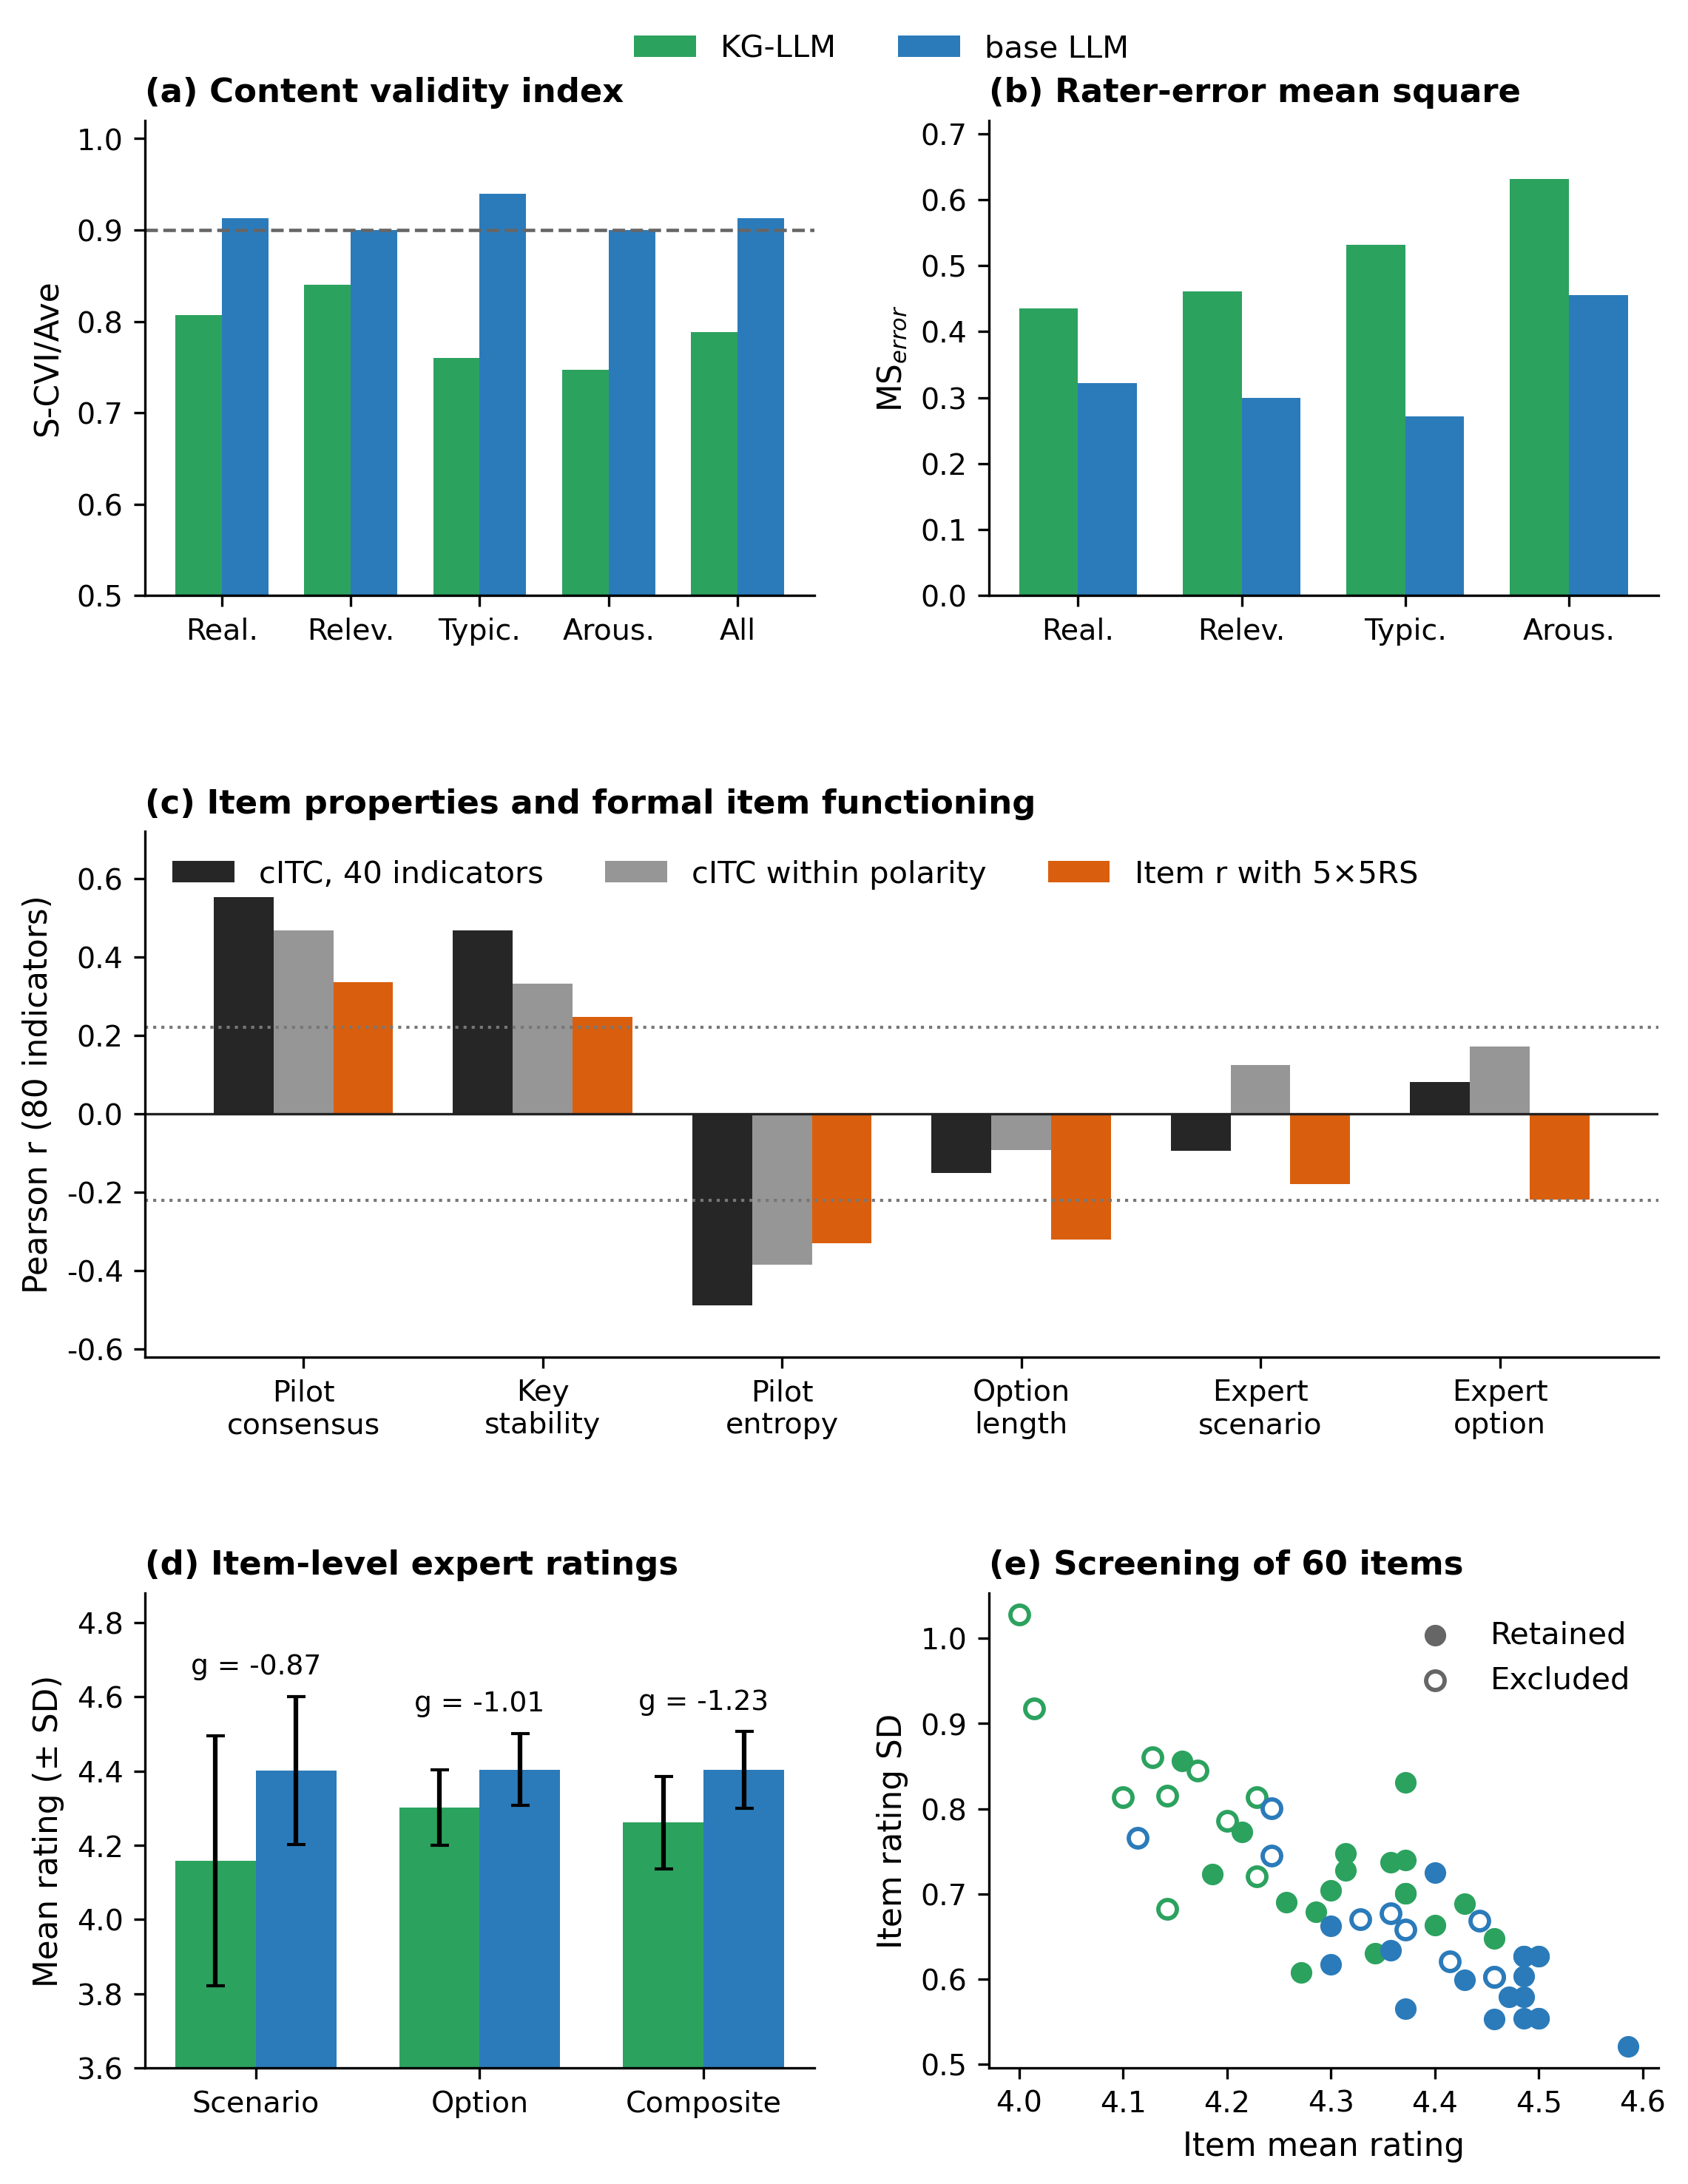

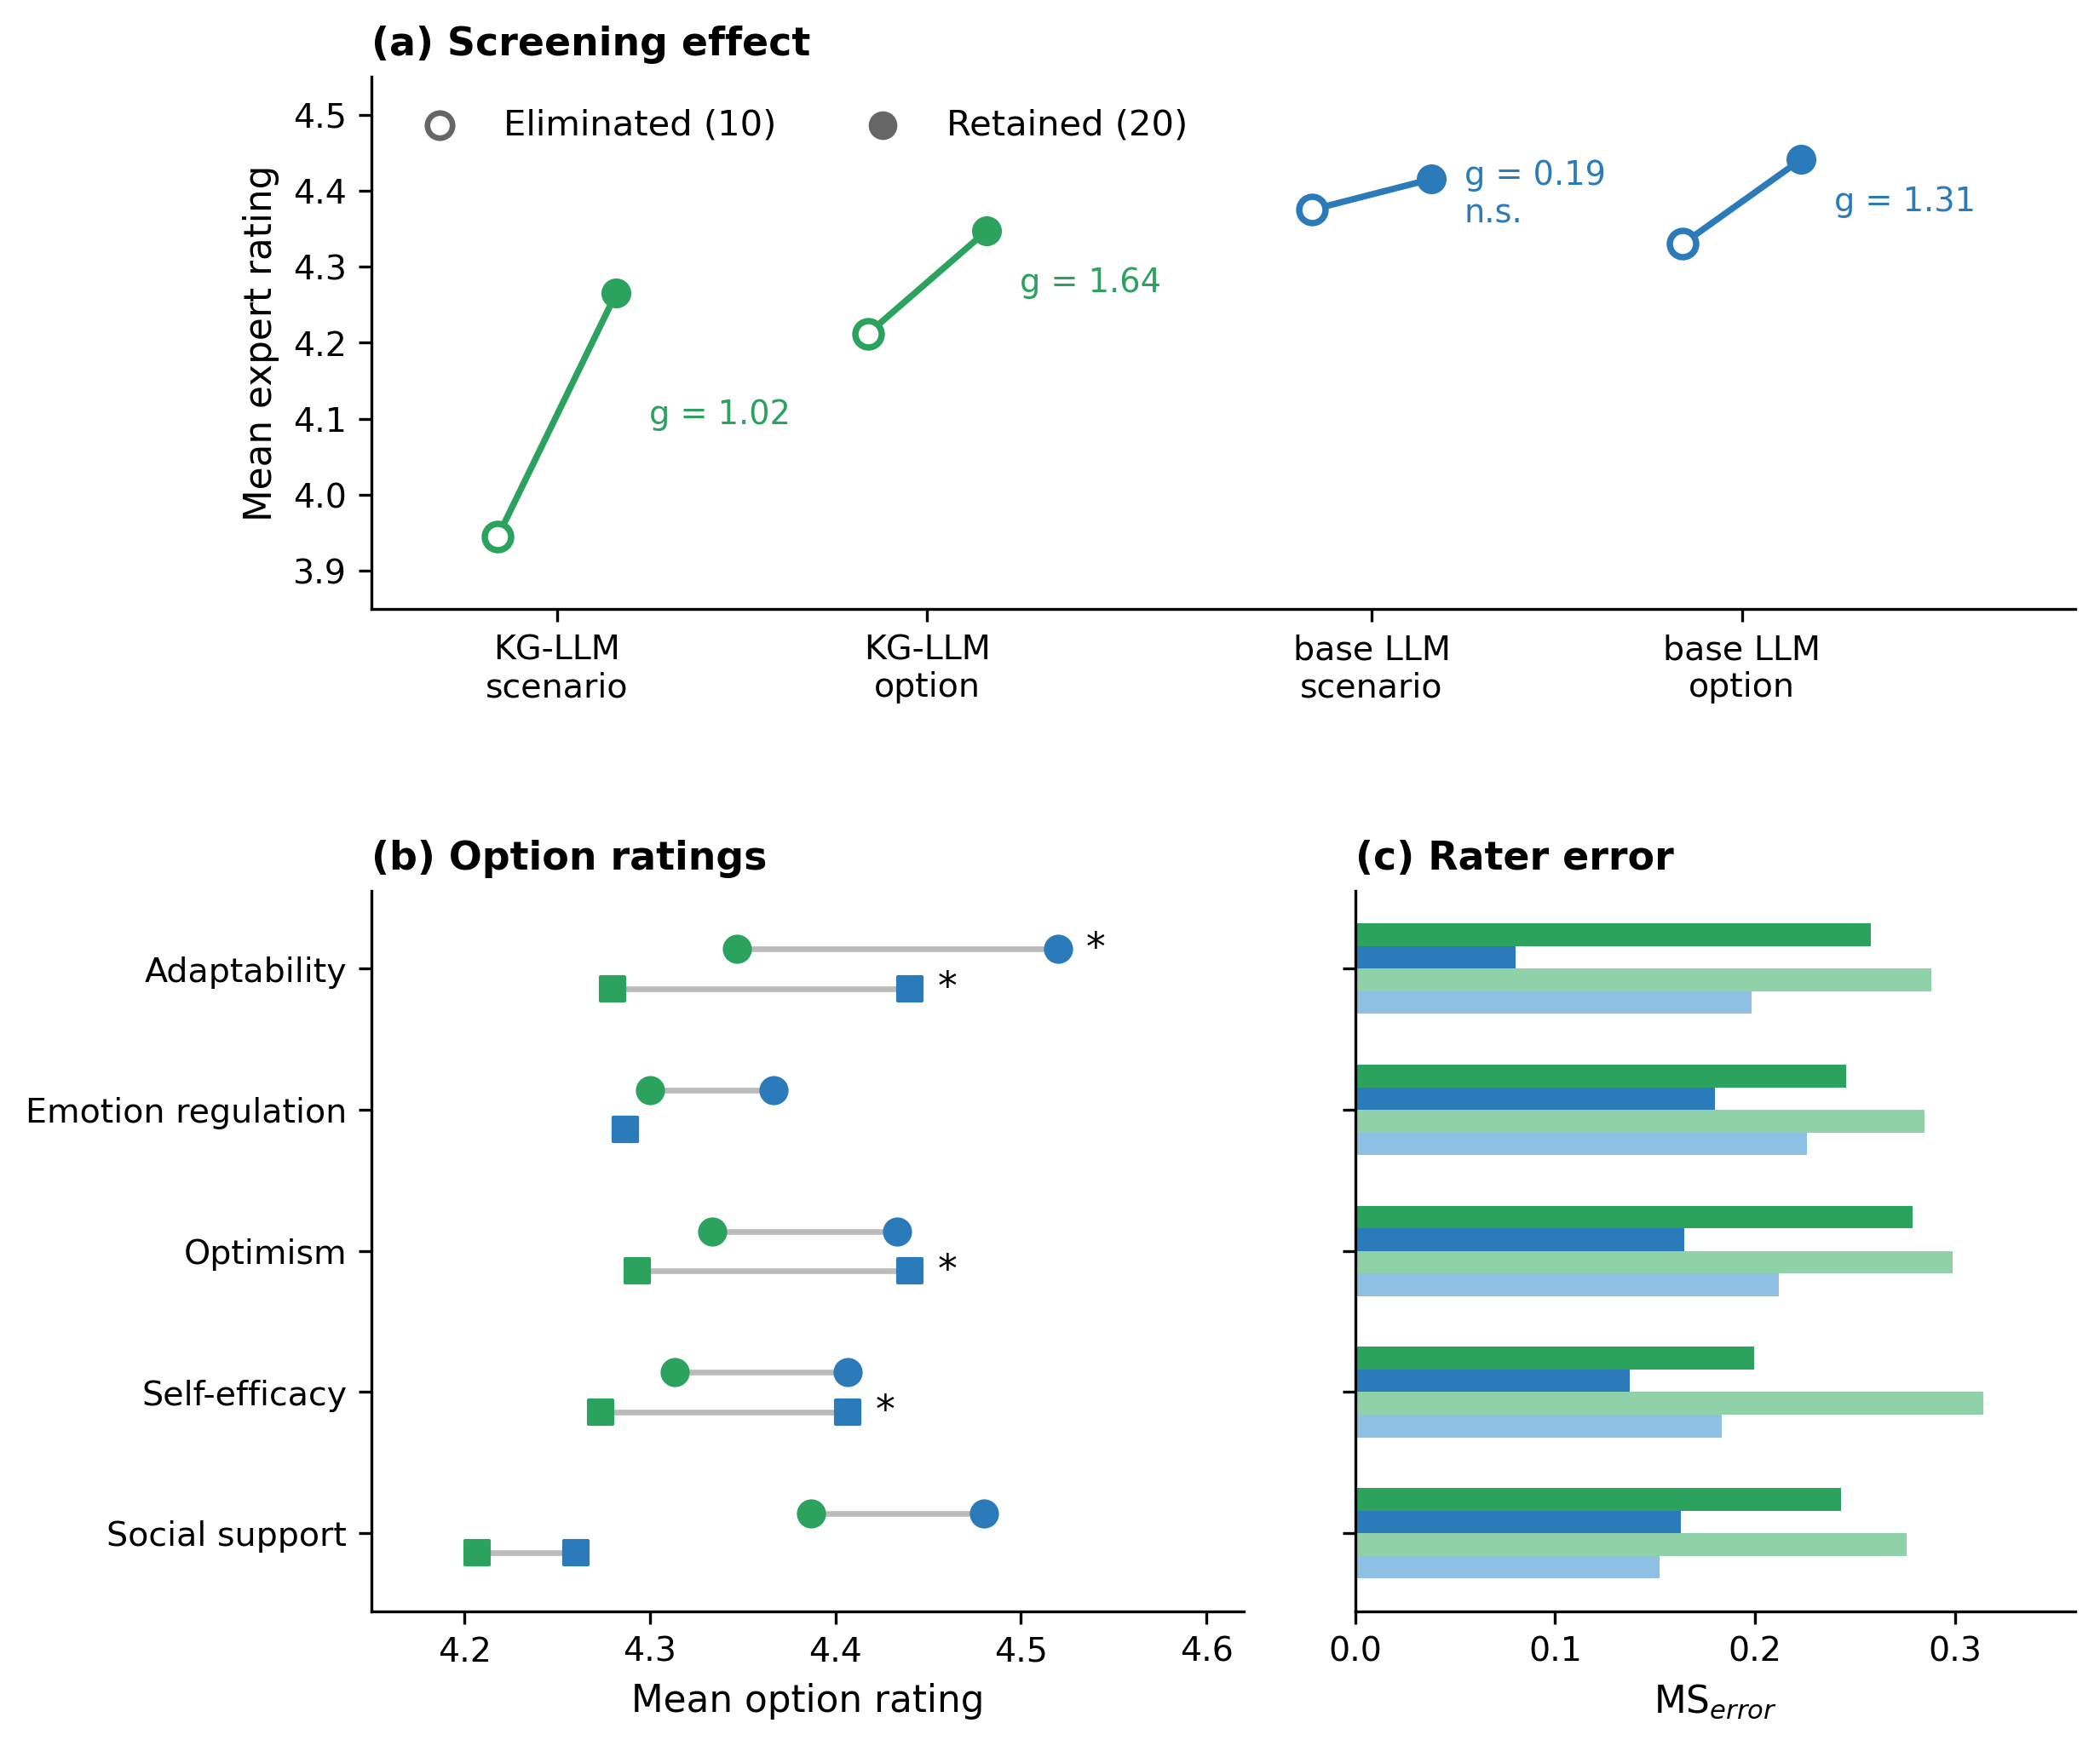

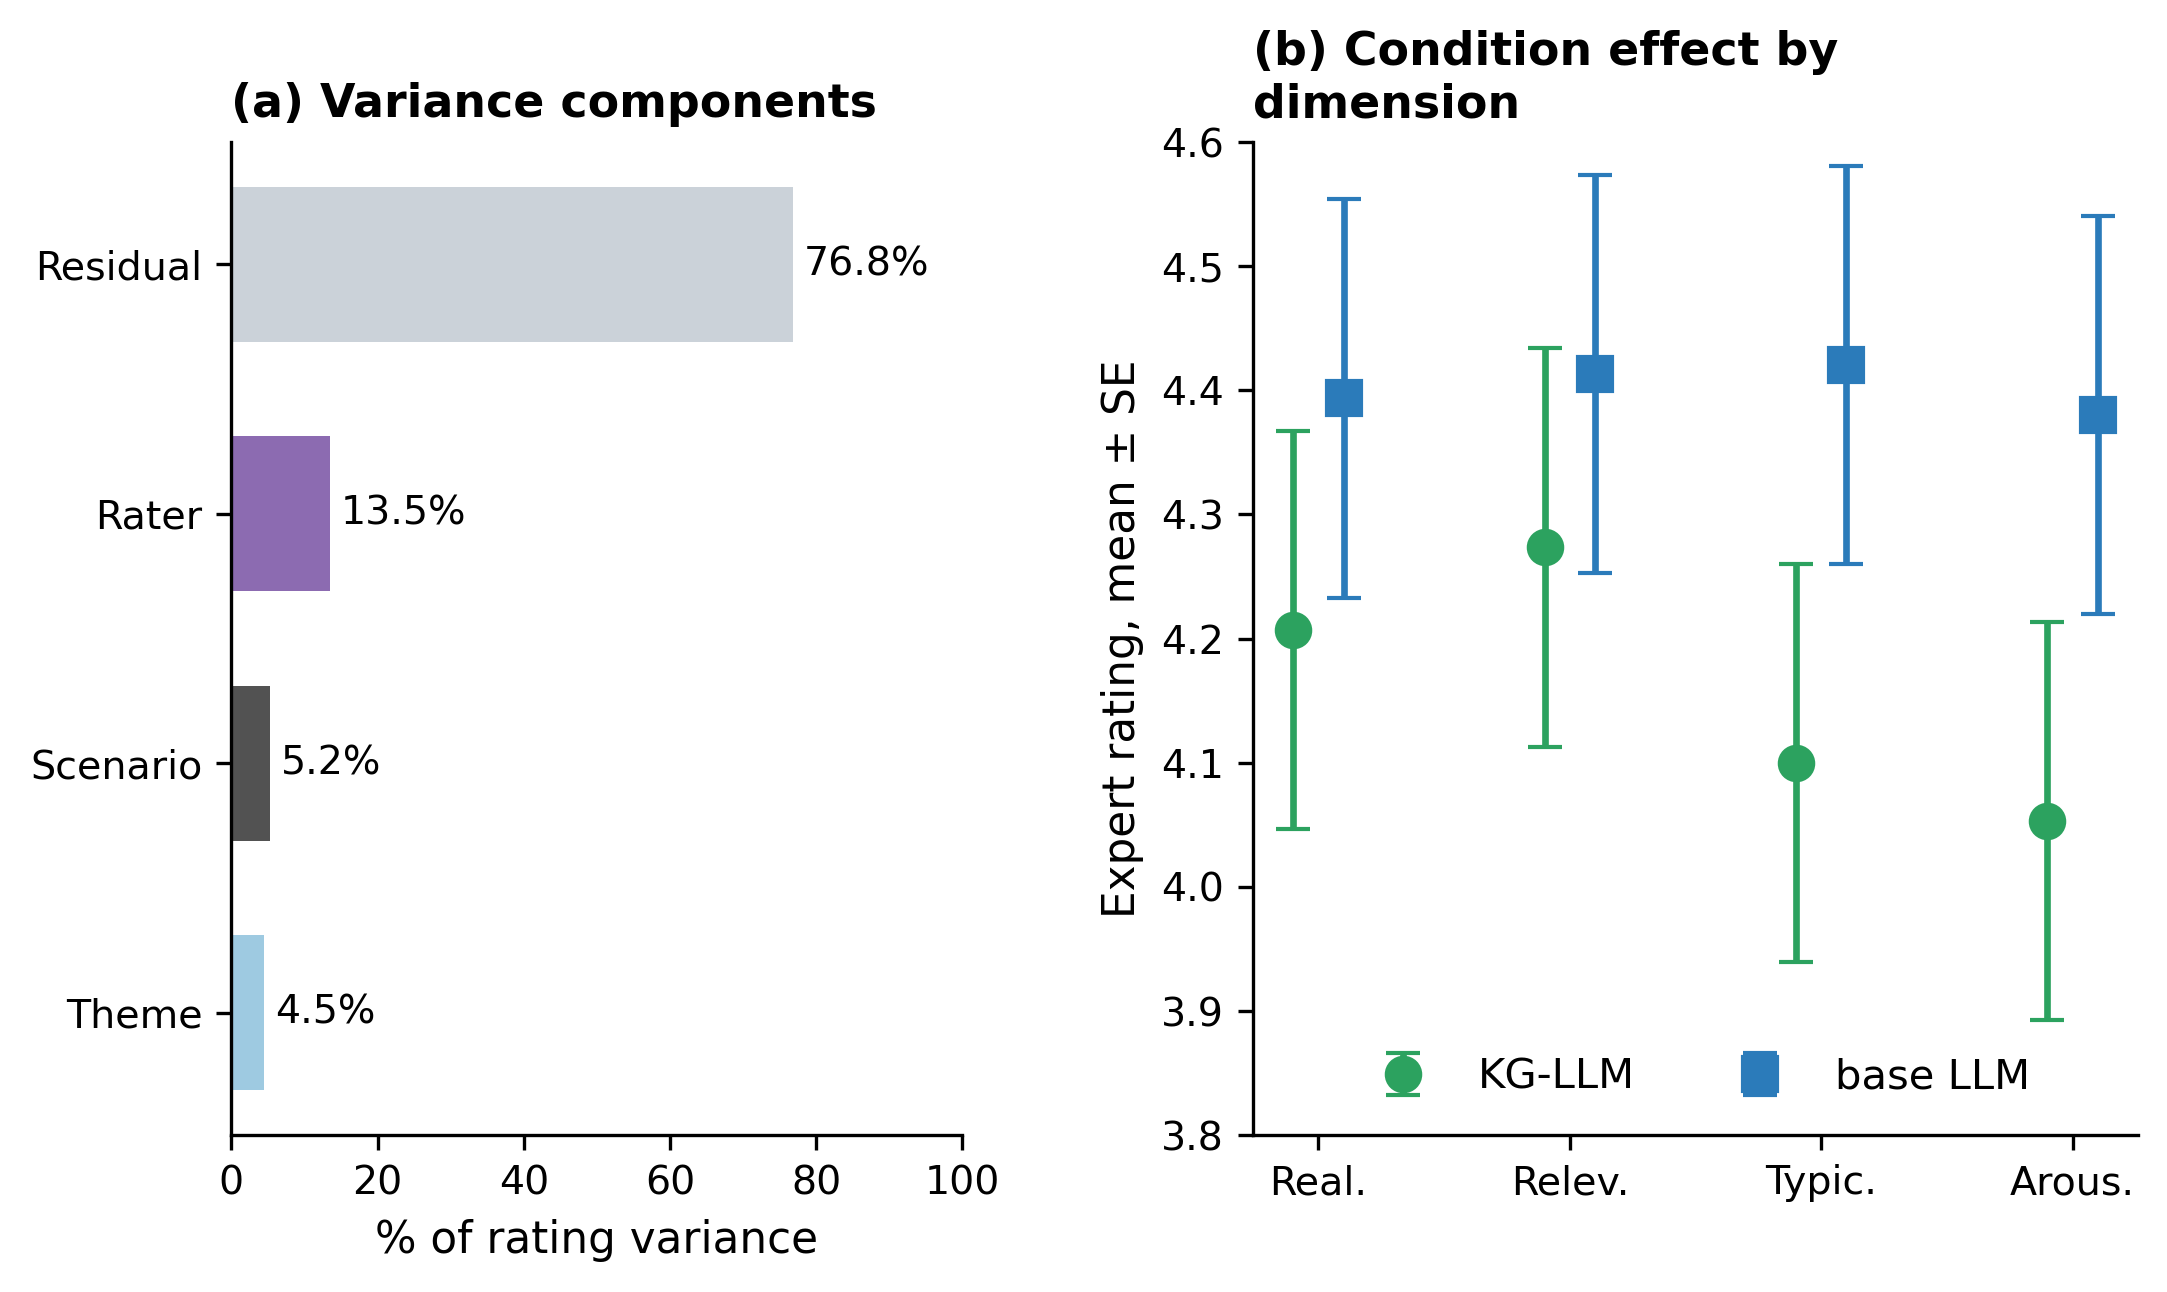

In [5]:
results["s06"] = s06_mixed_model.run()
results["s08"] = s08_validity.run()
r4, r5, r6, r8 = results["s04"], results["s05"], results["s06"], results["s08"]

print("=== Scenario Content Validity Index (S-CVI/Ave) & Item-Level Mann-Whitney U ===")
print(r4["scvi_table"].round(3).to_string(index=False))
print(f"  Item-level I-CVI Mann-Whitney U = {r4['icvi_mannwhitney_u']:.1f}, p = {r4['icvi_mannwhitney_p']:.4g}")
print(f"  Leave-one-rater-out jackknife screening overlap = {r4['jackknife_overlap_overall_pct']:.1f}% (KG: {r4['jackknife_overlap_kg_pct']:.1f}%, base: {r4['jackknife_overlap_base_pct']:.1f}%)")

print("\n=== Table D2b: Per-Rater Option Quality Across 5 Coping Strategies (3,000 Ratings) ===")
cols_d2b = ["strategy", "dimension", "ms_error_kg", "ms_error_base", "mse_ratio", "kg_mean", "base_mean", "welch_t", "welch_p", "hedges_g", "scvi_kg", "scvi_base"]
print(r4["option_table_d2b"][cols_d2b].round(3).to_string(index=False))
print("  Rationale clause citation rates (%):", {k: round(v, 1) for k, v in r4["rationale_citation_pct"].items()})

print("\n=== Cross-Classified Mixed-Effects Model & Generalizability D-Study (§3.2.3, App. D.8.1) ===")
print(f"  Condition LRT chi2(1) = {r6['lrt_chi2_cond']:.2f} (p = {r6['lrt_p_cond']:.4g}) | Interaction LRT chi2(3) = {r6['lrt_chi2_interaction']:.2f} (p = {r6['lrt_p_interaction']:.3f})")
print(f"  REML variance shares  : { {k: round(v, 1) for k, v in r6['variance_shares'].items()} }")
print(f"  G-study dependability : G(5) = {r6['g_5']:.2f}, G(10) = {r6['g_10']:.2f}, G(20) = {r6['g_20']:.2f} | Raters for .70/.80 = {r6['raters_for_g70']} / {r6['raters_for_g80']}")

fig6_path = FIG_DIR / "fig06_cvi_error_and_screening.png"
fig7_path = FIG_DIR / "fig07_screening_and_options.png"
fig8_path = FIG_DIR / "fig08_mixed_effects_model.png"
fig_part1.plot_fig06(r4, r5, r8, RAW_DIR, fig6_path)
fig_part1.plot_fig07(r4, fig7_path)
fig_part1.plot_fig08(r6, fig8_path)
for p in (fig6_path, fig7_path, fig8_path):
    display(Image(filename=str(p), width=680))

## 6. Pilot Calibration, Item Provenance, Choice Entropy, & Internal Consistency (`H1/H4`; `s07, s09`, `Figures 9, 10, D1, D2`)

=== Item Provenance Verification (Appendix F.9) ===
  Formal items match top-4-per-theme screened sets: False
  Retained KG-LLM scenarios  : [1, 4, 5, 6, 7, 8, 10, 11, 13, 14, 15, 18, 19, 20, 21, 23, 25, 27, 29, 30]
  Retained base LLM scenarios: [2, 3, 4, 6, 7, 8, 10, 12, 13, 14, 15, 17, 19, 20, 21, 23, 25, 26, 27, 30]

=== H1 & H4 Internal Consistency Summary (§3.3.3) ===
condition  alpha_40  alpha_ci_low  alpha_ci_high  omega_40  omega_ci_low  omega_ci_high  alpha_ml20  alpha_ll20  sb_proj_20  alpha_scen_comp20  within_scen_ml_ll_r  rbar_implied  rbar_raw  median_citc  n_citc_lt_30
   KG-LLM     0.817         0.773          0.849     0.787         0.688          0.836       0.835       0.676       0.691              0.824                0.106         0.101     0.094        0.311            19
 base_LLM     0.799         0.744          0.836     0.724         0.445          0.808       0.838       0.743       0.666              0.804                0.092         0.091     0.082      

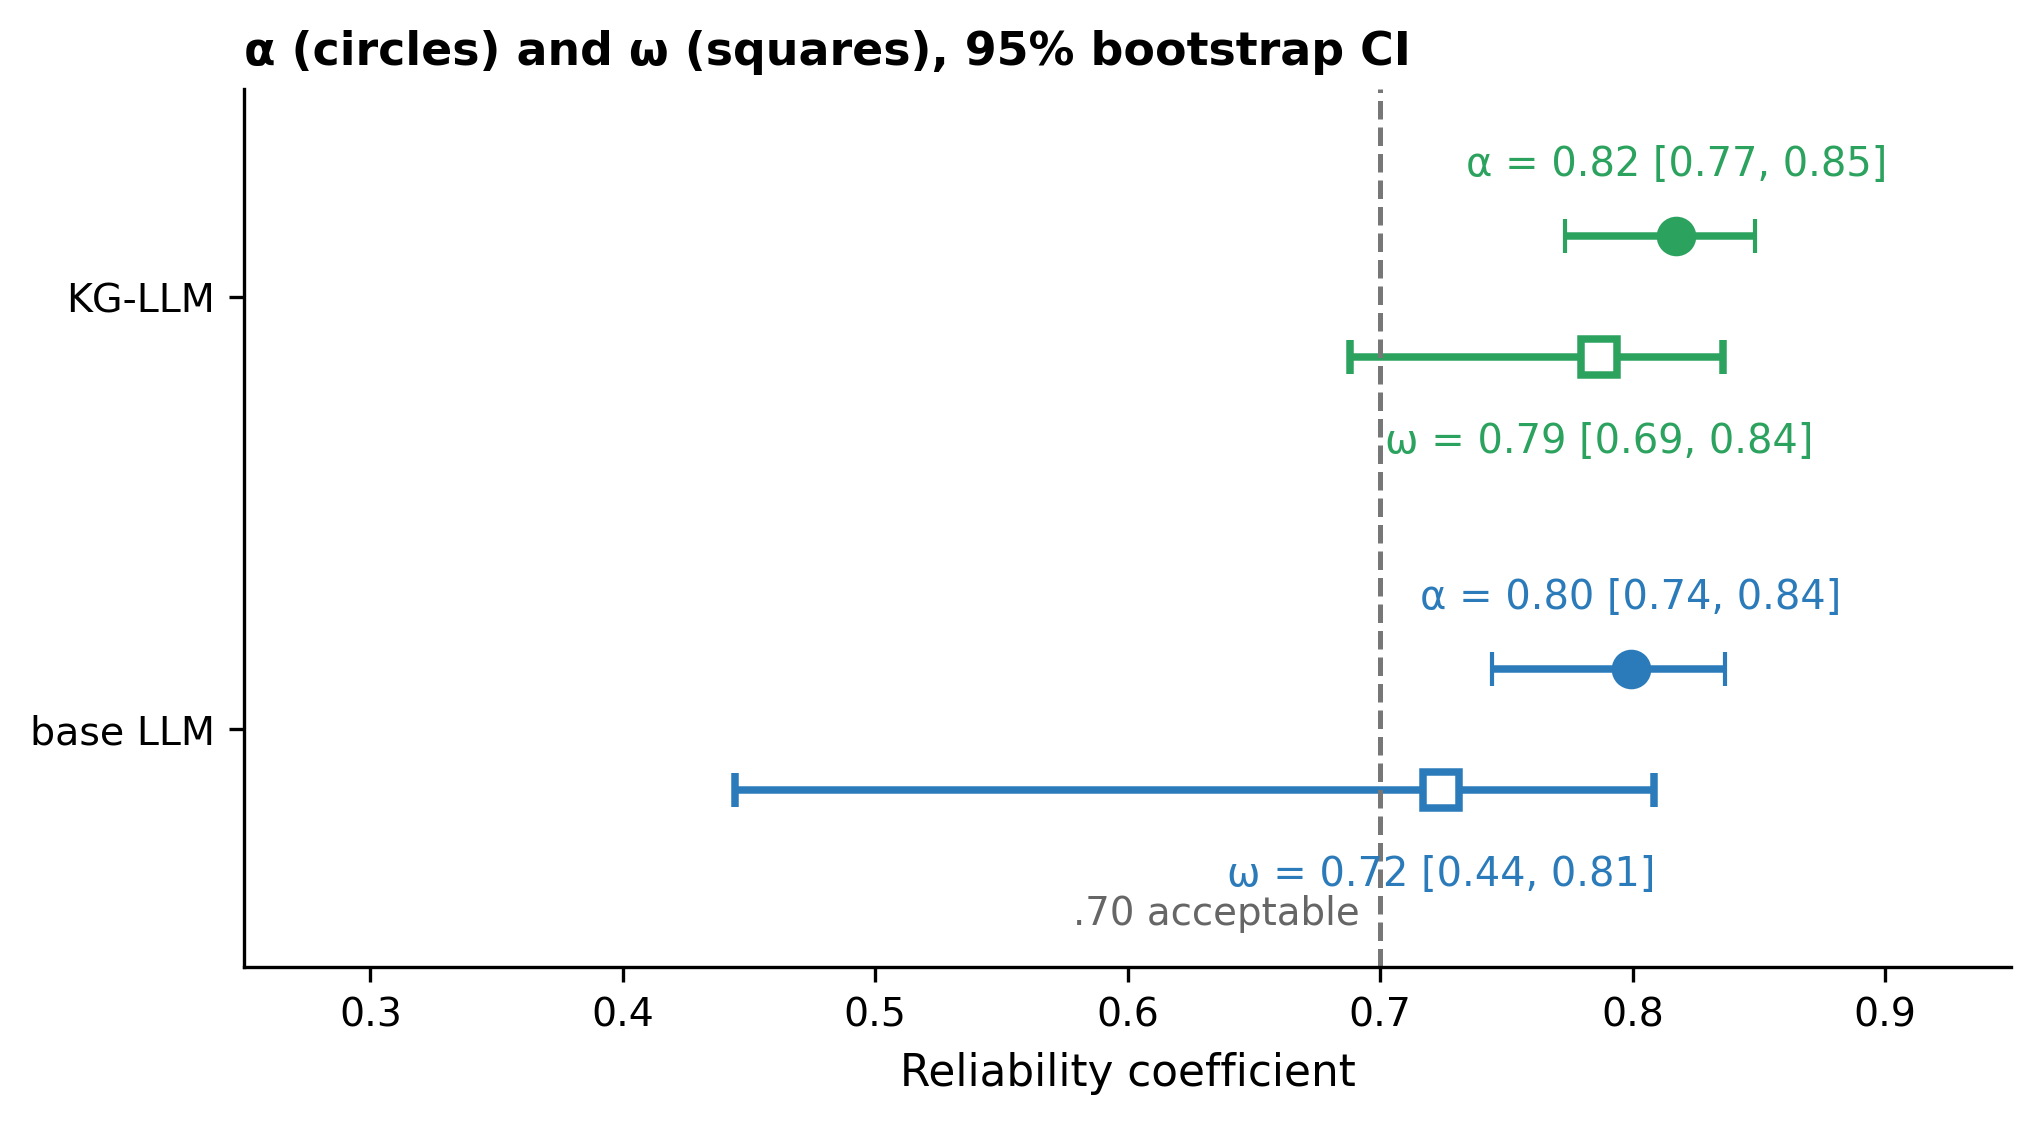

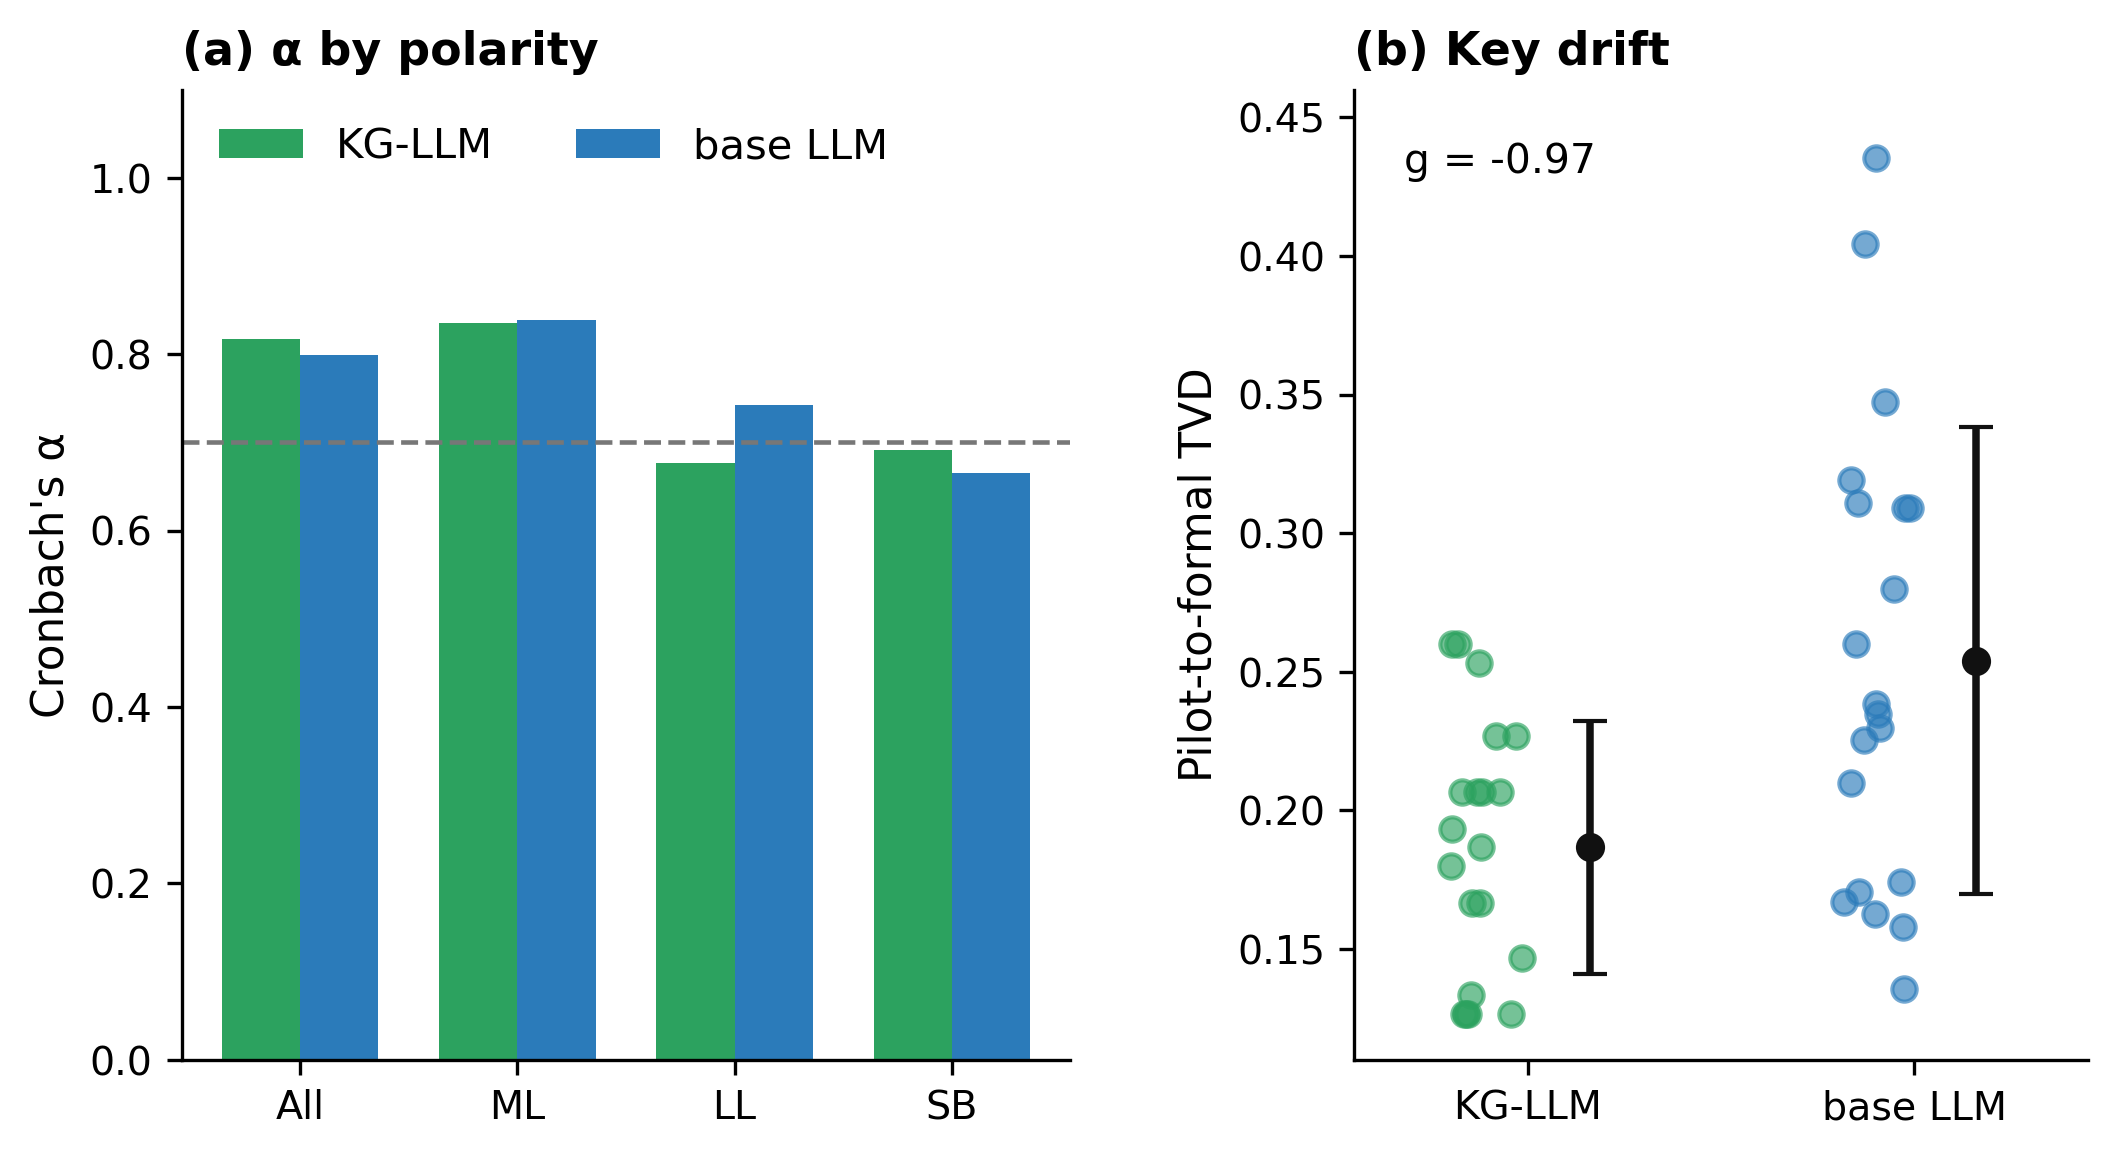

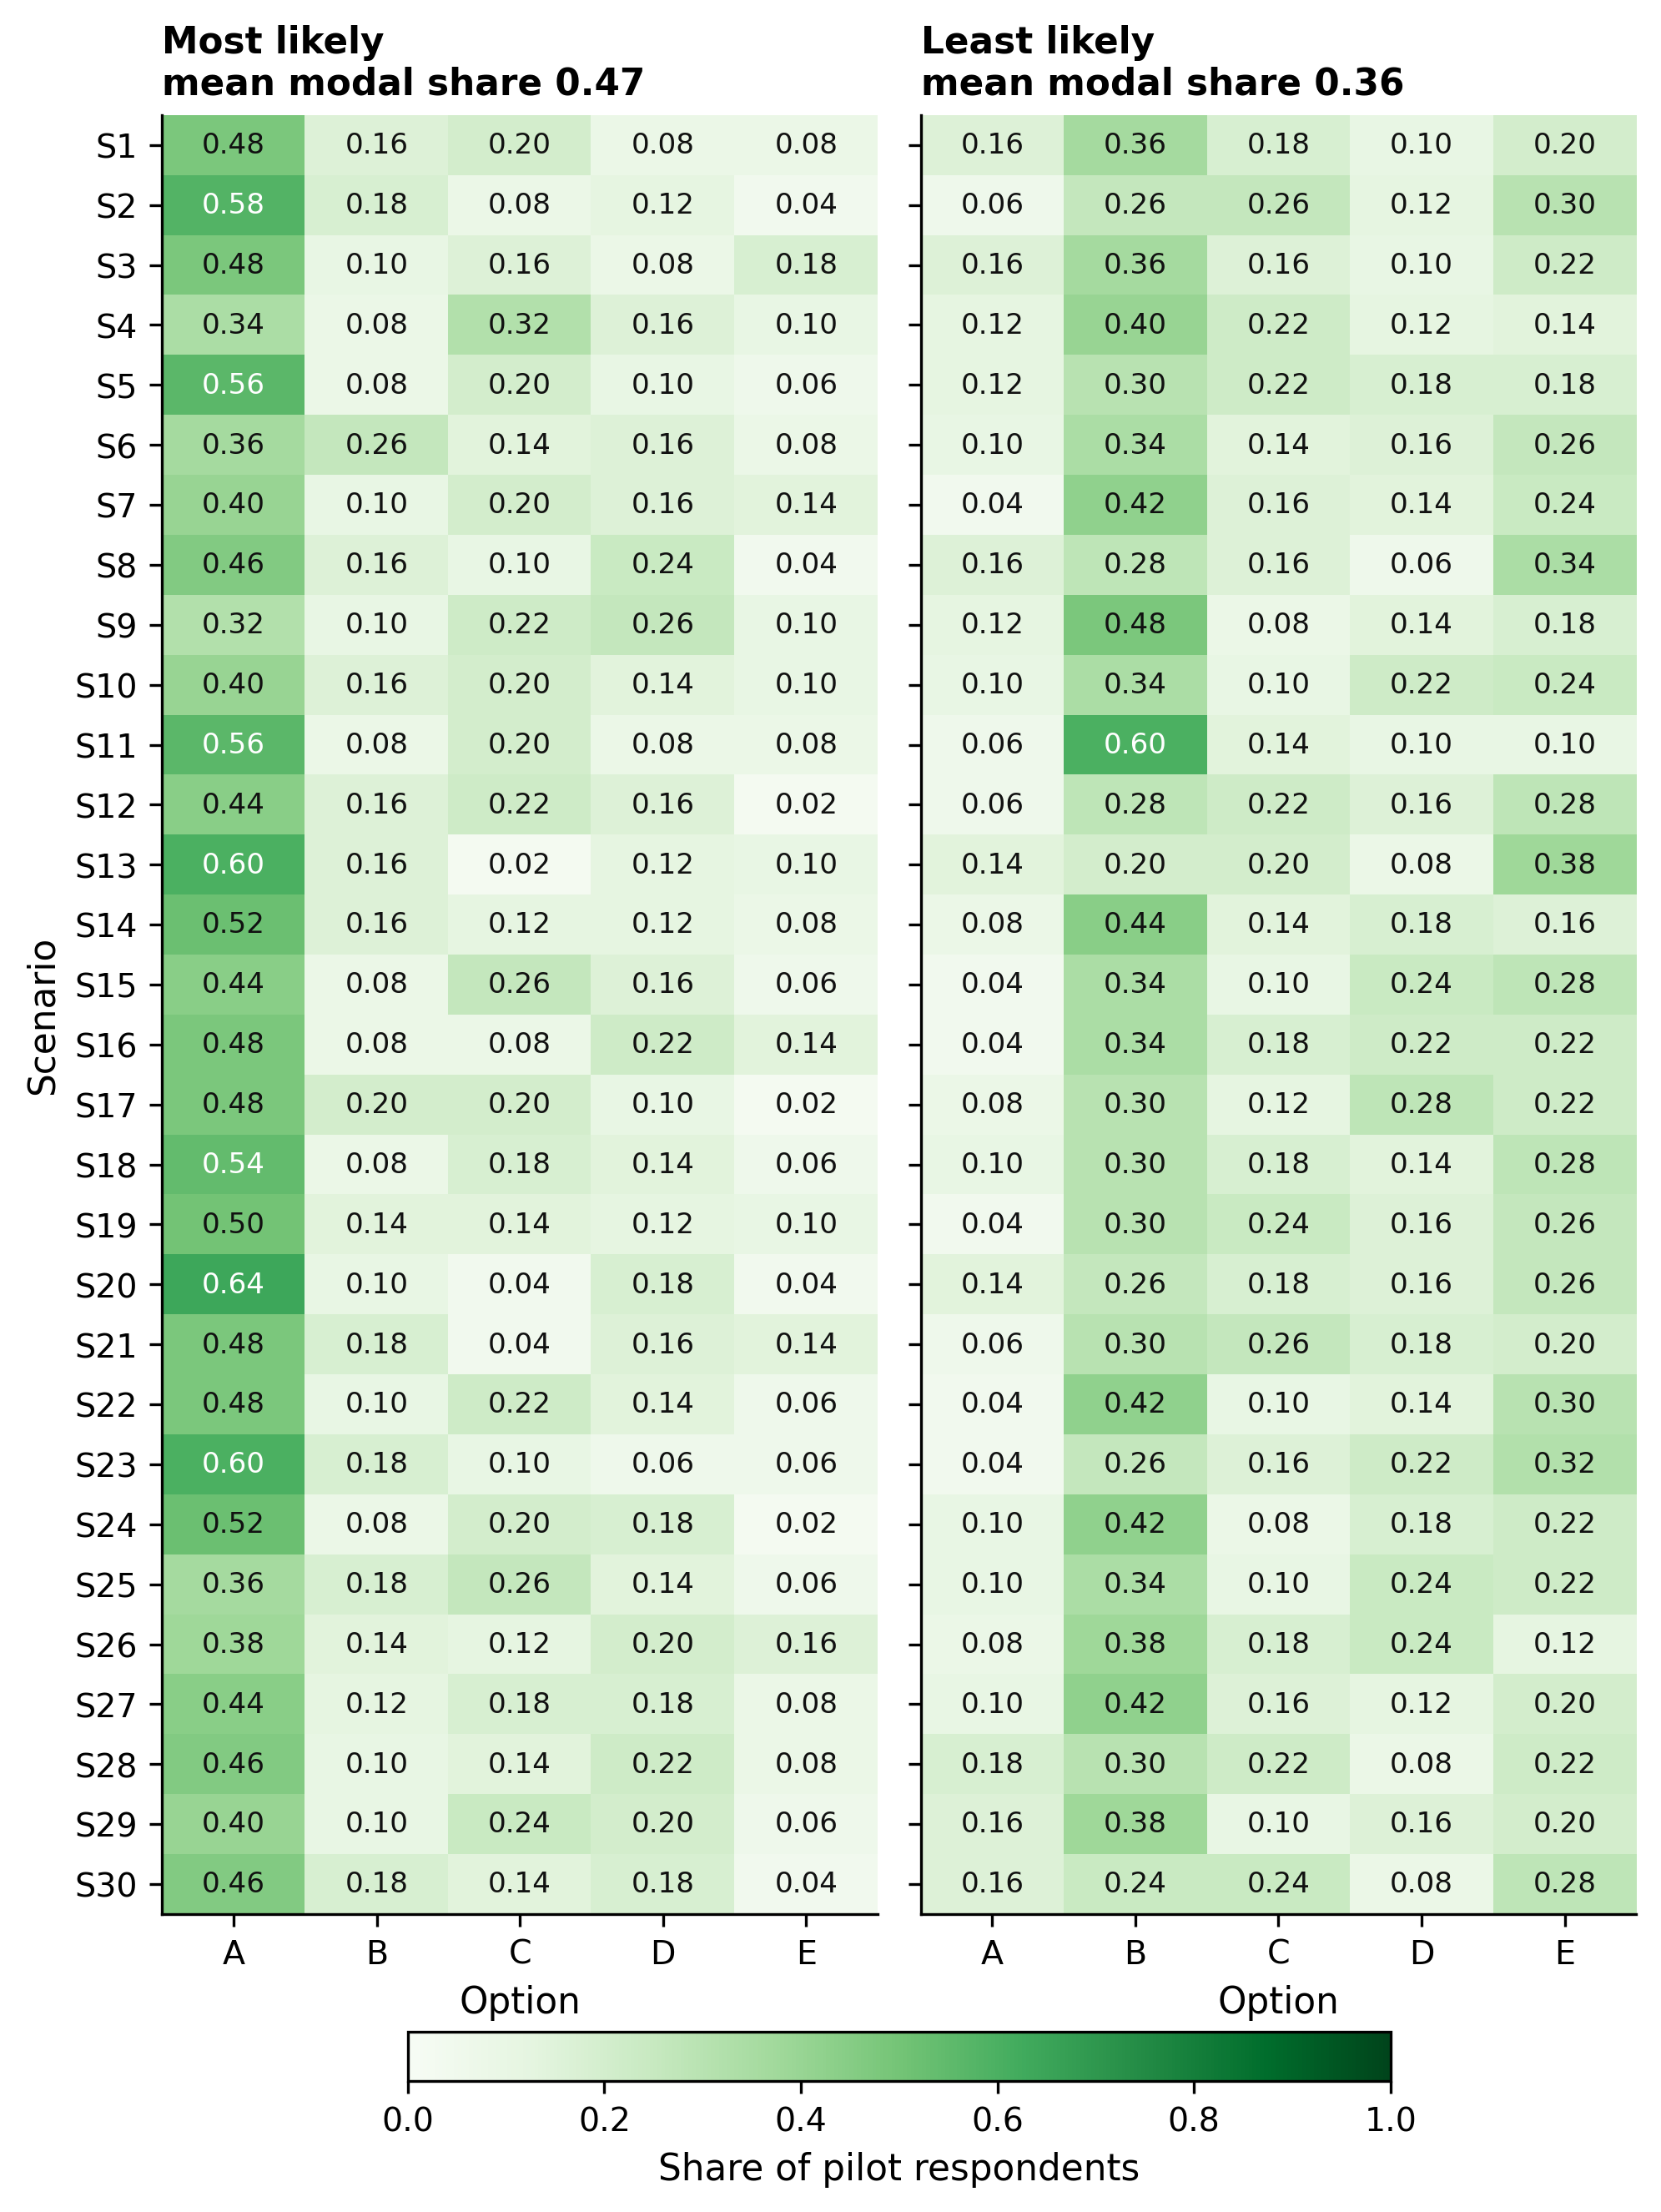

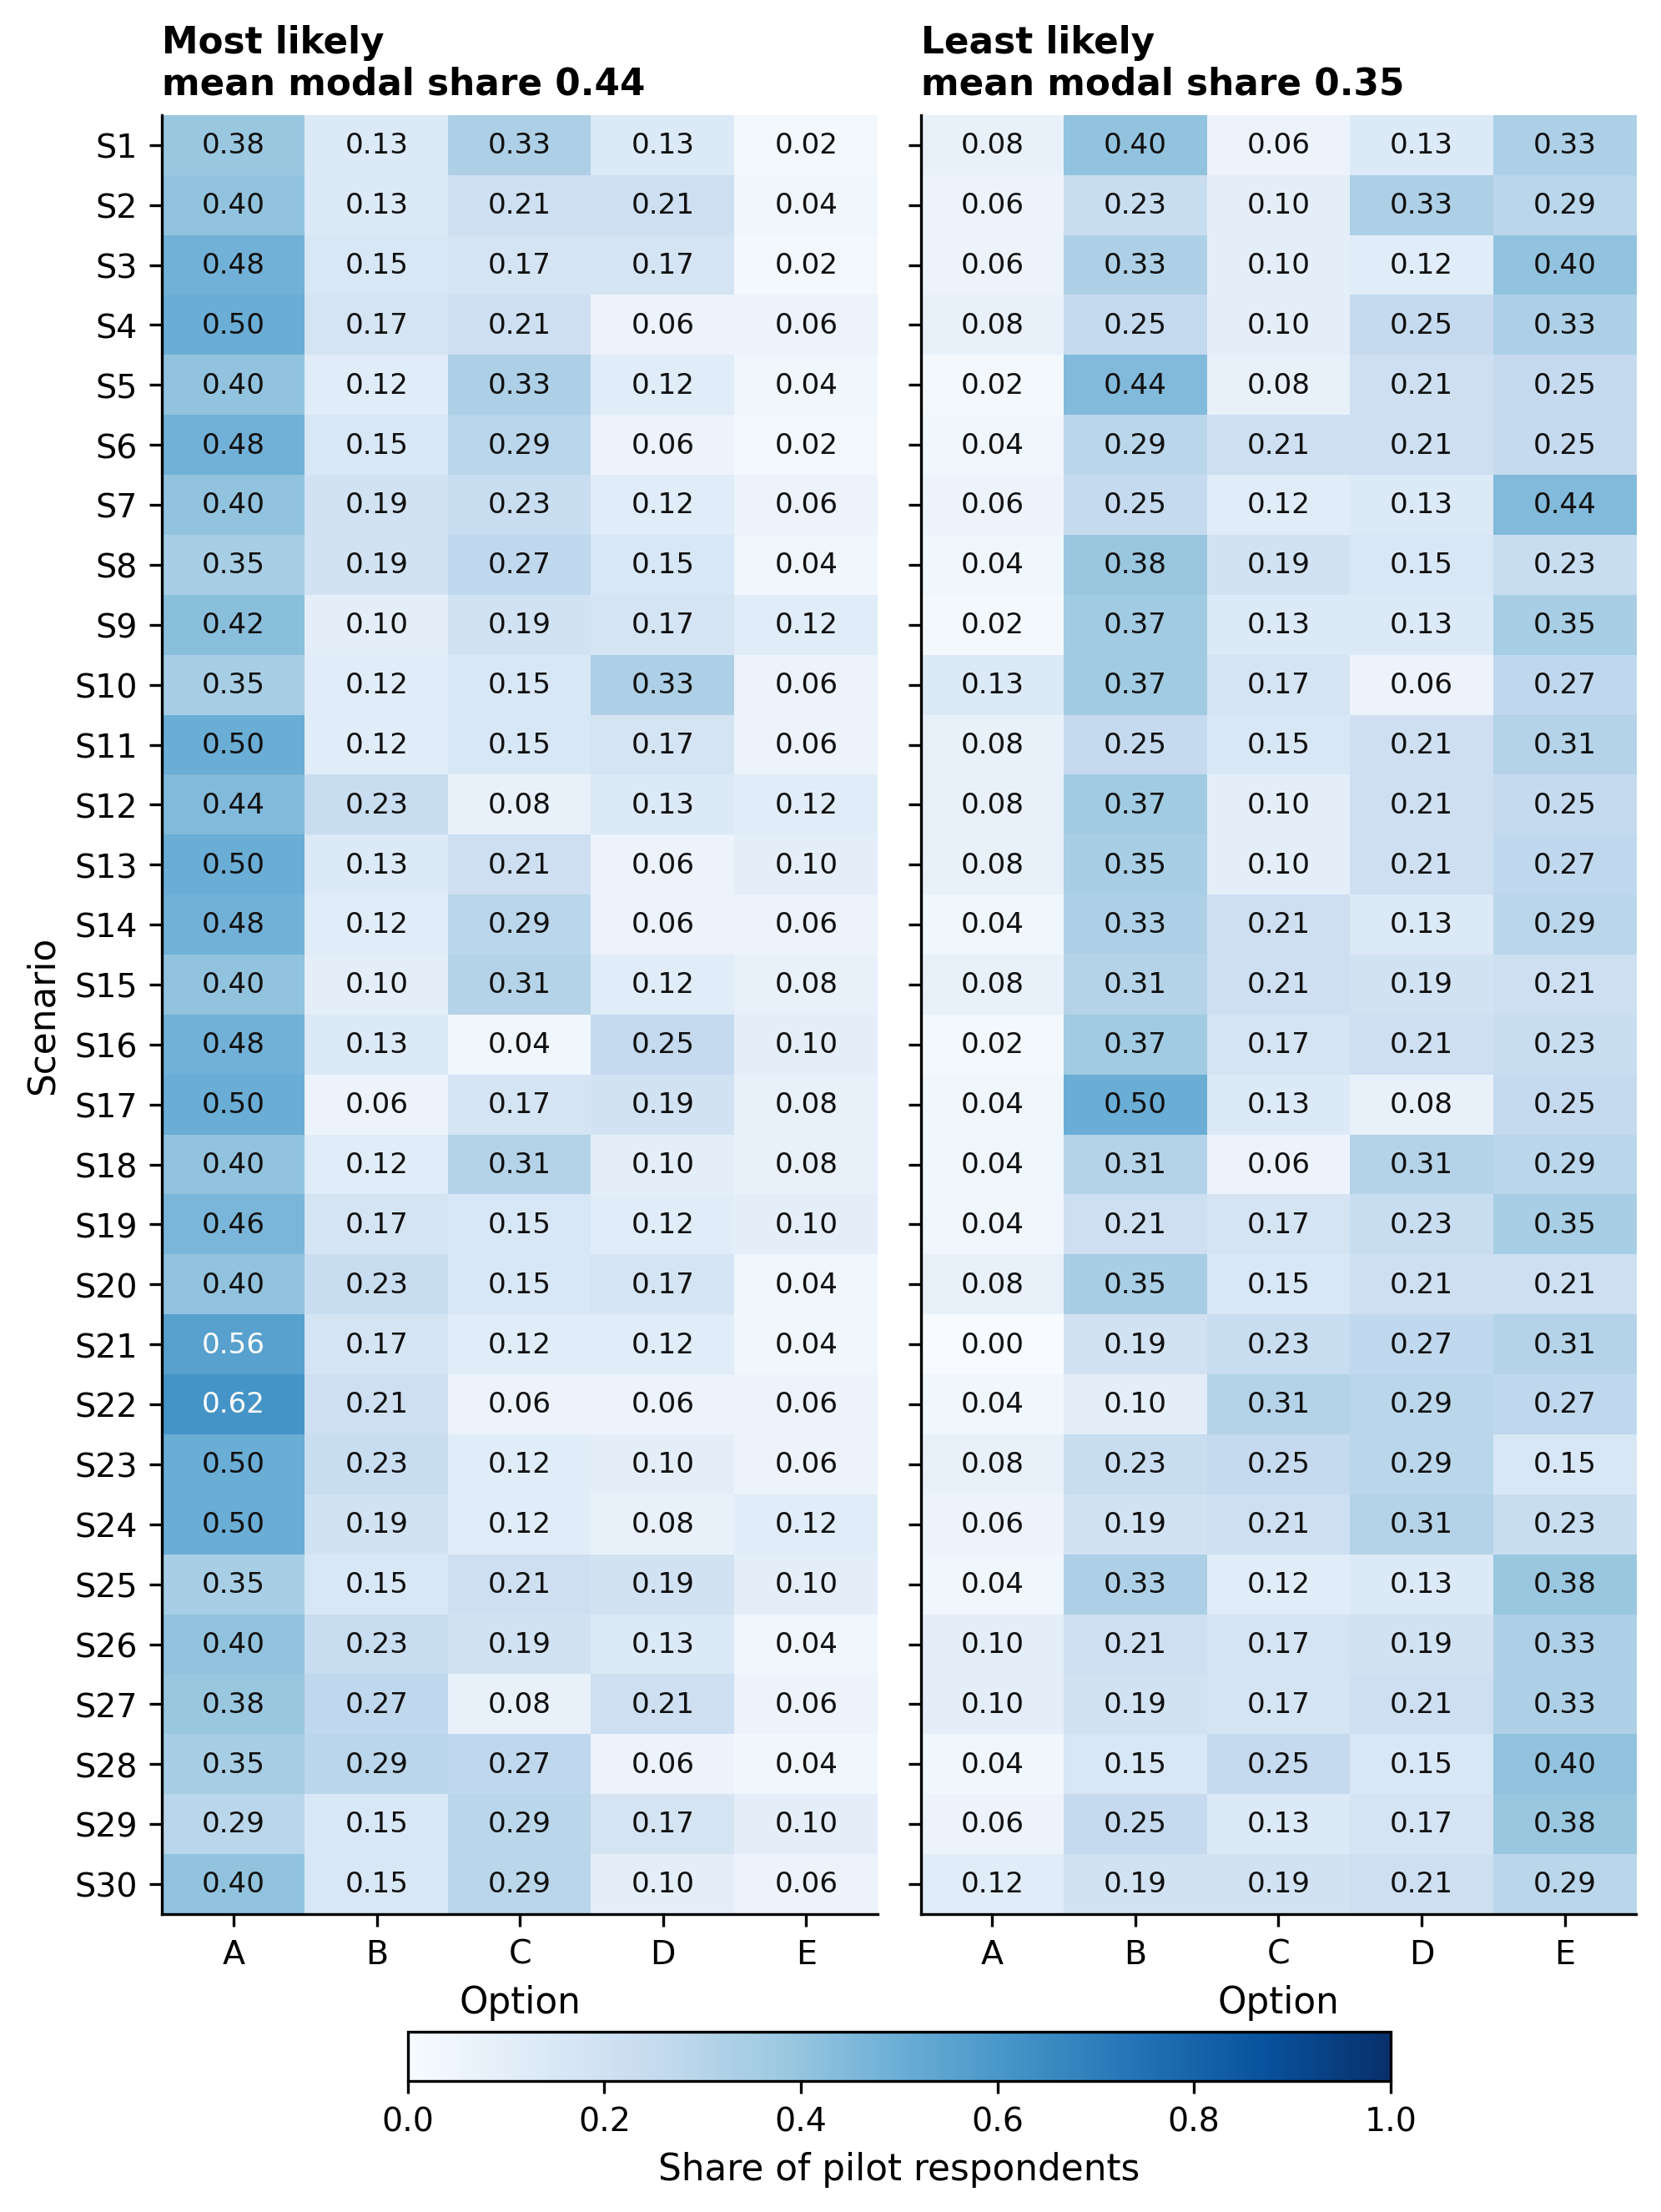

In [6]:
results["s07"] = s07_reliability.run()
results["s09"] = s09_pilot_and_entropy.run()
r7, r9 = results["s07"], results["s09"]

print("=== Item Provenance Verification (Appendix F.9) ===")
print(f"  Formal items match top-4-per-theme screened sets: {r9['provenance_exact_match']}")
print(f"  Retained KG-LLM scenarios  : {r9['screened_kg_scenarios']}")
print(f"  Retained base LLM scenarios: {r9['screened_base_scenarios']}")

print("\n=== H1 & H4 Internal Consistency Summary (§3.3.3) ===")
print(r7["summary_table"].round(3).to_string(index=False))
print(f"  Paired bootstrap delta_alpha (Full 40) = {r7['delta_alpha_40']:+.3f} [{r7['delta_alpha_ci_low']:+.3f}, {r7['delta_alpha_ci_high']:+.3f}], p = {r7['p_delta_alpha_40']:.3f}")

print("\n=== Pilot-to-Formal TVD & Within-Person Strategy Entropy (Tables D6e-D6f) ===")
print(f"  ML TVD (20 items): KG M = {r9['wt_tvd_ml']['m1']:.3f} vs. base M = {r9['wt_tvd_ml']['m2']:.3f} (t = {r9['wt_tvd_ml']['t']:.2f}, p = {r9['wt_tvd_ml']['p']:.3f}, g = {r9['wt_tvd_ml']['hedges_g']:.2f})")
print(f"  LL TVD (20 items): KG M = {r9['wt_tvd_ll']['m1']:.3f} vs. base M = {r9['wt_tvd_ll']['m2']:.3f} (t = {r9['wt_tvd_ll']['t']:.2f}, p = {r9['wt_tvd_ll']['p']:.3f}, g = {r9['wt_tvd_ll']['hedges_g']:+.2f})")
pe = r9["person_ml_entropy_paired"]
print(f"  Person ML strategy entropy: KG M = {pe['m1']:.3f} vs. base M = {pe['m2']:.3f} (paired t = {pe['t']:.2f}, p = {pe['p']:.4g}, d_z = {pe['dz']:.2f})")
print("\n=== Table D6f: Coping-Strategy Choice Frequencies & Criterion Correlates ===")
print(r9["choice_table"].round(3).to_string(index=False))

fig9_path = FIG_DIR / "fig09_internal_consistency.png"
fig10_path = FIG_DIR / "fig10_polarity_and_key_drift.png"
figD1_path = FIG_DIR / "figD1_pilot_key_kg_llm.png"
figD2_path = FIG_DIR / "figD2_pilot_key_base_llm.png"
fig_part2.plot_fig09(r7, fig9_path)
fig_part2.plot_fig10(r7, r9, fig10_path)
fig_part2.plot_figD1(r9, figD1_path)
fig_part2.plot_figD2(r9, figD2_path)
for p in (fig9_path, fig10_path, figD1_path, figD2_path):
    display(Image(filename=str(p), width=660))

## 7. Convergent, Criterion, & Incremental Validity (`H1/H4`; `s08, s12`, `Figures 11 & 12`)

=== Table D6c: Shapiro-Wilk Normality Tests ===
    variable     W     p
       5x5RS 0.880 0.000
          PA 0.916 0.000
          NA 0.831 0.000
      Stress 0.931 0.000
     Anxiety 0.860 0.000
  Depression 0.755 0.000
  SJT_KG_LLM 0.982 0.053
SJT_base_LLM 0.987 0.153

=== Table D1: Descriptive Statistics, Cronbach's Alpha, & Correlations (N = 150) ===
  variable   mean     sd  alpha  r_sjt_kg  r_sjt_llm  r_5x5rs
SJT-KG-LLM 11.492  2.022  0.817     1.000      0.783    0.427
   SJT-LLM 11.634  1.694  0.799     0.783      1.000    0.354
     5x5RS 96.307 17.137  0.955     0.427      0.354    1.000
        PA 38.407  6.395  0.883     0.407      0.305    0.858
        NA 18.773  6.400  0.882    -0.367     -0.331   -0.774
Depression  7.333  8.026  0.903    -0.399     -0.420   -0.713
   Anxiety 10.680  8.063  0.822    -0.370     -0.345   -0.561
    Stress 12.533  8.125  0.856    -0.388     -0.352   -0.749
  Inter-SJT r = 0.783 (disattenuated: 0.97 via alpha, 1.04 via omega)
  Partial r(S

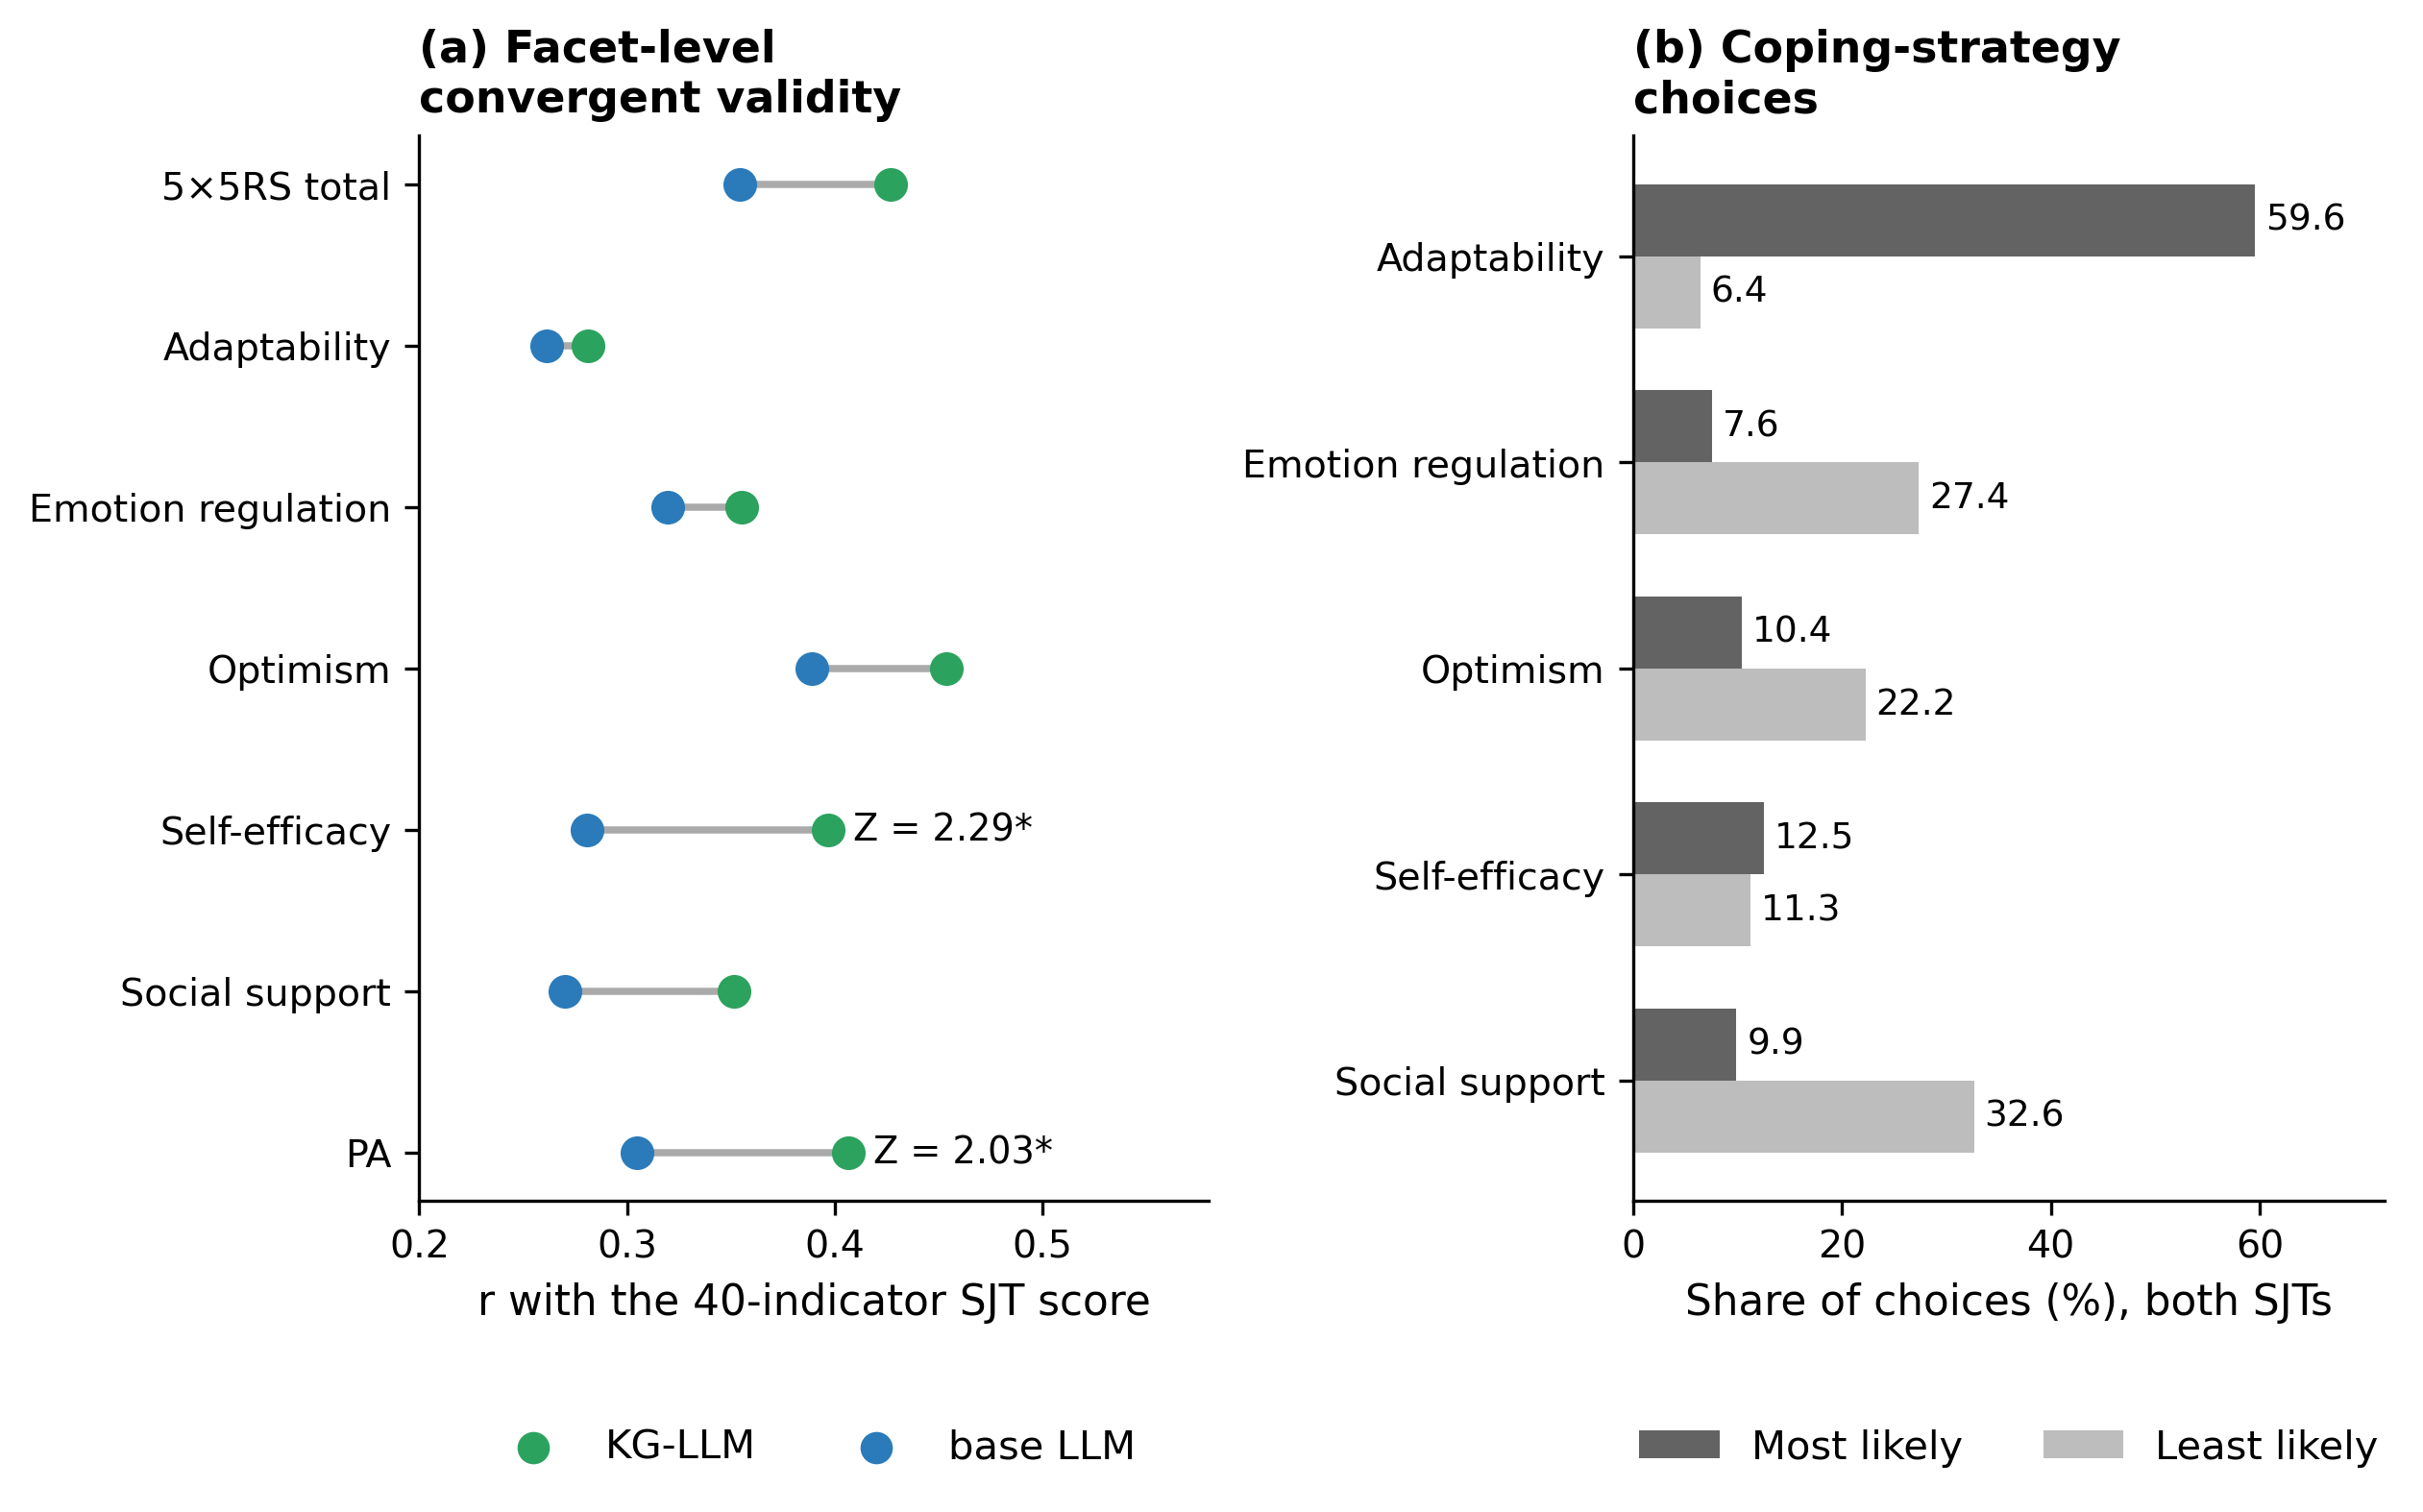

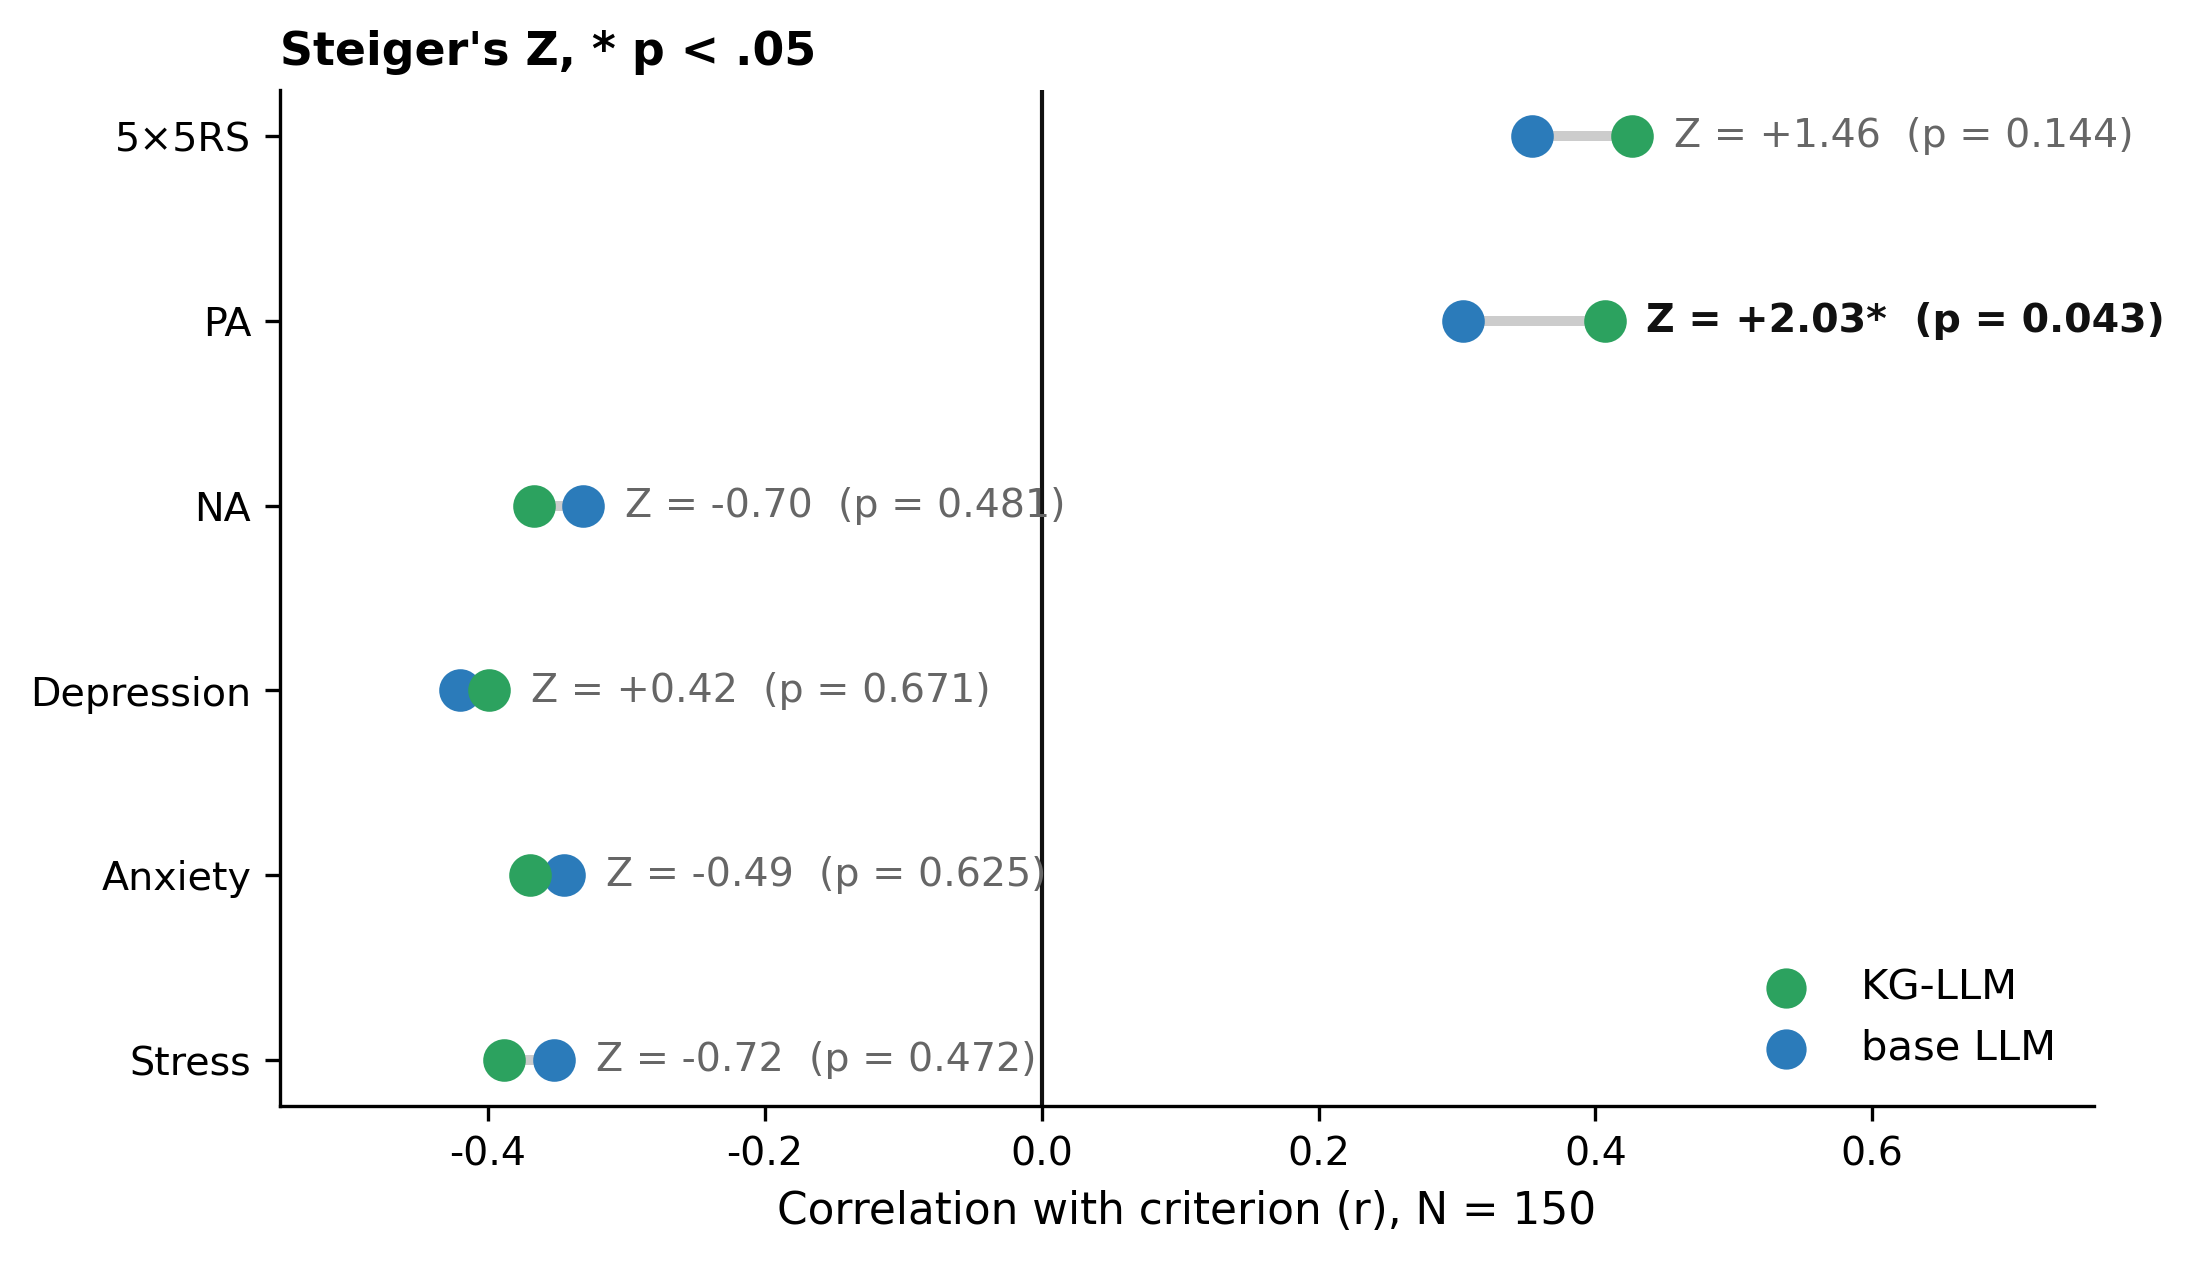

In [7]:
results["s12"] = s12_hierarchical_regressions.run()
r8, r12 = results["s08"], results["s12"]

print("=== Table D6c: Shapiro-Wilk Normality Tests ===")
print(r8["normality"].round(3).to_string(index=False))

print("\n=== Table D1: Descriptive Statistics, Cronbach's Alpha, & Correlations (N = 150) ===")
print(r8["table_d1"].round(3).to_string(index=False))
print(f"  Inter-SJT r = {r8['inter_sjt_r']:.3f} (disattenuated: {r8['disattenuated_r_alpha']:.2f} via alpha, {r8['disattenuated_r_omega']:.2f} via omega)")
print(f"  Partial r(SJT, 5x5RS | PA, NA): KG = {r8['partial_r_kg_5x5_given_pana']:.3f} (p = {r8['p_partial_r_kg']:.3f}), base = {r8['partial_r_llm_5x5_given_pana']:.3f} (p = {r8['p_partial_r_llm']:.3f})")

print("\n=== Table D4a: Steiger's Z Contrasts, Dependent-Correlation TOST, & Spearman Rho ===")
cols_d4a = ["criterion", "r_kg", "r_llm", "steiger_z", "p_diff", "tost_p_10", "tost_p_15", "tost_p_20", "spearman_kg", "spearman_llm"]
print(r8["table_d4a"][cols_d4a].round(3).to_string(index=False))

print("\n=== Table D2: Regressions onto PA + NA ===")
print(r12["table_d2"].round(3).to_string(index=False))

print("\n=== Table D3: Hierarchical Regressions Over 5x5RS ===")
print(r12["table_d3"][["criterion", "s1_r2", "s2_beta_llm", "s2_dr2", "s2_p_dr2", "s3_beta_kg", "s3_dr2", "s3_p_dr2"]].round(3).to_string(index=False))

print("\n=== Table D4: Incremental Validity Over PA + NA ===")
print(r12["table_d4"][["criterion", "measure", "beta_measure", "r2", "dr2", "p_dr2"]].round(3).to_string(index=False))

print("\n=== Table D5: Hierarchical Regressions Over PA + NA + 5x5RS ===")
print(r12["table_d5"][["criterion", "s1_r2", "s2_beta_llm", "s2_dr2", "s2_p_dr2", "s3_beta_kg", "s3_dr2", "s3_p_dr2"]].round(3).to_string(index=False))

fig11_path = FIG_DIR / "fig11_facets_and_coping_choices.png"
fig12_path = FIG_DIR / "fig12_criterion_correlations.png"
fig_part2.plot_fig11(r8, results["s09"], fig11_path)
fig_part2.plot_fig12(r8, fig12_path)
display(Image(filename=str(fig11_path), width=680))
display(Image(filename=str(fig12_path), width=680))

## 8. Tier 2 Calibration Robustness & Tier 3 Moderation, Cross-Validated Hybrids, `DualHit`, & Cross-Stage Diagnostics (`Figures 13, D3, D4`)

=== Appendix D.8.5: Alternative Scoring Keys ===
      key_method  alpha_kg  alpha_llm  r_5x5rs_kg  r_5x5rs_llm  z_5x5rs  p_5x5rs  r_pa_kg  r_pa_llm  z_pa  p_pa
Pilot_Proportion     0.817      0.799       0.427        0.354    1.459    0.144    0.407     0.305 2.025 0.043
      Formal_LOO     0.852      0.852       0.366        0.364    0.060    0.952    0.376     0.340 0.901 0.367
      Borda_Rank     0.792      0.781       0.357        0.298    1.104    0.269    0.362     0.262 1.879 0.060
    Modal_Binary     0.785      0.729       0.408        0.336    1.325    0.185    0.385     0.297 1.590 0.112

=== 2,000-Resample Pilot + Formal Double Bootstrap ===
  Full-40 delta_alpha     = +0.023 [-0.062, +0.106], p = 0.557
  Full-40 delta_r(5x5RS)  = +0.077 [-0.076, +0.257], p = 0.361
  APH-24  delta_r(5x5RS)  = +0.175 [+0.000, +0.375], p = 0.050

=== 1,000-Split Same-Sample 2-Fold Cross-Fitted Consensus Keys (75/75 inside N = 150) ===
  Full-40 alpha           = 0.847 (KG) vs. 0.847 (base)

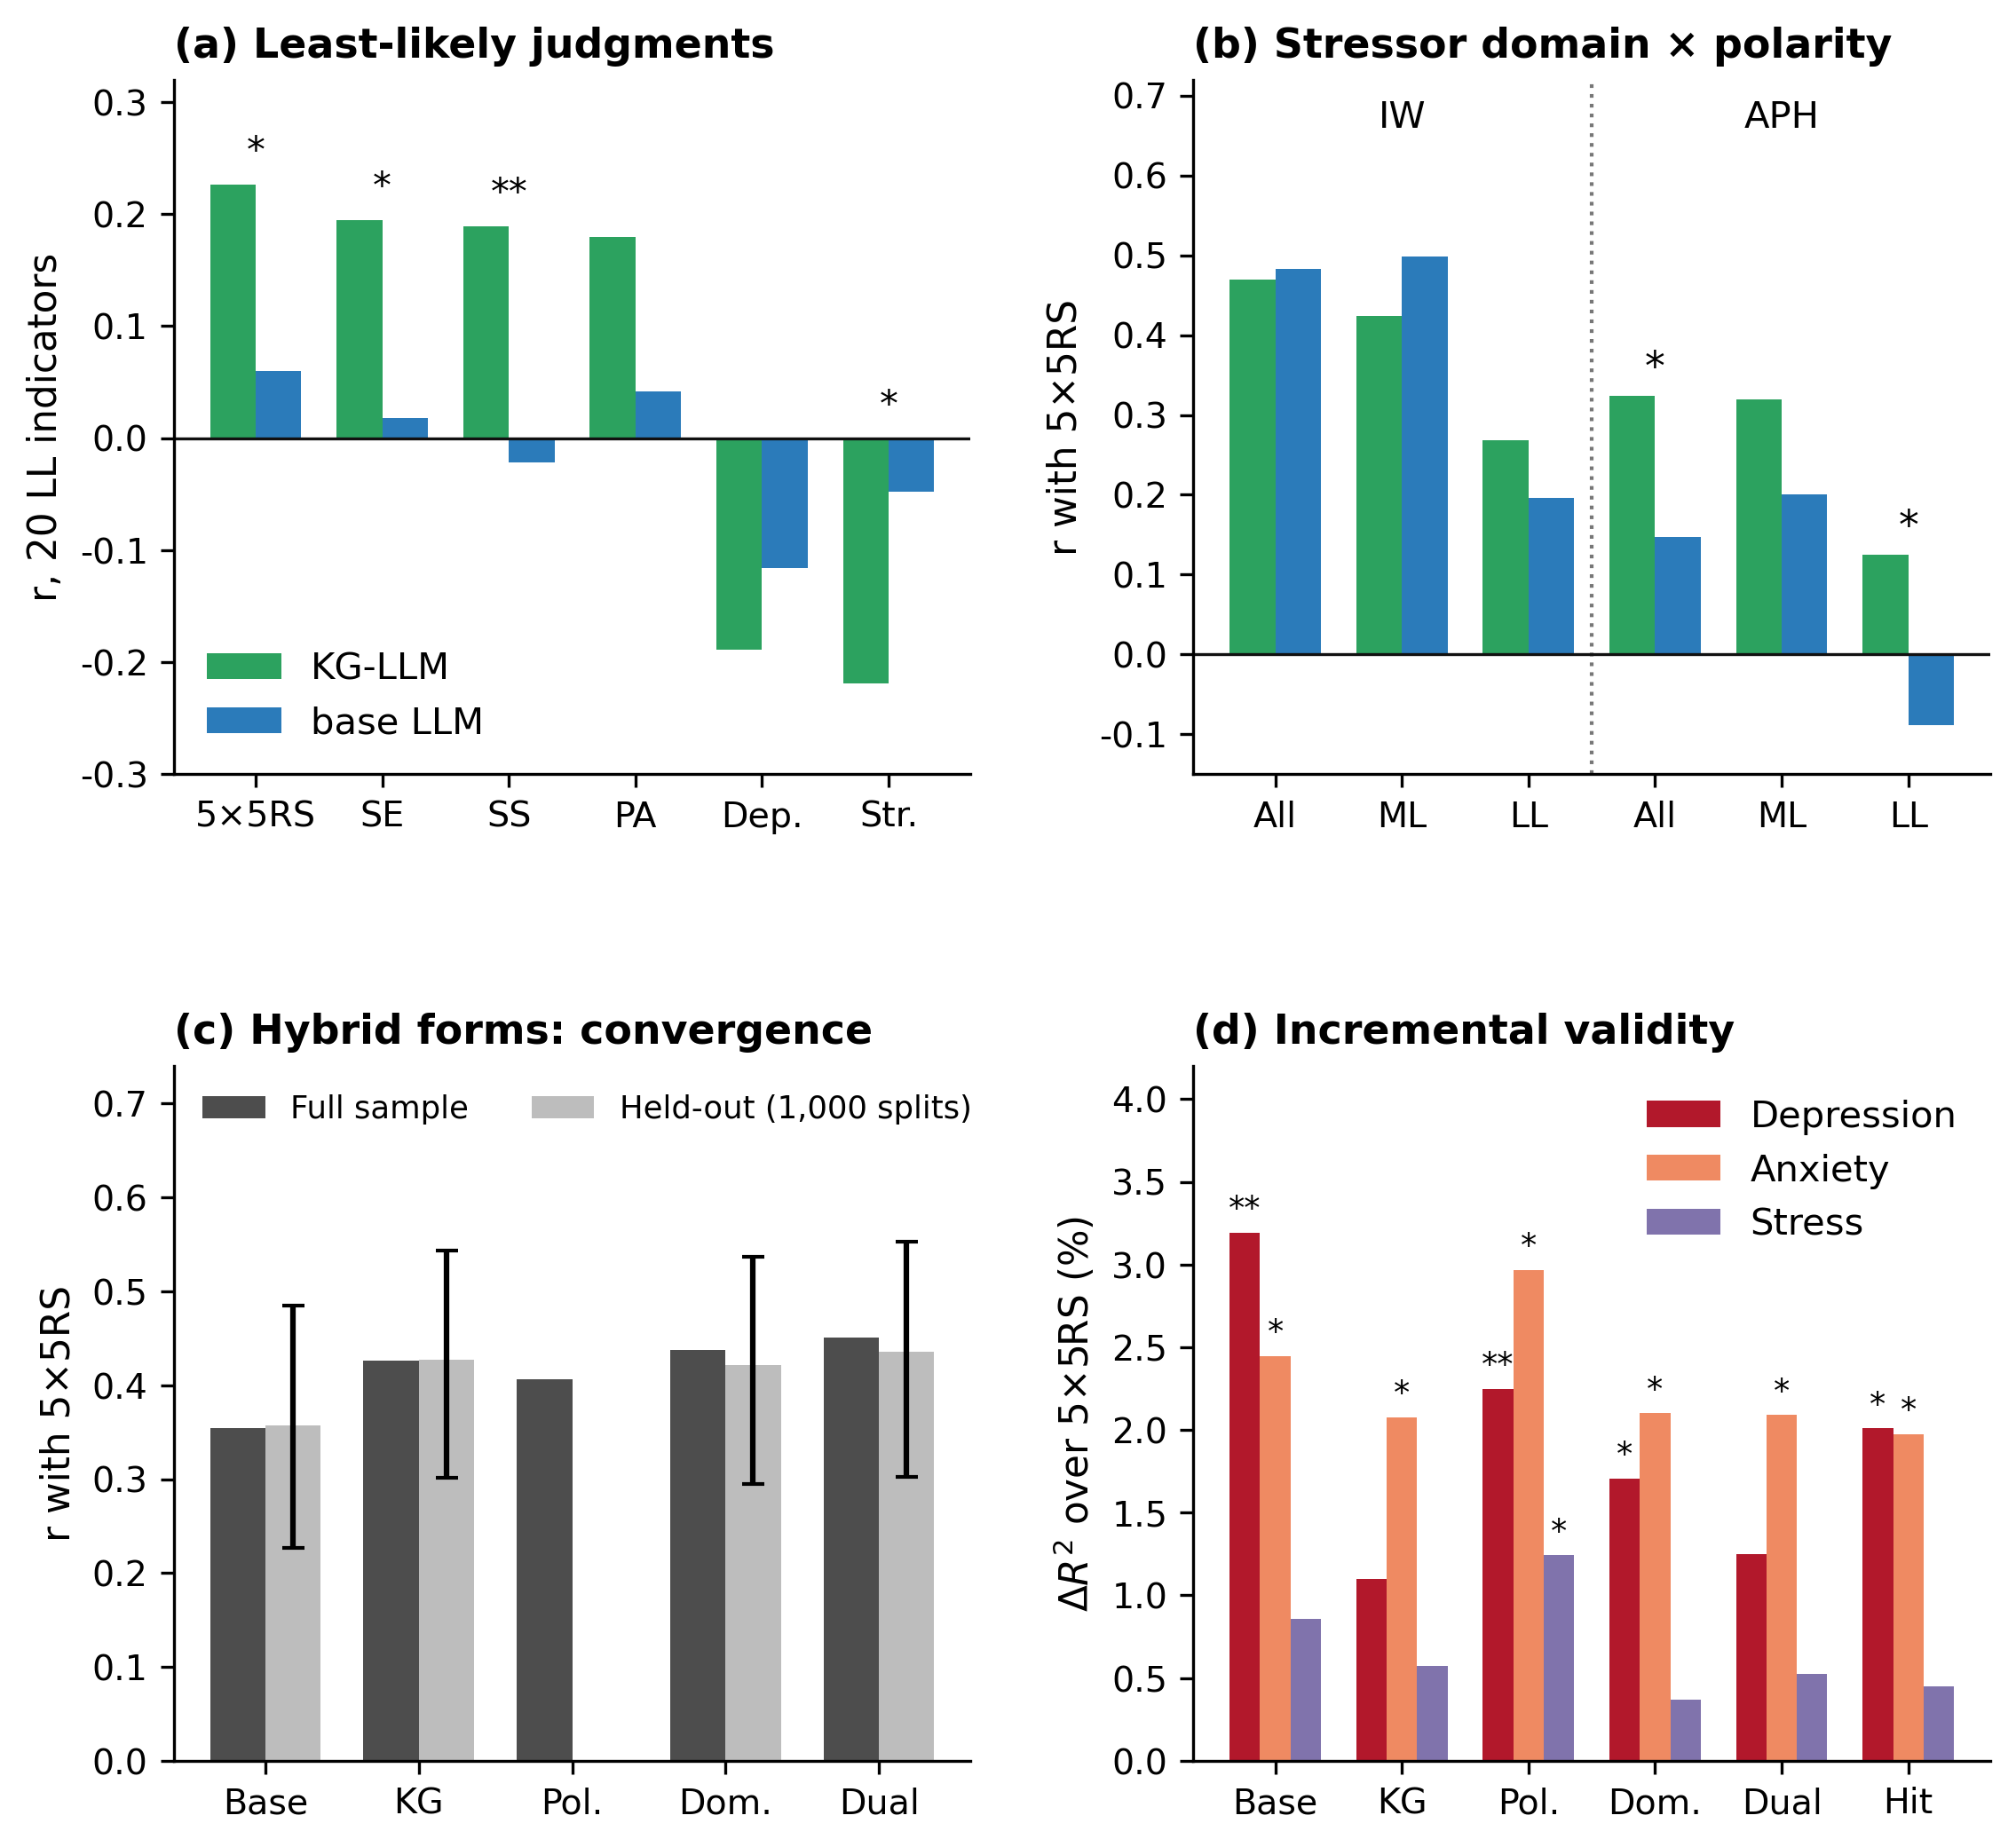

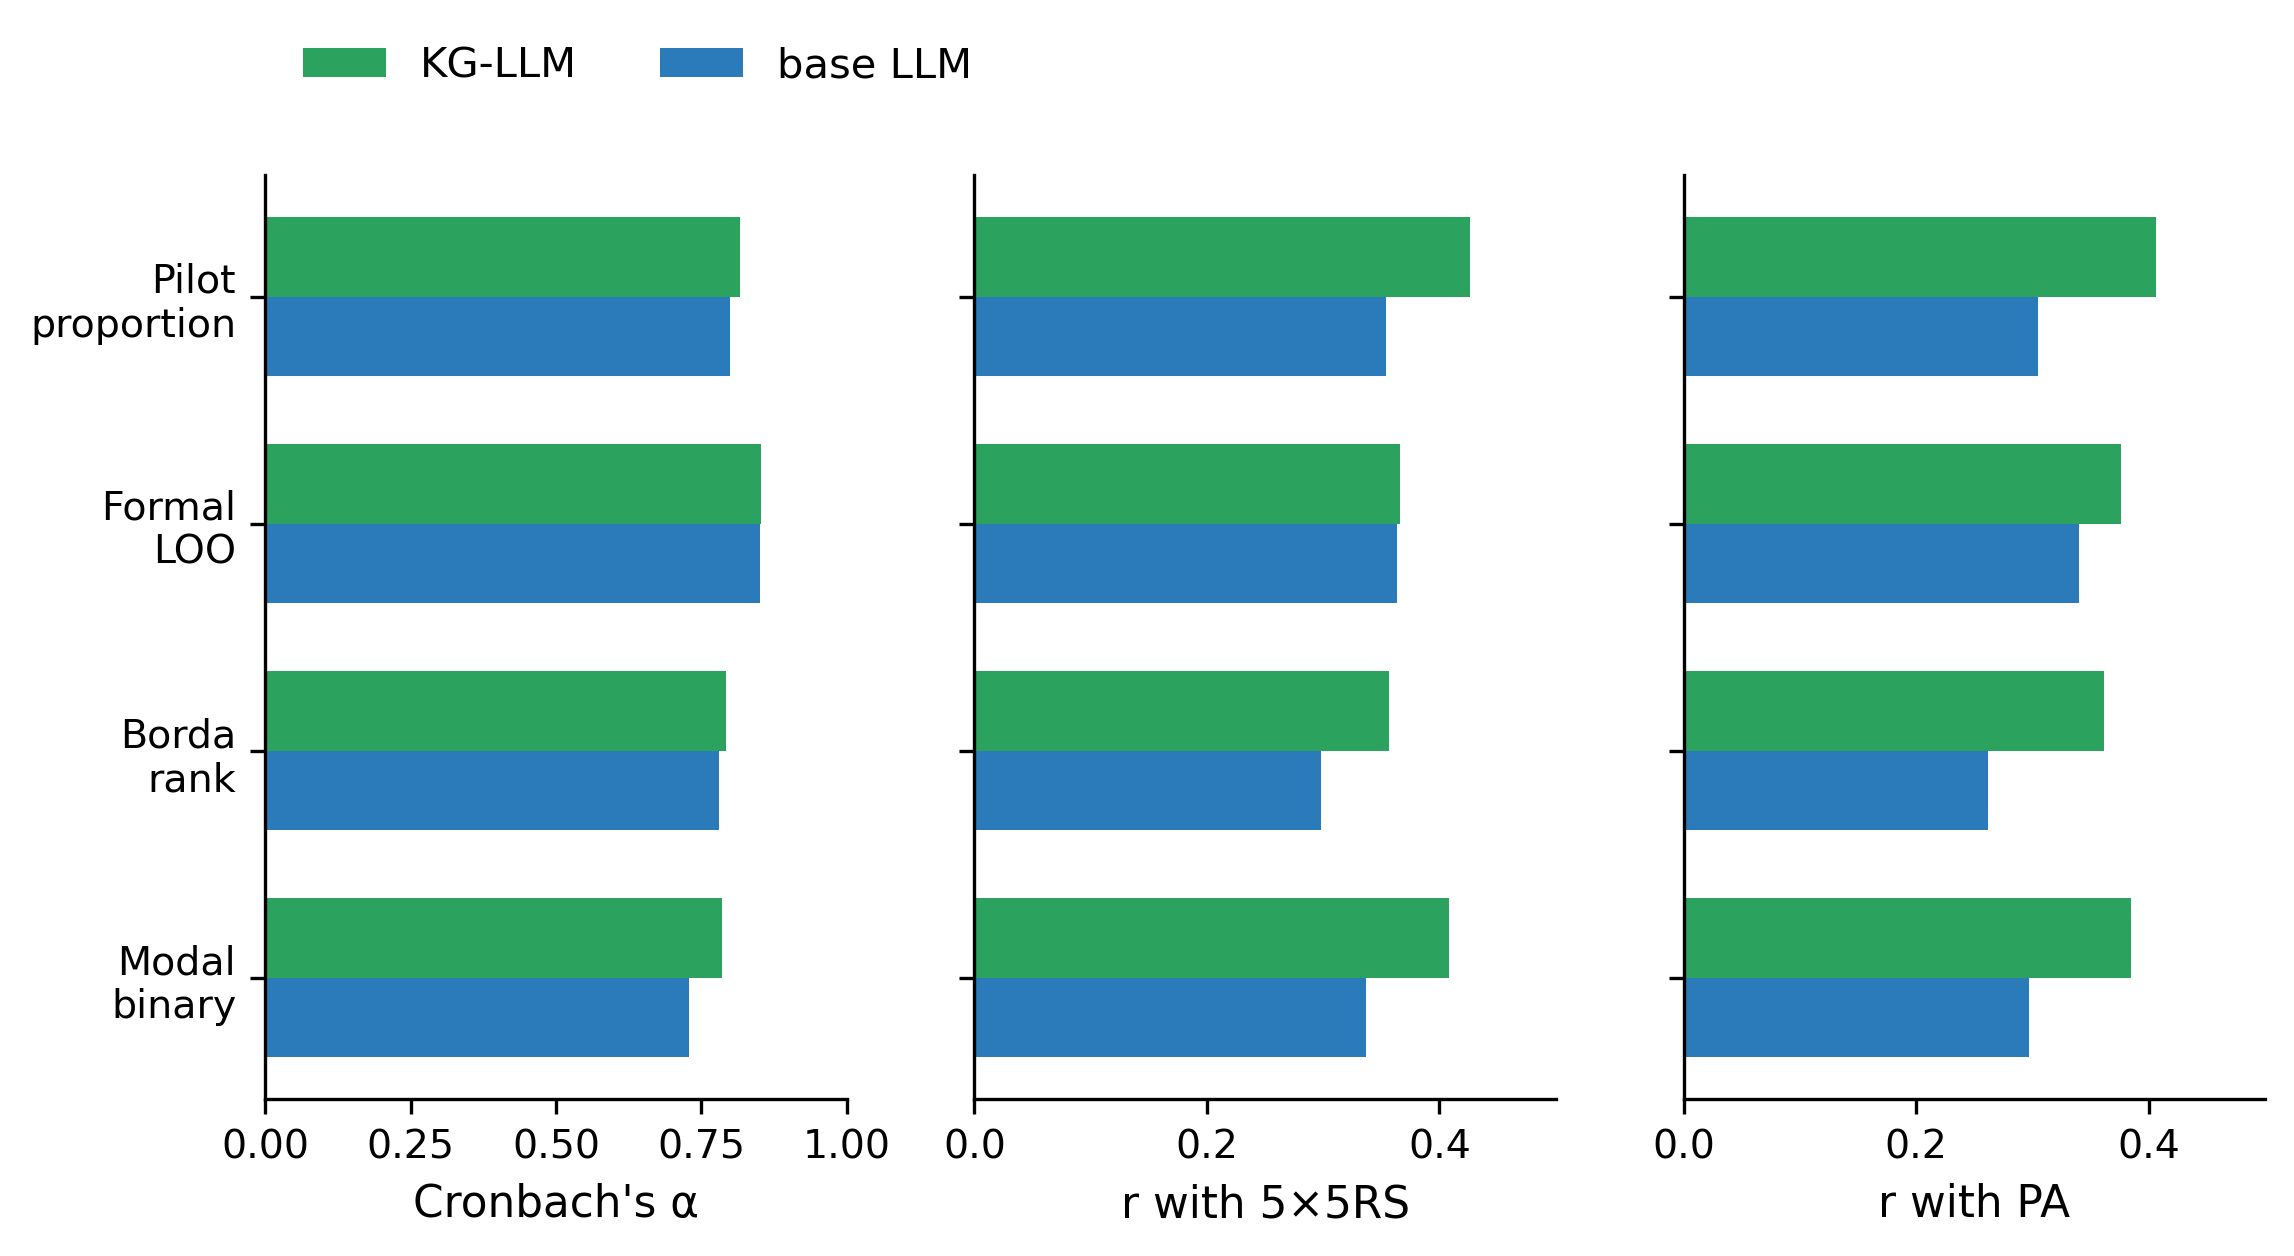

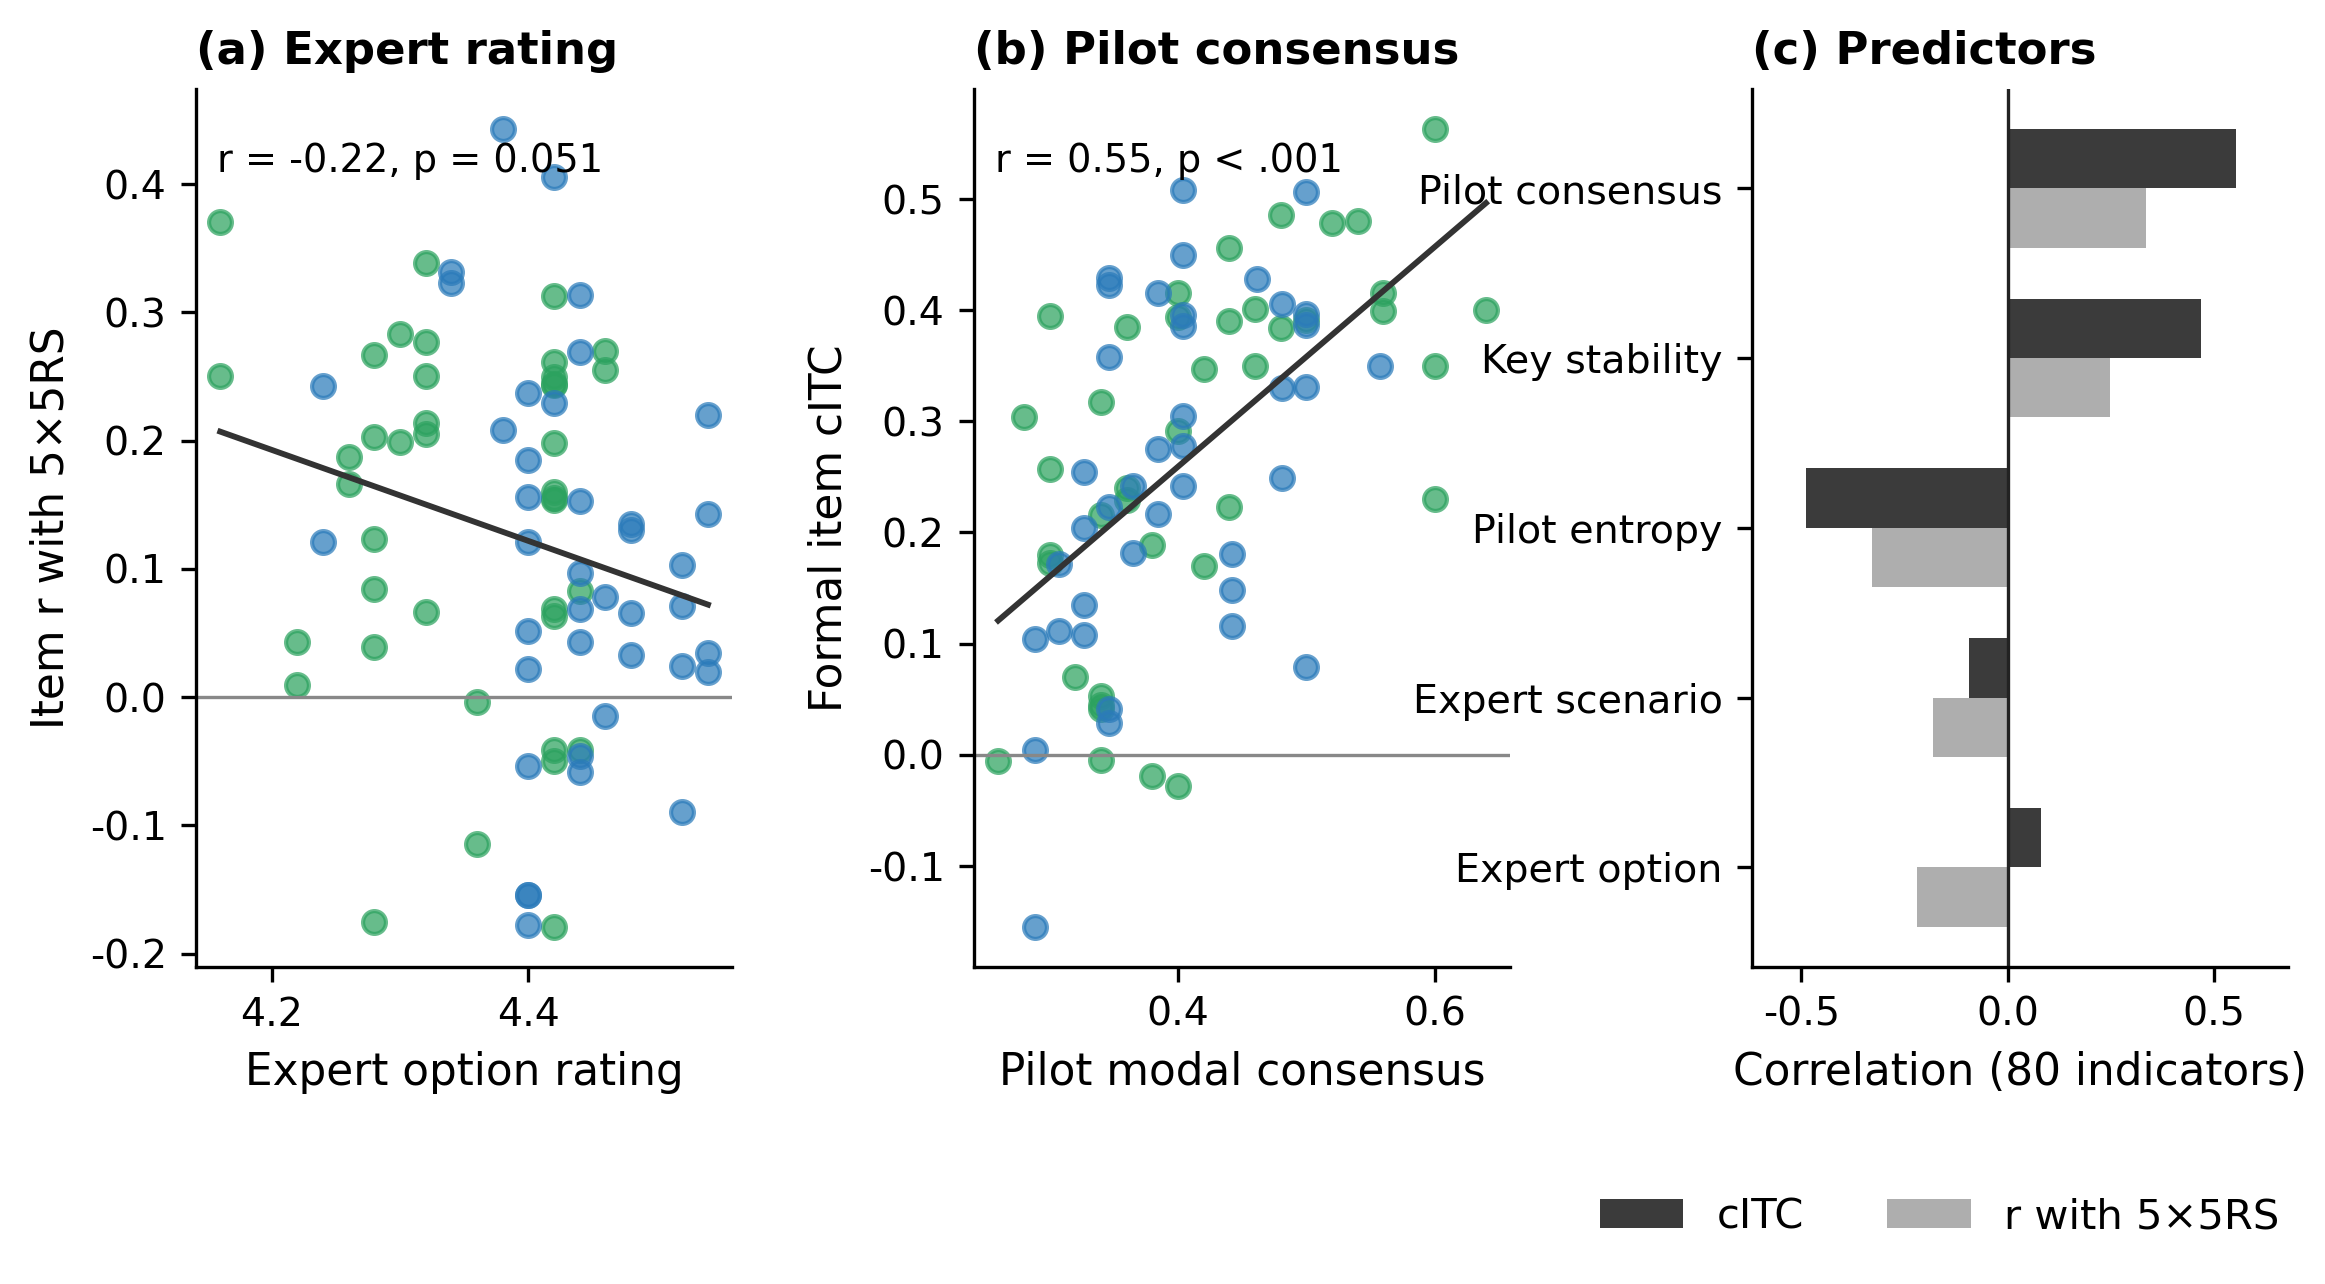

In [8]:
r8 = results["s08"]

print("=== Appendix D.8.5: Alternative Scoring Keys ===")
print(r8["alternative_keys"].round(3).to_string(index=False))

db = r8["double_bootstrap"]
print("\n=== 2,000-Resample Pilot + Formal Double Bootstrap ===")
print(f"  Full-40 delta_alpha     = {db['d_alpha_mean']:+.3f} [{db['d_alpha_lo']:+.3f}, {db['d_alpha_hi']:+.3f}], p = {db['d_alpha_p']:.3f}")
print(f"  Full-40 delta_r(5x5RS)  = {db['d_r40_mean']:+.3f} [{db['d_r40_lo']:+.3f}, {db['d_r40_hi']:+.3f}], p = {db['d_r40_p']:.3f}")
print(f"  APH-24  delta_r(5x5RS)  = {db['d_raph_mean']:+.3f} [{db['d_raph_lo']:+.3f}, {db['d_raph_hi']:+.3f}], p = {db['d_raph_p']:.3f}")

cf = r8["cross_fitted_keys"]
print("\n=== 1,000-Split Same-Sample 2-Fold Cross-Fitted Consensus Keys (75/75 inside N = 150) ===")
print(f"  Full-40 alpha           = {cf['alpha_kg']:.3f} (KG) vs. {cf['alpha_llm']:.3f} (base)")
print(f"  Full-40 r(5x5RS)        = {cf['r40_kg']:.3f} vs. {cf['r40_llm']:.3f} (diff = {cf['r40_diff']:+.3f} [{cf['r40_diff_lo']:+.3f}, {cf['r40_diff_hi']:+.3f}])")
print(f"  Full-40 r(PA)           = {cf['rpa_kg']:.3f} vs. {cf['rpa_llm']:.3f} (diff = {cf['rpa_diff']:+.3f} [{cf['rpa_diff_lo']:+.3f}, {cf['rpa_diff_hi']:+.3f}])")
print(f"  Domain crossover        : IW = {cf['riw_kg']:.3f} vs. {cf['riw_llm']:.3f} ({cf['riw_diff']:+.3f}) | APH = {cf['raph_kg']:.3f} vs. {cf['raph_llm']:.3f} ({cf['raph_diff']:+.3f})")
print(f"  LL-20 sensitivity       : {cf['rll_kg']:.3f} vs. {cf['rll_llm']:.3f}")

print("\n=== Table D4b: 2 x 2 (Polarity x Stressor Domain) Moderation & BH-FDR ===")
print(r8["moderation_8tests"].round(3).to_string(index=False))
print(f"  Domain x Condition interaction   : dd_r = {r8['interaction_domain']['dd_r']:+.3f} [{r8['interaction_domain']['ci_lo']:+.3f}, {r8['interaction_domain']['ci_hi']:+.3f}], p = {r8['interaction_domain']['p']:.3f}")
print(f"  Polarity x Condition interaction : dd_r = {r8['interaction_polarity']['dd_r']:+.3f} [{r8['interaction_polarity']['ci_lo']:+.3f}, {r8['interaction_polarity']['ci_hi']:+.3f}], p = {r8['interaction_polarity']['p']:.3f}")

print("\n=== Table D4c: Hybrid SJT Assemblies (Full Sample & 1,000-Split Held-Out CV) & DualHit ===")
cols_d4c = ["architecture", "scenarios", "chinese_chars", "alpha", "r_5x5rs", "cv_mean", "p_vs_base", "p_vs_kg", "dr2_dep", "dr2_anx", "dr2_str"]
print(r8["table_d4c"][cols_d4c].round(3).to_string(index=False))

print("\n=== Table D6g: Cross-Stage Correlations (80 Indicators & 40 Scenarios) ===")
print(r8["cross_stage_table"].round(3).to_string(index=False))
zn = r8["zero_trait_null"]
print(f"  Zero-trait multinomial null (2,000 reps): r(PilotMax, cITC_40) = {zn['r_citc_mean']:.3f} [{zn['r_citc_lo']:.3f}, {zn['r_citc_hi']:.3f}]")

fig13_path = FIG_DIR / "fig13_moderation_and_hybrids.png"
figD3_path = FIG_DIR / "figD3_alternative_scoring_keys.png"
figD4_path = FIG_DIR / "figD4_cross_stage_associations.png"
fig_part2.plot_fig13(r8, fig13_path)
fig_part2.plot_figD3(r8, figD3_path)
fig_part2.plot_figD4(r8, figD4_path)
for p in (fig13_path, figD3_path, figD4_path):
    display(Image(filename=str(p), width=680))

## 9. Automated Verification Against All 156 Reported Manuscript Values

In [9]:
df_ver = verify_reported_values.verify(results)
n_pass = int((df_ver["status"] == "PASS").sum())
n_tot = len(df_ver)
print(f"=== Verification Complete: {n_pass} / {n_tot} ({n_pass / n_tot * 100:.1f}%) Benchmark Values PASS ===")
assert n_pass == n_tot, "Verification mismatch detected!"
print("Saved detailed report to: outputs/verification_report.md")
print("\nSample of verified benchmark metrics:")
print(df_ver.head(25).to_string(index=False))

=== Verification Complete: 156 / 156 (100.0%) Benchmark Values PASS ===
Saved detailed report to: outputs/verification_report.md

Sample of verified benchmark metrics:
                     metric_id  reported_value  recomputed_value  abs_diff  tolerance status
        corpus_total_sentences     24603.00000       24603.00000  0.000000     0.0500   PASS
              corpus_rag_top_k      6000.00000        6000.00000  0.000000     0.0500   PASS
      corpus_cleaned_sentences      4714.00000        4714.00000  0.000000     0.0500   PASS
      rebel_nonempty_sentences      2593.00000        2593.00000  0.000000     0.0500   PASS
   deepseek_accepted_unchanged        28.00000          28.00000  0.000000     0.0500   PASS
deepseek_reextracted_sentences      2501.00000        2501.00000  0.000000     0.0500   PASS
  deepseek_replacement_triples      5666.00000        5666.00000  0.000000     0.0500   PASS
             deepseek_raw_rows      5758.00000        5758.00000  0.000000     0.0500   